<div style="font-size: 13px; line-height: 1.6;">

# 📚 Table of Contents

**1. Environment Setup & Configuration**
   - 1.1 Library Imports
   - 1.2 Global Configuration (Table 1.1)

**2. Data Acquisition & Dataset Configuration**
   - 2.1 Google Drive Mount & Dataset Extraction
   - 2.2 Dataset Path Configuration
   - 2.3 Reusable Data Loader & Validator
   - 2.4 Ocular Disease Dataset
   - 2.5 Ocular Fundus Image For Disease Detection
   - 2.6 Ocular Disease Recognition (ODIR-5K) — keyword → target mapping

**3. Master Dataset Construction & Patient-Aware Split**

**4. Exploratory Data Analysis (EDA)**
   - 4.1 Univariate · 4.2 Bivariate · 4.3 Multivariate

**5. Advanced Medical Image Preprocessing Pipeline**
   - 5.1 Figure — Circular Auto-Cropping & Retina Background Masking

**6. Automated Blur / Focus Detection (Quality Control)**
   - 6.1 Visual Threshold Confirmation · 6.2 Final Threshold · 6.3 Re-Split · 6.4 Clean Dataset Statistics

**7. Offline Caching & Efficient Data Pipeline**
   - 7.1 Offline Caching of Preprocessed Images (.npy) · 7.2 Multi-Label Data Generator

**8. Model Architecture & Loss Function**
   - 8.1 Backbone Selection — DenseNet121 (Proposed), ResNet50 & EfficientNetB0 (Comparison)
   - 8.2 Attention Module — CBAM (Ablation Variant)
   - 8.3 Model Builder
   - 8.4 Loss Function — Asymmetric Loss (ASL)

**9. Two-Phase Training of the Proposed Model (DenseNet121)**
   - 9.1 Phase 1 — Frozen Backbone · 9.2 Phase 1 — Validation Results · 9.3 Phase 2 — Fine-Tuning

**10. Comprehensive Evaluation of the Proposed Model**
   - 10.1 Train / Validation / Test Performance · 10.2 Per-Class Precision, Recall & F1 · 10.3 Test-Set Curves & Confusion Matrices

**11. Explainable AI (XAI) & Error Analysis**
   - 11.1 Grad-CAM · 11.2 Confidence Score · 11.3 Error Analysis

**12. Comparative Study — DenseNet121 vs ResNet50 vs EfficientNetB0**
   - 12.1 Experimental Protocol · 12.2 Experiment Runner & Reporting Tools · 12.3 Running the Experiments · 12.4 Quantitative Results · 12.5 Figures

**13. Ablation Study — Effect of CBAM Attention**
   - 13.1 Design · 13.2 Running the Ablation · 13.3 Quantitative Results · 13.4 Figures & Grad-CAM Comparison

**14. Summary of Findings & Reproducibility**
   - 14.1 Consolidated Results & Key Findings · 14.2 Reproducibility Statement

</div>

<div style="font-size: 13px; line-height: 1.6;">

# 🩺 Multi-Label Ocular Disease Classification from Retinal Fundus Images
**DenseNet121 with Asymmetric Loss and Two-Phase Transfer Learning — including a Comparative Backbone Study and a CBAM Ablation Study**

**Objective.** Detect five ocular conditions — *Normal, Diabetic Retinopathy, Glaucoma, Cataract* and *Other* — from a single fundus photograph as a multi-label problem, using three public datasets merged into one leakage-free master dataset.

**Contributions of this work**
1. **Multi-source data integration** — *Ocular Disease Dataset*, *Ocular Disease Recognition (ODIR-5K)* and *Ocular Fundus Image For Disease Detection* are mapped to one 5-class multi-label schema and split patient-aware (70/15/15) with a zero-leakage guardrail.
2. **Medical image preprocessing** — circular auto-crop, bilateral denoising and blended CLAHE (Ben Graham illumination normalization was deliberately excluded because it smooths away lesion contrast).
3. **Resolution-independent quality control** — masked Laplacian-variance focus scoring on size-standardized images, visual threshold confirmation and a single filtering pass.
4. **Proposed model** — ImageNet-pretrained DenseNet121 with a custom head, trained in two phases (frozen → fine-tuned) with Asymmetric Loss for class imbalance; decision thresholds are tuned on the validation set and frozen for the test set.
5. **Comparative study** — DenseNet121 vs ResNet50 vs EfficientNetB0 under an identical training and evaluation protocol (Section 12).
6. **Ablation study** — contribution of CBAM attention (channel-only, spatial-only, full CBAM) on top of DenseNet121 (Section 13).
7. **Explainability** — Grad-CAM heatmaps, entropy-based confidence and error analysis (Section 11).

> **Where to run.** The notebook detects its runtime: on **Google Colab** it mounts Drive and extracts the zip files; **locally** (e.g. VS Code with a Python 3.12 kernel) it reads the three dataset folders next to the notebook and writes everything to `./outputs`. Full training needs a GPU, so use Colab for Sections 9 and 12–13.
>
> **How to run.** Run Sections 1–8 first (data, cache, generators, model builder, loss). Sections 9–11 reproduce the development run of the proposed model. Sections 12–13 are long-running training studies: every result is saved to `EXPERIMENT_DIR` on Google Drive and finished experiments are skipped, so they resume safely after a Colab disconnect. Section 14 consolidates everything into publication-ready tables (CSV / Markdown / LaTeX) and figures (PNG / PDF, 300 dpi).

</div>

<div style="font-size: 13px; line-height: 1.6;">

## 1. Environment Setup & Configuration
### 1.1 Library Imports
<span style="font-size: 0.9em;">সব প্রয়োজনীয় লাইব্রেরি একবারে ইমপোর্ট করা হচ্ছে (নিচে কোথাও</span> repeat <span style="font-size: 0.9em;">করা হয়নি</span>)।

</div>

In [3]:
# ---- Core ----
import os
import gc
import hashlib
import json
import time
import platform
import sys
import shutil
import numpy as np
import pandas as pd

# ---- Visualization ----
import matplotlib.pyplot as plt
from matplotlib.container import BarContainer
import seaborn as sns
from IPython.display import display, Markdown

# ---- Image handling ----
import cv2
from PIL import Image

# ---- ML / DL ----
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, roc_curve, auc, precision_recall_curve, average_precision_score,
    precision_score, recall_score, f1_score, hamming_loss, accuracy_score,
    classification_report, multilabel_confusion_matrix,
)
import tensorflow as tf
from tensorflow.keras.utils import Sequence
from tensorflow.keras.applications import DenseNet121, ResNet50, EfficientNetB0
from tensorflow.keras.layers import Input, Layer, Dense, Conv2D, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau, EarlyStopping

pd.set_option('display.max_colwidth', 80)
print("✅ All libraries imported.")

✅ All libraries imported.


<div style="font-size: 13px; line-height: 1.6;">

### 1.2 Global Configuration
<span style="font-size: 0.9em;">নিচের ভ্যারিয়েবলগুলো পুরো নোটবুক জুড়ে ব্যবহার হবে। এখানে পরিবর্তন করলেই পুরো পাইপলাইনে প্রভাব পড়বে — কোথাও</span> hidden/hardcoded <span style="font-size: 0.9em;">ভ্যালু নেই</span>।

</div>

<div style="font-size: 13px; line-height: 1.6;">

#### Table 1.1 — Global Configuration & Training Hyperparameters

| Parameter | Value | Description / Usage |
| :--- | :--- | :--- |
| **`IN_COLAB`** | auto | `True` on Google Colab (Drive + extracted zips), `False` locally (dataset folders next to the notebook) |
| **`STORAGE_ROOT`** | auto | Colab: `/content/drive/MyDrive` · local: `./outputs` — all checkpoints, cache, figures and results go here |
| **`IMG_SIZE`** | `(224, 224)` | Model input image resolution |
| **`BATCH_SIZE`** | `32` | Images per batch |
| **`NUM_CLASSES`** | `5` | Multi-label targets (Normal, DR, Glaucoma, Cataract, Other) |
| **`RANDOM_STATE`** | `42` | Seed for splits and the development run |
| **`BLUR_RESIZE_DIM`** | `512` | Standard resolution before Laplacian-variance focus scoring |
| **`BLUR_SAMPLE_PREVIEW`** | `20` | Random previews for confirming the blur threshold |
| **`INITIAL_LR`** | `1e-4` | Phase 1 learning rate (frozen backbone) |
| **`EPOCHS_PHASE1`** | `5` | Phase 1 epochs |
| **`PHASE2_LR`** | `1e-5` | Phase 2 learning rate (fine-tuning) |
| **`EPOCHS_PHASE2`** | `20` (max) | Phase 2 epochs (EarlyStopping usually stops earlier) |
| **`EARLY_STOP_PATIENCE`** | `3` | Phase 2 EarlyStopping patience (val loss) |
| **`ASL_GAMMA_NEG_PHASE1` / `_PHASE2`** | `4` / `3` | Asymmetric Loss focusing on easy negatives |
| **`ASL_GAMMA_POS`** | `0` | Asymmetric Loss focusing on positives |
| **`CBAM_REDUCTION_RATIO`** | `16` | CBAM channel-MLP reduction ratio *r* (ablation) |
| **`CBAM_KERNEL_SIZE`** | `7` | CBAM spatial-attention kernel size *k* (ablation) |
| **`EXPERIMENT_SEEDS`** | `[42]` | Seeds per comparative/ablation experiment (e.g. `[42, 123, 2024]` → mean ± std) |
| **`N_BOOTSTRAP`** | `1000` | Bootstrap resamples for 95% CIs and paired significance tests |
| **`CACHE_DIR`** | Drive folder | Offline cache of preprocessed images (`uint8` `.npy`, one file per image) |
| **`EXPERIMENT_DIR`** | Drive folder | Where Sections 12–14 store weights, predictions, tables and figures |

</div>

In [4]:
# ---- Runtime: Google Colab (GPU + Google Drive) or a local machine (e.g. VS Code) ----
IN_COLAB = 'google.colab' in sys.modules
DATASET_NAMES = ['Ocular Disease Dataset', 'Ocular Disease Recognition', 'Ocular Fundus Image For Disease Detection']

if IN_COLAB:
    STORAGE_ROOT = '/content/drive/MyDrive'                    # persistent Google Drive storage
    GOOGLE_DRIVE_ZIP_ROOT = os.path.join(STORAGE_ROOT, 'dataset(1)')
    ZIP_PATHS = [os.path.join(GOOGLE_DRIVE_ZIP_ROOT, f'{name}.zip') for name in DATASET_NAMES]
    EXTRACTION_ROOT = '/content/ocular_extracted'              # zips are extracted to fast local disk
    dataset_parents = [EXTRACTION_ROOT] * len(DATASET_NAMES)   # every zip extracts into the same root
else:
    STORAGE_ROOT = os.path.join(os.getcwd(), 'outputs')        # local stand-in for Google Drive
    dataset_parents = [os.path.join(os.getcwd(), name) for name in DATASET_NAMES]  # folders next to the notebook

OCULAR_DISEASE_DIR = os.path.join(dataset_parents[0], 'preprocessed')
ODIR_BASE_DIR      = os.path.join(dataset_parents[1], 'ODIR-5K')
OCULAR_FUNDUS_DIR  = os.path.join(dataset_parents[2], 'augmented')

# ---- Model / training hyperparameters ----
IMG_SIZE          = (224, 224)   # Model input size
BATCH_SIZE        = 32
INITIAL_LR        = 1e-4
EPOCHS_PHASE1      = 5
NUM_CLASSES        = 5            # [Normal, DR, Glaucoma, Cataract, Other]
RANDOM_STATE       = 42

# ---- Blur / focus detection ----
BLUR_RESIZE_DIM     = 512         # standardize every image to this size before scoring (fixes inconsistent variance scale)
BLUR_SAMPLE_PREVIEW = 20          # how many unique random images to visually show per run

# ---- Checkpoints (saved to STORAGE_ROOT so they persist across Colab sessions) ----
CHECKPOINT_DIR         = os.path.join(STORAGE_ROOT, 'ocular_model_checkpoints')
CHECKPOINT_PATH        = os.path.join(CHECKPOINT_DIR, 'densenet121_ocular_best.keras')    # Phase 1
CHECKPOINT_PATH_PHASE2 = os.path.join(CHECKPOINT_DIR, 'densenet121_phase2_best.keras')   # Phase 2
RESULTS_FIGURE_DIR     = os.path.join(STORAGE_ROOT, 'ocular_figures')                    # Section 10-11 figures

# ---- Offline cache of preprocessed images (Section 7.1) ----
CACHE_DIR = os.path.join(STORAGE_ROOT, 'ocular_cached_images_v2')   # v2 = without Ben Graham normalization

# ---- Phase 2 (fine-tuning) & loss ----
PHASE2_LR            = 1e-5
EPOCHS_PHASE2        = 20          # maximum; EarlyStopping usually stops earlier
EARLY_STOP_PATIENCE  = 3
ASL_GAMMA_NEG_PHASE1 = 4
ASL_GAMMA_NEG_PHASE2 = 3
ASL_GAMMA_POS        = 0

# ---- Comparative study & ablation study (Sections 12-14) ----
EXPERIMENT_DIR       = os.path.join(STORAGE_ROOT, 'ocular_experiments')
EXPERIMENT_SEEDS     = [42]        # e.g. [42, 123, 2024] to report mean ± std
CBAM_REDUCTION_RATIO = 16
CBAM_KERNEL_SIZE     = 7
N_BOOTSTRAP          = 1000

print(f"✅ Config loaded. Runtime: {'Google Colab' if IN_COLAB else 'local machine'} | outputs -> {STORAGE_ROOT}")

✅ Config loaded. Runtime: local machine | outputs -> c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\outputs


<div style="font-size: 13px; line-height: 1.6;">

## 2. Data Acquisition & Dataset Configuration
### 2.1 Google Drive Mount & Dataset Extraction
Kaggle <span style="font-size: 0.9em;">এর বদলে</span> Google Drive-<span style="font-size: 0.9em;">এ থাকা তিনটি</span> zip <span style="font-size: 0.9em;">ফাইল</span> Colab-<span style="font-size: 0.9em;">এর লোকাল স্টোরেজে (দ্রুত</span> read-<span style="font-size: 0.9em;">এর জন্য) একবারে এক্সট্রাক্ট করা হচ্ছে</span>।

</div>

In [5]:
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
else:
    print("Local run: Google Drive is not needed — datasets are read from the project folder.")

Local run: Google Drive is not needed — datasets are read from the project folder.


In [6]:
def extract_zip_if_needed(zip_name, zip_root, extraction_root):
    """Extracts a single zip file from Google Drive into the Colab local disk,
    but skips re-extraction if already done (saves time on repeated runs)."""
    zip_path = os.path.join(zip_root, zip_name)
    if not os.path.exists(zip_path):
        print(f"❌ {zip_name} not found at {zip_path}. Please verify the path.")
        return False
    print(f"Unzipping {zip_name}...")
    os.system(f'unzip -o "{zip_path}" -d {extraction_root} > /dev/null')
    print(f"✅ {zip_name} extracted.")
    return True

if IN_COLAB:
    os.makedirs(EXTRACTION_ROOT, exist_ok=True)
    print(f"Extracting datasets from {GOOGLE_DRIVE_ZIP_ROOT} -> {EXTRACTION_ROOT}\n")
    for zf in ZIP_PATHS:
        extract_zip_if_needed(zf, GOOGLE_DRIVE_ZIP_ROOT, EXTRACTION_ROOT)
    print("\n--- Listing extracted top-level folders ---")
    print(os.listdir(EXTRACTION_ROOT))
else:
    print("Local run: datasets are already unpacked next to the notebook — nothing to extract.")

Local run: datasets are already unpacked next to the notebook — nothing to extract.


<div style="font-size: 13px; line-height: 1.6;">

### 2.2 Dataset Path Configuration
<span style="font-size: 0.9em;">এক্সট্রাক্ট হওয়া তিনটি ডেটাসেটের নির্দিষ্ট সাব-ফোল্ডার পাথ ঠিক করা হচ্ছে</span>।

- **Ocular Disease Dataset** (`Ocular Disease Dataset.zip`) → `preprocessed/` <span style="font-size: 0.9em;">ফোল্ডার-ভিত্তিক ক্লাস</span> (N, D, G, C, A, H, M)
- **Ocular Disease Recognition (ODIR-5K)** (`Ocular Disease Recognition.zip`) → `ODIR-5K/` — Excel <span style="font-size: 0.9em;">মেটাডেটা</span> + <span style="font-size: 0.9em;">ইমেজ</span>
- **Ocular Fundus Image For Disease Detection** (`Ocular Fundus Image For Disease Detection.zip`) → `augmented/` <span style="font-size: 0.9em;">ফোল্ডার-ভিত্তিক ক্লাস</span>

</div>

<div style="font-size: 13px; line-height: 1.6;">

#### Breakdown of the Multi-Source Datasets

This project integrates three distinct datasets to create a robust, diverse, and large-scale master dataset for ocular disease classification. Here is the breakdown:

**1. Ocular Disease Dataset**
*   **Format:** Preprocessed images organized in class-specific subfolders (`N`, `D`, `G`, `C`, `A`, `H`, `M`).
*   **Processing:** Folder names are directly mapped to our 5-class multi-label target vector (`[Normal, DR, Glaucoma, Cataract, Other]`).
*   **Contribution:** ~10,449 images.
*   **Patient Leakage Handling:** Each image is treated as an independent patient ID.

**2. Ocular Disease Recognition (ODIR-5K)**
*   **Format:** Complex metadata (Excel/CSV) containing free-text patient-level diagnostic keywords, with separate image files for the left and right eyes.
*   **Processing:** A custom NLP mapping function (`keywords_to_targets`) parses the clinical text to generate precise multi-label vectors for each eye.
*   **Contribution:** ~6,691 usable images (after dropping all-zero unmapped targets).
*   **Patient Leakage Handling:** True patient IDs are retained to guarantee that a single patient's left and right eyes do not leak across Train/Val/Test splits.

**3. Ocular Fundus Image For Disease Detection**
*   **Format:** Augmented images organized in class-specific folders (`normal`, `glaucoma`, `cataract`, `Retinoblastoma`).
*   **Processing:** Folders mapped to the 5-class target scheme. (Irrelevant classes like Retinoblastoma are safely ignored).
*   **Contribution:** ~3,714 images.
*   **Patient Leakage Handling:** Each image is treated as an independent patient ID.

</div>

In [7]:
# Dataset roots (OCULAR_DISEASE_DIR, ODIR_BASE_DIR, OCULAR_FUNDUS_DIR) come from the Config cell.
# Ocular Disease Recognition (ODIR-5K): metadata + images
ODIR_METADATA_DIR  = os.path.join(ODIR_BASE_DIR, "ODIR-5K")
ODIR_TRAIN_IMG_DIR = os.path.join(ODIR_METADATA_DIR, "Training Images")
ODIR_TEST_IMG_DIR  = os.path.join(ODIR_METADATA_DIR, "Testing Images")

print("--- Verified Dataset Paths ---")
for name, path in [
    ("Ocular Disease Dataset",    OCULAR_DISEASE_DIR),
    ("ODIR-5K metadata",          ODIR_METADATA_DIR),
    ("ODIR-5K train images",      ODIR_TRAIN_IMG_DIR),
    ("ODIR-5K test images",       ODIR_TEST_IMG_DIR),
    ("Ocular Fundus (augmented)", OCULAR_FUNDUS_DIR),
]:
    print(f"{name:28s} -> exists={os.path.exists(path):<6} {path}")

missing = [path for path in (OCULAR_DISEASE_DIR, ODIR_METADATA_DIR, ODIR_TRAIN_IMG_DIR, ODIR_TEST_IMG_DIR, OCULAR_FUNDUS_DIR)
           if not os.path.exists(path)]
if missing:
    raise FileNotFoundError(f"Dataset folders not found: {missing}")

# Output folders (after the Drive mount, so they are created on Drive in Colab)
for d in (CHECKPOINT_DIR, CACHE_DIR, EXPERIMENT_DIR, RESULTS_FIGURE_DIR):
    os.makedirs(d, exist_ok=True)

--- Verified Dataset Paths ---
Ocular Disease Dataset       -> exists=1      c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\Ocular Disease Dataset\preprocessed
ODIR-5K metadata             -> exists=1      c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\Ocular Disease Recognition\ODIR-5K\ODIR-5K
ODIR-5K train images         -> exists=1      c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\Ocular Disease Recognition\ODIR-5K\ODIR-5K\Training Images
ODIR-5K test images          -> exists=1      c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\Ocular Disease Recognition\ODIR-5K\ODIR-5K\Testing Images
Ocular Fundus (augmented)    -> exists=1      c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\Ocular Fundus Image For Disease Detection\augmented


<div style="font-size: 13px; line-height: 1.6;">

### 2.3 Reusable Data Loader & Validator
`build_dataframe_from_class_folders`: <span style="font-size: 0.9em;">যেকোনো ফোল্ডার-ভিত্তিক</span> (class-per-folder) <span style="font-size: 0.9em;">ডেটাসেটকে</span> DataFrame-<span style="font-size: 0.9em;">এ রূপান্তর করে</span>। Ocular Disease Dataset <span style="font-size: 0.9em;">এবং</span> Ocular Fundus Image For Disease Detection <span style="font-size: 0.9em;">দুটোর জন্যই এটা ব্যবহার হবে</span>।

</div>

In [8]:
def build_dataframe_from_class_folders(base_dir, folder_map, source_tag):
    """Walks a directory of class-named subfolders and builds a DataFrame of
    (filename, target_list, source) rows.

    Args:
        base_dir:   root directory containing one subfolder per class
        folder_map: dict mapping folder_name -> multi-label target vector (list)
        source_tag: string tag to mark which dataset a row came from
    """
    rows = []
    skipped_folders = []

    if not os.path.exists(base_dir):
        print(f"[{source_tag}] ❌ base_dir does not exist: {base_dir}")
        return pd.DataFrame(columns=['filename', 'target_list', 'source'])

    for folder_name in sorted(os.listdir(base_dir)):
        folder_path = os.path.join(base_dir, folder_name)
        if not os.path.isdir(folder_path):
            continue
        if folder_name not in folder_map:
            skipped_folders.append(folder_name)
            continue

        target_vector = folder_map[folder_name]
        for fname in os.listdir(folder_path):
            if fname.lower().endswith(('.jpg', '.jpeg', '.png')):
                rows.append({
                    'filename': os.path.join(folder_path, fname),
                    'target_list': np.array(target_vector, dtype=np.float32),
                    'source': source_tag
                })

    if skipped_folders:
        print(f"[{source_tag}] Ignored folders (not in folder_map): {skipped_folders}")

    return pd.DataFrame(rows)


def validate_dataset_files(df, dataset_name, check_every=1000):
    """Single reusable validator used for ALL datasets:
    1) Confirms every filepath exists on disk.
    2) Opens every image to confirm it isn't corrupted.
    Drops any missing/corrupt rows and returns the cleaned DataFrame.
    """
    n_initial = len(df)
    print(f"[{dataset_name}] Validating existence of {n_initial} files...")

    exists_mask = df['filename'].apply(os.path.exists)
    n_missing = (~exists_mask).sum()
    if n_missing > 0:
        print(f"[{dataset_name}] ❌ MISSING: {n_missing} files dropped.")
        df = df[exists_mask].reset_index(drop=True)
    else:
        print(f"[{dataset_name}] ✅ All files exist on disk.")

    n_to_check = len(df)
    print(f"[{dataset_name}] Checking {n_to_check} files for corruption...")
    corrupt_mask = np.zeros(len(df), dtype=bool)
    for idx, path in enumerate(df['filename']):
        try:
            with Image.open(path) as img:
                img.verify()
        except Exception:
            corrupt_mask[idx] = True
        if (idx + 1) % check_every == 0:
            print(f"  Checked {idx + 1}/{n_to_check}...")

    n_corrupt = corrupt_mask.sum()
    if n_corrupt > 0:
        print(f"[{dataset_name}] ❌ CORRUPT: {n_corrupt} unreadable files dropped.")
        df = df[~corrupt_mask].reset_index(drop=True)
    else:
        print(f"[{dataset_name}] ✅ All files readable.")

    print(f"[{dataset_name}] Final clean count: {len(df)} / {n_initial}\n")
    return df


def visual_spot_check(df, dataset_name, max_classes=5):
    """Single reusable visual sanity-check used for ALL datasets:
    shows one random sample image per unique target class so you can
    confirm folder -> label mapping is correct.
    """
    unique_targets = df['target_list'].apply(tuple).unique()[:max_classes]
    fig, axes = plt.subplots(1, len(unique_targets), figsize=(3 * len(unique_targets), 3))
    if len(unique_targets) == 1:
        axes = [axes]

    for ax, target_tuple in zip(axes, unique_targets):
        target_list = list(target_tuple)
        matches = df[df['target_list'].apply(lambda x: np.array_equal(x, target_list))]
        sample_row = matches.sample(1).iloc[0]
        folder_name = os.path.basename(os.path.dirname(sample_row['filename']))

        img = Image.open(sample_row['filename'])
        ax.imshow(img)
        ax.set_title(f"Folder: {folder_name}\nTarget: {target_list}", fontsize=8)
        ax.axis('off')

    plt.suptitle(f"{dataset_name}: Folder vs Target Verification", y=1.05)
    plt.tight_layout()
    plt.show()

print("✅ Reusable loader / validator / visual-check functions defined.")

✅ Reusable loader / validator / visual-check functions defined.


<div style="font-size: 13px; line-height: 1.6;">

### 2.4 Loading the Ocular Disease Dataset (Preprocessed Folders)
<span style="font-size: 0.9em;">ফোল্ডার নাম থেকে সরাসরি ক্লাস লেবেল বের করা হচ্ছে</span>: `N`=Normal, `D`=Diabetic Retinopathy, `G`=Glaucoma, `C`=Cataract, `A/H/M`=Other।

</div>

In [9]:
ocular_disease_map = {
    'N': [1, 0, 0, 0, 0],
    'D': [0, 1, 0, 0, 0],
    'G': [0, 0, 1, 0, 0],
    'C': [0, 0, 0, 1, 0],
    'A': [0, 0, 0, 0, 1],
    'H': [0, 0, 0, 0, 1],
    'M': [0, 0, 0, 0, 1],
}

df_ocular_disease = build_dataframe_from_class_folders(OCULAR_DISEASE_DIR, ocular_disease_map, "ocular_disease_dataset")

if df_ocular_disease.empty:
    raise ValueError("Ocular Disease Dataset loaded 0 images. Please check the folder structure.")
print(f"✅ Ocular Disease Dataset loaded: {len(df_ocular_disease)} images")
display(df_ocular_disease.tail())

✅ Ocular Disease Dataset loaded: 10449 images


,filename,target_list,source
10444,c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\Ocular Disease Dataset\preproce...,"[1.0, 0.0, 0.0, 0.0, 0.0]",ocular_disease_dataset
10445,c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\Ocular Disease Dataset\preproce...,"[1.0, 0.0, 0.0, 0.0, 0.0]",ocular_disease_dataset
10446,c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\Ocular Disease Dataset\preproce...,"[1.0, 0.0, 0.0, 0.0, 0.0]",ocular_disease_dataset
10447,c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\Ocular Disease Dataset\preproce...,"[1.0, 0.0, 0.0, 0.0, 0.0]",ocular_disease_dataset
10448,c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\Ocular Disease Dataset\preproce...,"[1.0, 0.0, 0.0, 0.0, 0.0]",ocular_disease_dataset


[Ocular Disease Dataset] Validating existence of 10449 files...
[Ocular Disease Dataset] ✅ All files exist on disk.
[Ocular Disease Dataset] Checking 10449 files for corruption...
  Checked 1000/10449...
  Checked 2000/10449...
  Checked 3000/10449...
  Checked 4000/10449...
  Checked 5000/10449...
  Checked 6000/10449...
  Checked 7000/10449...
  Checked 8000/10449...
  Checked 9000/10449...
  Checked 10000/10449...
[Ocular Disease Dataset] ✅ All files readable.
[Ocular Disease Dataset] Final clean count: 10449 / 10449



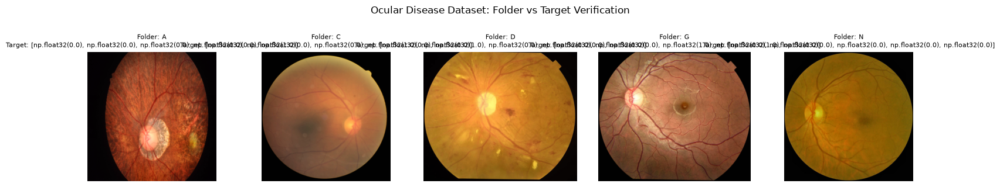

In [10]:
# Full existence + corruption validation, then a visual spot-check
df_ocular_disease = validate_dataset_files(df_ocular_disease, "Ocular Disease Dataset")
visual_spot_check(df_ocular_disease, "Ocular Disease Dataset")

<div style="font-size: 13px; line-height: 1.6;">

### 2.5 Loading the Ocular Fundus Image For Disease Detection Dataset (Augmented Folders)
`Retinoblastoma` <span style="font-size: 0.9em;">ক্লাসটি ইচ্ছাকৃতভাবে বাদ দেওয়া হয়েছে (আমাদের টার্গেট স্কিমার সাথে মেলে না</span>)।

</div>

In [11]:
ocular_fundus_map = {
    'normal': [1, 0, 0, 0, 0],
    'diabetic_retinopathy': [0, 1, 0, 0, 0],
    'glaucoma': [0, 0, 1, 0, 0],
    'cataract': [0, 0, 0, 1, 0],
}

df_ocular_fundus = build_dataframe_from_class_folders(OCULAR_FUNDUS_DIR, ocular_fundus_map, "ocular_fundus_detection")
print(f"✅ Ocular Fundus Image For Disease Detection loaded: {len(df_ocular_fundus)} images")
display(pd.Series([tuple(t) for t in df_ocular_fundus['target_list']]).value_counts())

[ocular_fundus_detection] Ignored folders (not in folder_map): ['Retinoblastoma']
✅ Ocular Fundus Image For Disease Detection loaded: 3714 images


(0.0, 0.0, 0.0, 1.0, 0.0)    1238
(0.0, 0.0, 1.0, 0.0, 0.0)    1238
(1.0, 0.0, 0.0, 0.0, 0.0)    1238
Name: count, dtype: int64

[Ocular Fundus Image For Disease Detection] Validating existence of 3714 files...
[Ocular Fundus Image For Disease Detection] ✅ All files exist on disk.
[Ocular Fundus Image For Disease Detection] Checking 3714 files for corruption...
  Checked 1000/3714...
  Checked 2000/3714...
  Checked 3000/3714...
[Ocular Fundus Image For Disease Detection] ✅ All files readable.
[Ocular Fundus Image For Disease Detection] Final clean count: 3714 / 3714



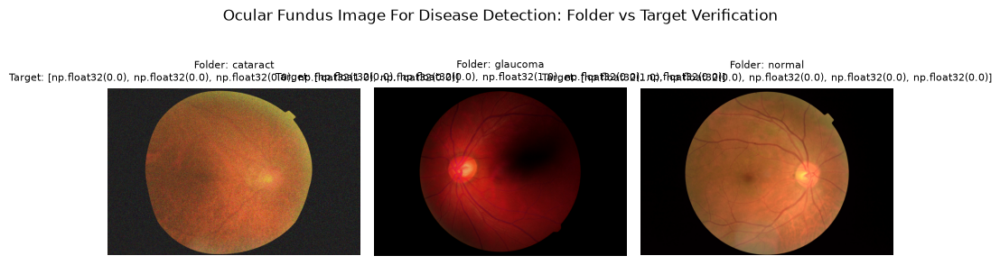

In [12]:
df_ocular_fundus = validate_dataset_files(df_ocular_fundus, "Ocular Fundus Image For Disease Detection")
visual_spot_check(df_ocular_fundus, "Ocular Fundus Image For Disease Detection")

<div style="font-size: 13px; line-height: 1.6;">

### 2.6 Loading the Ocular Disease Recognition (ODIR-5K) Dataset (Metadata-Based)
<span style="font-size: 0.9em;">এই ডেটাসেটটি একটু জটিল: একটি</span> Excel/CSV <span style="font-size: 0.9em;">ফাইলে</span> patient-level <span style="font-size: 0.9em;">ডায়াগনস্টিক কিওয়ার্ড আছে, যেটা থেকে</span> left/right eye <span style="font-size: 0.9em;">এর জন্য আলাদা ৫-ক্লাস টার্গেট ভেক্টর বানাতে হবে</span>।

</div>

In [13]:
# ---- Load metadata file ----
csv_files = [f for f in os.listdir(ODIR_METADATA_DIR) if f.endswith(('.csv', '.xlsx'))]
print(f"Detected metadata files: {csv_files}")

if not csv_files:
    raise FileNotFoundError(f"No metadata (.csv/.xlsx) found in {ODIR_METADATA_DIR}")

meta_path = os.path.join(ODIR_METADATA_DIR, csv_files[0])
df_odir_raw = pd.read_csv(meta_path) if meta_path.endswith('.csv') else pd.read_excel(meta_path)
print(f"✅ Metadata loaded: {df_odir_raw.shape}")
display(df_odir_raw.isnull().sum())

Detected metadata files: ['data.xlsx']
✅ Metadata loaded: (3500, 15)


ID                           0
Patient Age                  0
Patient Sex                  0
Left-Fundus                  0
Right-Fundus                 0
Left-Diagnostic Keywords     0
Right-Diagnostic Keywords    0
N                            0
D                            0
G                            0
C                            0
A                            0
H                            0
M                            0
O                            0
dtype: int64

<div style="font-size: 13px; line-height: 1.6;">

#### 2.6.1 Diagnostic Keywords → 5-Class Target Mapping
<span style="font-size: 0.9em;">ডায়াগনস্টিক টেক্সট (যেমন</span> `"proliferative retinopathy"`) <span style="font-size: 0.9em;">থেকে</span> `[Normal, DR, Glaucoma, Cataract, Other]` <span style="font-size: 0.9em;">ভেক্টর বানানো হচ্ছে</span>।

</div>

In [14]:
def keywords_to_targets(keyword_string):
    """Maps a free-text diagnostic keyword string to a 5-class multi-label
    target vector: [Normal, DR, Glaucoma, Cataract, Other]."""
    target = [0, 0, 0, 0, 0]
    if not isinstance(keyword_string, str) or keyword_string.strip() == '':
        return target

    text = keyword_string.lower()

    is_normal     = 'normal fundus' in text
    has_dr        = ('retinopathy' in text) or ('diabetic' in text)
    has_glaucoma  = 'glaucoma' in text
    has_cataract  = 'cataract' in text

    # "Other" catches AMD, hypertension, myopia, etc.
    other_flag_phrases = [
        'macular degeneration', 'hypertensive', 'myopia', 'drusen',
        'membrane', 'laser spot', 'spotted membranous change',
        'vessel tortuosity', 'chorioretinal atrophy', 'optic disc',
        'optic nerve', 'atrophy', 'edema', 'degeneration'
    ]
    has_other_condition = any(p in text for p in other_flag_phrases)

    if is_normal and not (has_dr or has_glaucoma or has_cataract or has_other_condition):
        target[0] = 1
    if has_dr:
        target[1] = 1
    if has_glaucoma:
        target[2] = 1
    if has_cataract:
        target[3] = 1
    if has_other_condition and not (has_dr or has_glaucoma or has_cataract):
        target[4] = 1

    return target


df_odir_raw['left_target']  = df_odir_raw['Left-Diagnostic Keywords'].apply(keywords_to_targets)
df_odir_raw['right_target'] = df_odir_raw['Right-Diagnostic Keywords'].apply(keywords_to_targets)
print("✅ 'left_target' / 'right_target' columns created.")
display(df_odir_raw[['Left-Diagnostic Keywords', 'left_target', 'Right-Diagnostic Keywords', 'right_target']].head())

✅ 'left_target' / 'right_target' columns created.


,Left-Diagnostic Keywords,left_target,Right-Diagnostic Keywords,right_target
0,cataract,"[0, 0, 0, 1, 0]",normal fundus,"[1, 0, 0, 0, 0]"
1,normal fundus,"[1, 0, 0, 0, 0]",normal fundus,"[1, 0, 0, 0, 0]"
2,laser spot，moderate non proliferative retinopathy,"[0, 1, 0, 0, 0]",moderate non proliferative retinopathy,"[0, 1, 0, 0, 0]"
3,normal fundus,"[1, 0, 0, 0, 0]",branch retinal artery occlusion,"[0, 0, 0, 0, 0]"
4,macular epiretinal membrane,"[0, 0, 0, 0, 1]",mild nonproliferative retinopathy,"[0, 1, 0, 0, 0]"


<div style="font-size: 13px; line-height: 1.6;">

#### 2.6.2 Per-Eye Expansion & Image Path Resolution

</div>

In [15]:
odir_rows = []
for _, row in df_odir_raw.iterrows():
    odir_rows.append({'filename_only': row['Left-Fundus'],  'target_list': row['left_target'],
                       'patient_id': row['ID'], 'eye': 'left'})
    odir_rows.append({'filename_only': row['Right-Fundus'], 'target_list': row['right_target'],
                       'patient_id': row['ID'], 'eye': 'right'})

df_odir_long = pd.DataFrame(odir_rows)
print(f"Expanded to {len(df_odir_long)} per-eye rows from {len(df_odir_raw)} patients")


def resolve_odir_image_path(filename_only):
    """ODIR images live in either the Training or Testing folder — check both."""
    train_path = os.path.join(ODIR_TRAIN_IMG_DIR, filename_only)
    test_path  = os.path.join(ODIR_TEST_IMG_DIR, filename_only)
    if os.path.exists(train_path):
        return train_path
    if os.path.exists(test_path):
        return test_path
    return None


df_odir_long['filename'] = df_odir_long['filename_only'].apply(resolve_odir_image_path)

# Drop rows where the image wasn't found, and rows with an all-zero target
df_odir5k = df_odir_long.dropna(subset=['filename']).copy()
df_odir5k['source'] = 'ocular_disease_recognition'
df_odir5k = df_odir5k[['filename', 'target_list', 'source', 'patient_id']]

n_before = len(df_odir5k)
df_odir5k = df_odir5k[df_odir5k['target_list'].apply(lambda t: sum(t) > 0)].reset_index(drop=True)
df_odir5k['target_list'] = df_odir5k['target_list'].apply(lambda x: np.array(x, dtype=np.float32))

print(f"Dropped {n_before - len(df_odir5k)} unlabeled rows (all-zero target).")
print(f"✅ Ocular Disease Recognition (ODIR-5K) final: {len(df_odir5k)} usable images")
display(df_odir5k.head())

Expanded to 7000 per-eye rows from 3500 patients
Dropped 309 unlabeled rows (all-zero target).
✅ Ocular Disease Recognition (ODIR-5K) final: 6691 usable images


,filename,target_list,source,patient_id
0,c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\Ocular Disease Recognition\ODIR...,"[0.0, 0.0, 0.0, 1.0, 0.0]",ocular_disease_recognition,0
1,c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\Ocular Disease Recognition\ODIR...,"[1.0, 0.0, 0.0, 0.0, 0.0]",ocular_disease_recognition,0
2,c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\Ocular Disease Recognition\ODIR...,"[1.0, 0.0, 0.0, 0.0, 0.0]",ocular_disease_recognition,1
3,c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\Ocular Disease Recognition\ODIR...,"[1.0, 0.0, 0.0, 0.0, 0.0]",ocular_disease_recognition,1
4,c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\Ocular Disease Recognition\ODIR...,"[0.0, 1.0, 0.0, 0.0, 0.0]",ocular_disease_recognition,2


[Ocular Disease Recognition (ODIR-5K)] Validating existence of 6691 files...


[Ocular Disease Recognition (ODIR-5K)] ✅ All files exist on disk.
[Ocular Disease Recognition (ODIR-5K)] Checking 6691 files for corruption...
  Checked 1000/6691...
  Checked 2000/6691...
  Checked 3000/6691...
  Checked 4000/6691...
  Checked 5000/6691...
  Checked 6000/6691...
[Ocular Disease Recognition (ODIR-5K)] ✅ All files readable.
[Ocular Disease Recognition (ODIR-5K)] Final clean count: 6691 / 6691



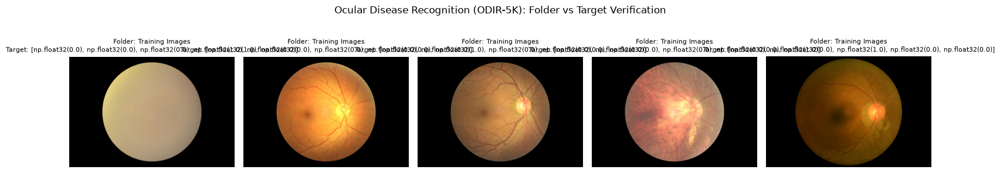

In [16]:
df_odir5k = validate_dataset_files(df_odir5k, "Ocular Disease Recognition (ODIR-5K)")
visual_spot_check(df_odir5k, "Ocular Disease Recognition (ODIR-5K)")

<div style="font-size: 13px; line-height: 1.6;">

#### 2.6.3 ODIR-5K Metadata EDA (Correlation Heatmap & Demographics)

</div>

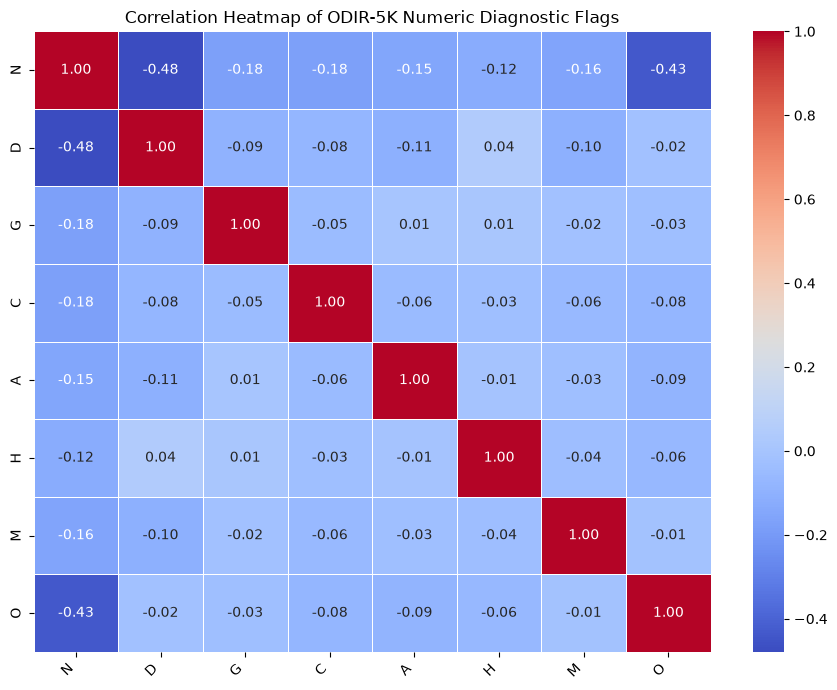

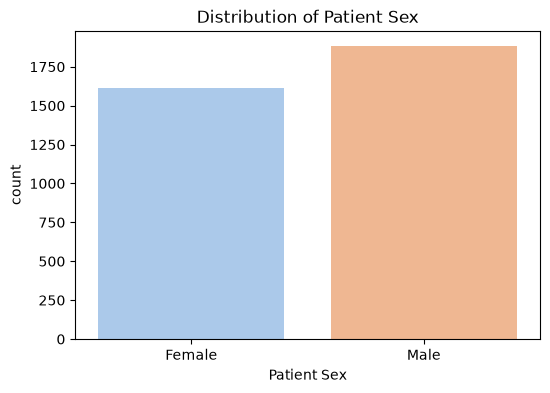

In [17]:
diagnostic_columns = ['N', 'D', 'G', 'C', 'A', 'H', 'M', 'O']
diagnostic_correlation = df_odir_raw[diagnostic_columns].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(diagnostic_correlation, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Heatmap of ODIR-5K Numeric Diagnostic Flags')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

if 'Patient Sex' in df_odir_raw.columns:
    plt.figure(figsize=(6, 4))
    sns.countplot(x='Patient Sex', data=df_odir_raw, hue='Patient Sex', palette='pastel', legend=False)
    plt.title('Distribution of Patient Sex')
    plt.show()

<div style="font-size: 13px; line-height: 1.6;">

## 3. Master Dataset Construction & Patient-Aware Split
<span style="font-size: 0.9em;">তিনটা ডেটাসেটকে একই স্কিমাতে</span> (`filename`, `target_list`, `source`, `patient_id`) <span style="font-size: 0.9em;">নিয়ে আসা হচ্ছে। এরপর</span> **Patient-Aware Split** <span style="font-size: 0.9em;">ব্যবহার করা হচ্ছে যাতে একই রোগীর একাধিক ছবি ভিন্ন</span> split-<span style="font-size: 0.9em;">এ</span> (train/val/test) <span style="font-size: 0.9em;">না যায় — এটা</span> data leakage <span style="font-size: 0.9em;">রোধ করে</span>।

</div>

In [18]:
# ---- Assign patient_id (Ocular Disease Dataset & Ocular Fundus: each image is its own patient; ODIR-5K: use real patient IDs) ----
df_ocular_disease['patient_id'] = df_ocular_disease['filename']          # each image = unique patient
df_ocular_fundus['patient_id'] = df_ocular_fundus['filename']          # each image = unique patient
df_odir5k['patient_id'] = 'odir_' + df_odir5k['patient_id'].astype(str)  # namespaced to avoid ID clashes

expected_cols = ['filename', 'target_list', 'source', 'patient_id']

# ---- Schema validation ----
for name, df in [("Ocular Disease Dataset", df_ocular_disease), ("Ocular Disease Recognition (ODIR-5K)", df_odir5k), ("Ocular Fundus Image For Disease Detection", df_ocular_fundus)]:
    missing_cols = [c for c in expected_cols if c not in df.columns]
    if missing_cols:
        raise ValueError(f"Missing columns in {name}: {missing_cols}")
print("✅ Schema validated for all 3 datasets.")

# ---- Enforce float32 numpy arrays (required by Keras multi-label loss) ----
for df in (df_ocular_disease, df_odir5k, df_ocular_fundus):
    df['target_list'] = df['target_list'].apply(lambda x: np.array(x, dtype=np.float32))

# ---- Concatenate + shuffle ----
df_master = pd.concat(
    [df_ocular_disease[expected_cols], df_odir5k[expected_cols], df_ocular_fundus[expected_cols]],
    ignore_index=True
).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

print(f"Ocular Disease Dataset:                    {len(df_ocular_disease)} images")
print(f"Ocular Disease Recognition (ODIR-5K):      {len(df_odir5k)} images")
print(f"Ocular Fundus Image For Disease Detection: {len(df_ocular_fundus)} images")
print(f"TOTAL (df_master):                         {len(df_master)} images")
display(df_master.head())

✅ Schema validated for all 3 datasets.
Ocular Disease Dataset:                    10449 images
Ocular Disease Recognition (ODIR-5K):      6691 images
Ocular Fundus Image For Disease Detection: 3714 images
TOTAL (df_master):                         20854 images


,filename,target_list,source,patient_id
0,c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\Ocular Disease Dataset\preproce...,"[0.0, 0.0, 1.0, 0.0, 0.0]",ocular_disease_dataset,c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\Ocular Disease Dataset\preproce...
1,c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\Ocular Disease Recognition\ODIR...,"[0.0, 0.0, 0.0, 1.0, 0.0]",ocular_disease_recognition,odir_2236
2,c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\Ocular Disease Dataset\preproce...,"[0.0, 0.0, 0.0, 1.0, 0.0]",ocular_disease_dataset,c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\Ocular Disease Dataset\preproce...
3,c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\Ocular Disease Dataset\preproce...,"[1.0, 0.0, 0.0, 0.0, 0.0]",ocular_disease_dataset,c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\Ocular Disease Dataset\preproce...
4,c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\Ocular Disease Dataset\preproce...,"[0.0, 0.0, 1.0, 0.0, 0.0]",ocular_disease_dataset,c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\Ocular Disease Dataset\preproce...


In [19]:
# ---- Patient-aware Train/Val/Test split (70/15/15) ----
unique_patients = df_master['patient_id'].unique()
print(f"Total unique patient identities: {len(unique_patients)}")

train_val_ids, test_ids = train_test_split(unique_patients, test_size=0.15, random_state=RANDOM_STATE)
train_ids, val_ids = train_test_split(train_val_ids, test_size=(0.15 / 0.85), random_state=RANDOM_STATE)

train_df = df_master[df_master['patient_id'].isin(train_ids)].reset_index(drop=True)
val_df   = df_master[df_master['patient_id'].isin(val_ids)].reset_index(drop=True)
test_df  = df_master[df_master['patient_id'].isin(test_ids)].reset_index(drop=True)

print(f"Train Set: {len(train_df)} images ({len(train_df)/len(df_master)*100:.1f}%)")
print(f"Val Set:   {len(val_df)} images ({len(val_df)/len(df_master)*100:.1f}%)")
print(f"Test Set:  {len(test_df)} images ({len(test_df)/len(df_master)*100:.1f}%)")

# ---- Leakage verification (guardrail) ----
train_patients, val_patients, test_patients = set(train_df['patient_id']), set(val_df['patient_id']), set(test_df['patient_id'])
assert not (train_patients & val_patients),  "FATAL LEAKAGE: Train & Val share patients!"
assert not (train_patients & test_patients), "FATAL LEAKAGE: Train & Test share patients!"
assert not (val_patients & test_patients),   "FATAL LEAKAGE: Val & Test share patients!"
print("\n✅ VERIFIED: Perfect patient isolation. No data leakage.")

Total unique patient identities: 17633
Train Set: 14585 images (69.9%)
Val Set:   3141 images (15.1%)
Test Set:  3128 images (15.0%)

✅ VERIFIED: Perfect patient isolation. No data leakage.


<div style="font-size: 13px; line-height: 1.6;">

## 4. Exploratory Data Analysis (EDA)
<span style="font-size: 0.9em;">কম্বাইন্ড মাস্টার ডেটাসেটের উপর ৩ ধরনের</span> EDA <span style="font-size: 0.9em;">করা হচ্ছে</span>:
- **4.1 Univariate** — <span style="font-size: 0.9em;">একটা করে ভ্যারিয়েবল আলাদাভাবে</span> (patient uniqueness, source distribution, target class distribution)
- **4.2 Bivariate** — <span style="font-size: 0.9em;">দুইটা ভ্যারিয়েবলের সম্পর্ক</span> (source vs target_labels)
- **4.3 Multivariate** — <span style="font-size: 0.9em;">একাধিক ভ্যারিয়েবলের সম্পর্ক</span> (disease co-occurrence correlation)

</div>

<div style="font-size: 13px; line-height: 1.6;">

### 4.1 Univariate Analysis
<span style="font-size: 0.9em;">প্রতিটা ভ্যারিয়েবল আলাদাভাবে দেখা হচ্ছে</span>: unique patient <span style="font-size: 0.9em;">সংখ্যা ও ডুপ্লিকেট চেক, তারপর</span> source <span style="font-size: 0.9em;">ও</span> target class-<span style="font-size: 0.9em;">এর নিজস্ব</span> distribution।

</div>

In [20]:
# ---- Basic shape / info ----
print("--- df_master Info ---")
df_master.info()
print("\n--- Null Values ---")
display(df_master.isnull().sum())

# ---- Patient ID uniqueness & duplicate check ----
num_unique_patients = df_master['patient_id'].nunique()
print(f"\nNumber of unique patients: {num_unique_patients}")

duplicate_pairs = df_master.duplicated(subset=['patient_id', 'filename']).sum()
print(f"Duplicate (patient_id, filename) pairs: {duplicate_pairs}")
if duplicate_pairs > 0:
    display(df_master[df_master.duplicated(subset=['patient_id', 'filename'], keep=False)]
            .sort_values(by=['patient_id', 'filename']).head())
else:
    print("✅ No duplicate (patient_id, filename) pairs found.")

--- df_master Info ---
<class 'pandas.DataFrame'>
RangeIndex: 20854 entries, 0 to 20853
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   filename     20854 non-null  str   
 1   target_list  20854 non-null  object
 2   source       20854 non-null  str   
 3   patient_id   20854 non-null  str   
dtypes: object(1), str(3)
memory usage: 651.8+ KB

--- Null Values ---


filename       0
target_list    0
source         0
patient_id     0
dtype: int64


Number of unique patients: 17633
Duplicate (patient_id, filename) pairs: 0
✅ No duplicate (patient_id, filename) pairs found.


<div style="font-size: 13px; line-height: 1.6;">

Source <span style="font-size: 0.9em;">ও</span> target class-<span style="font-size: 0.9em;">এর নিজস্ব</span> (univariate) distribution:

</div>

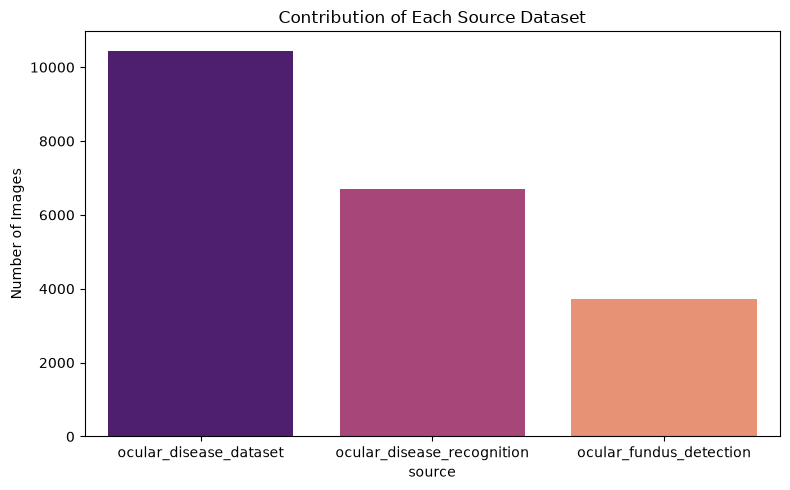

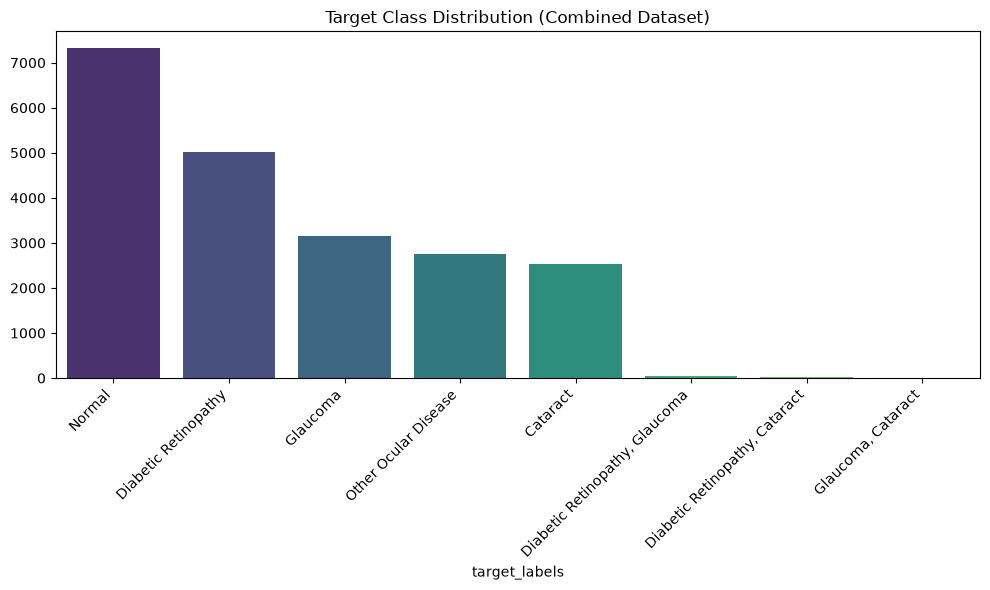

In [21]:
def get_target_labels(target_vector):
    names = ['Normal', 'Diabetic Retinopathy', 'Glaucoma', 'Cataract', 'Other Ocular Disease']
    labels = [name for flag, name in zip(target_vector, names) if flag == 1]
    return ', '.join(labels) if labels else 'No Finding'

df_master['target_labels'] = df_master['target_list'].apply(get_target_labels)

# ---- Source contribution ----
source_counts = df_master['source'].value_counts()
plt.figure(figsize=(8, 5))
sns.barplot(x=source_counts.index, y=source_counts.values, hue=source_counts.index,
            palette='magma', legend=False)
plt.title('Contribution of Each Source Dataset')
plt.ylabel('Number of Images')
plt.tight_layout()
plt.show()

# ---- Target class distribution ----
target_counts = df_master['target_labels'].value_counts()
plt.figure(figsize=(10, 6))
sns.barplot(x=target_counts.index, y=target_counts.values, hue=target_counts.index,
            palette='viridis', legend=False)
plt.title('Target Class Distribution (Combined Dataset)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

<div style="font-size: 13px; line-height: 1.6;">

### 4.2 Bivariate Analysis: Source vs Target Distribution
<span style="font-size: 0.9em;">প্রতিটা</span> source dataset-<span style="font-size: 0.9em;">এ কোন</span> disease class <span style="font-size: 0.9em;">কতটা আছে তা একসাথে দেখা</span> — stacked bar (count) <span style="font-size: 0.9em;">এবং</span> proportion (normalized) <span style="font-size: 0.9em;">দুইভাবেই, যাতে বোঝা যায় কোনো একটা সোর্স কোনো নির্দিষ্ট ক্লাসের দিকে বেশি</span> skewed <span style="font-size: 0.9em;">কিনা</span>।

</div>

--- Target Distribution by Source Dataset (Counts) ---


target_labels,Cataract,Diabetic Retinopathy,"Diabetic Retinopathy, Cataract","Diabetic Retinopathy, Glaucoma",Glaucoma,"Glaucoma, Cataract",Normal,Other Ocular Disease
source,,,,,,,,
ocular_disease_dataset,1008,3128,0,0,1646,0,2997,1670
ocular_disease_recognition,292,1882,19,50,274,2,3095,1077
ocular_fundus_detection,1238,0,0,0,1238,0,1238,0


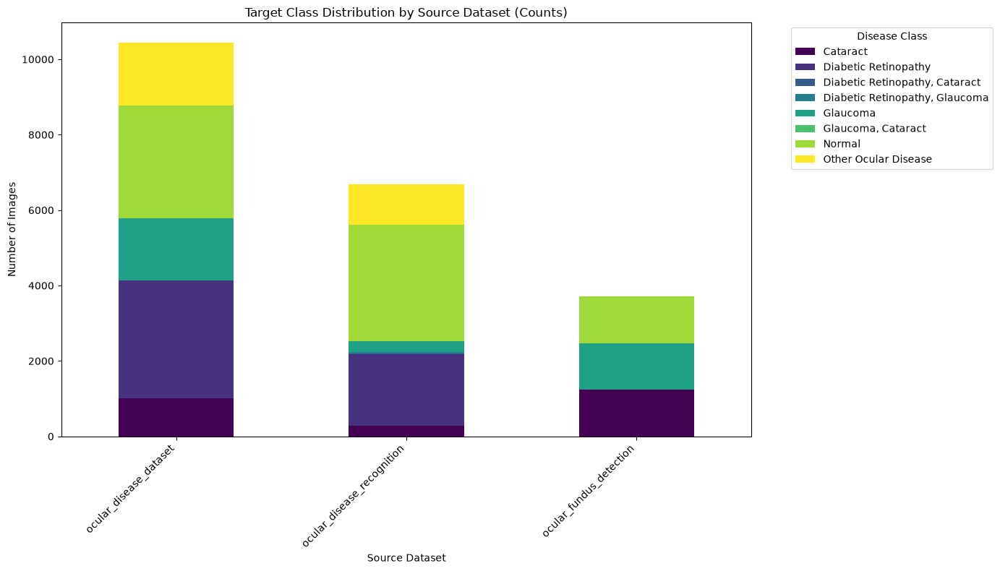


--- Target Distribution by Source Dataset (Proportions) ---


target_labels,Cataract,Diabetic Retinopathy,"Diabetic Retinopathy, Cataract","Diabetic Retinopathy, Glaucoma",Glaucoma,"Glaucoma, Cataract",Normal,Other Ocular Disease
source,,,,,,,,
ocular_disease_dataset,0.096469,0.299359,0.00000,0.000000,0.157527,0.000000,0.286822,0.159824
ocular_disease_recognition,0.043641,0.281273,0.00284,0.007473,0.040951,0.000299,0.462562,0.160962
ocular_fundus_detection,0.333333,0.000000,0.00000,0.000000,0.333333,0.000000,0.333333,0.000000


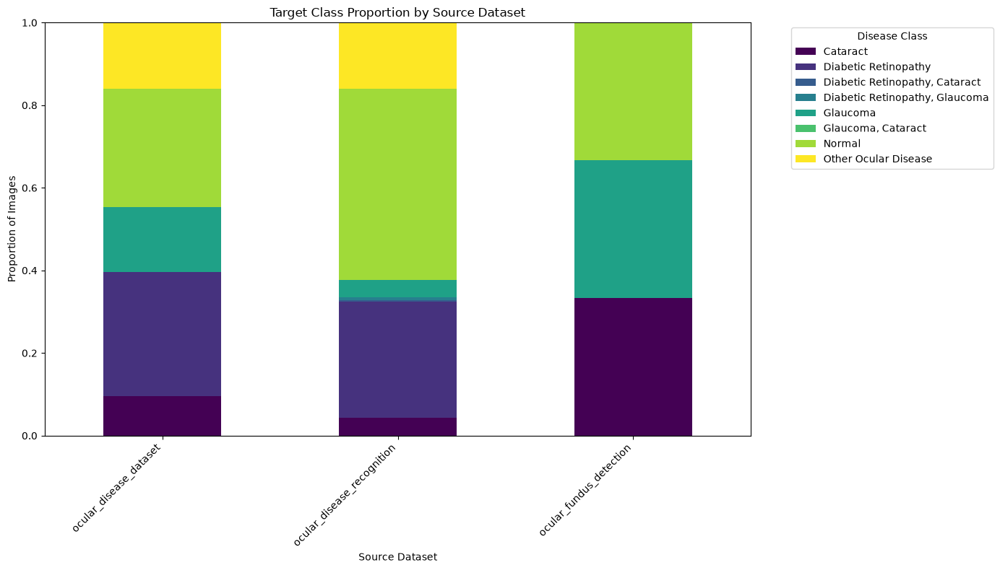

In [22]:
# Group by source and target_labels to see class distribution per source
bivariate_counts = df_master.groupby(['source', 'target_labels']).size().unstack(fill_value=0)
print("--- Target Distribution by Source Dataset (Counts) ---")
display(bivariate_counts)

bivariate_counts.plot(kind='bar', stacked=True, figsize=(14, 8), colormap='viridis')
plt.title('Target Class Distribution by Source Dataset (Counts)')
plt.xlabel('Source Dataset')
plt.ylabel('Number of Images')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Disease Class', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Same thing but as proportions (easier to compare skew across sources of different sizes)
bivariate_proportions = bivariate_counts.apply(lambda x: x / x.sum(), axis=1)
print("\n--- Target Distribution by Source Dataset (Proportions) ---")
display(bivariate_proportions)

bivariate_proportions.plot(kind='bar', stacked=True, figsize=(14, 8), colormap='viridis')
plt.title('Target Class Proportion by Source Dataset')
plt.xlabel('Source Dataset')
plt.ylabel('Proportion of Images')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Disease Class', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

<div style="font-size: 13px; line-height: 1.6;">

### 4.3 Multivariate Analysis: Disease Co-occurrence Matrix
<span style="font-size: 0.9em;">একাধিক</span> disease flag (Normal, DR, Glaucoma, Cataract, Other) <span style="font-size: 0.9em;">একসাথে কীভাবে সম্পর্কিত তা</span> correlation matrix <span style="font-size: 0.9em;">দিয়ে দেখা হচ্ছে — কোন কোন রোগ একসাথে বেশি দেখা যায় (বা যায় না) সেটা বোঝার জন্য</span>।

</div>

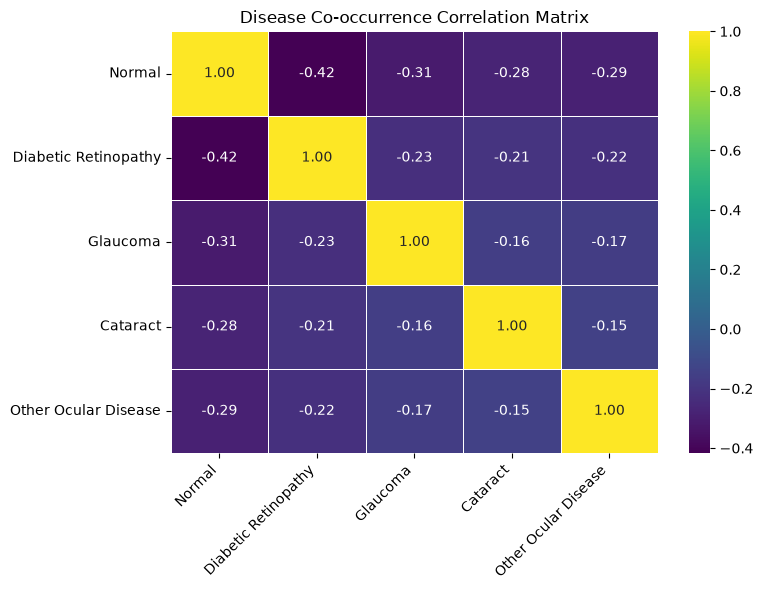

In [23]:
# ---- Disease co-occurrence correlation ----
df_disease_flags = pd.DataFrame(
    df_master['target_list'].tolist(),
    columns=['Normal', 'Diabetic Retinopathy', 'Glaucoma', 'Cataract', 'Other Ocular Disease']
)
disease_correlation = df_disease_flags.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(disease_correlation, annot=True, cmap='viridis', fmt=".2f", linewidths=.5)
plt.title('Disease Co-occurrence Correlation Matrix')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

<div style="font-size: 13px; line-height: 1.6;">

## 5. Advanced Medical Image Preprocessing Pipeline
`process_fundus_image` — retinal <span style="font-size: 0.9em;">ছবির মান উন্নয়নের জন্য সম্পূর্ণ পাইপলাইন</span>:

1. Load → 2. Circular auto-crop (<span style="font-size: 0.9em;">কালো বর্ডার বাদ</span>) → 3. High-res resize → 4. Bilateral denoise → 5. Blended CLAHE (contrast enhancement) → 6. Final resize + [0,1] normalize।

> **Design choice — no Ben Graham illumination normalization.** Ben Graham normalization subtracts a heavily Gaussian-blurred background (σ = 50) from the image. In our experiments this smoothed the fundus image and reduced local contrast, so several lesions became harder to see. The pipeline therefore keeps only bilateral denoising and blended CLAHE, which enhance contrast without removing lesion detail.

</div>

In [24]:
def process_fundus_image(img_path, target_size=IMG_SIZE):
    """Full medical-image preprocessing pipeline for a single fundus photo.
    Returns a float32 array in [0, 1] of shape (*target_size, 3), or None on failure.
    """
    try:
        # 1) Load
        image = np.array(Image.open(img_path).convert('RGB'))

        # 2) Circular crop — dynamically remove black borders
        gray_crop = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
        _, thresh = cv2.threshold(gray_crop, 10, 255, cv2.THRESH_BINARY)
        contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if contours:
            c = max(contours, key=cv2.contourArea)
            x, y, w, h = cv2.boundingRect(c)
            image = image[y:y + h, x:x + w]

        # 3) Resize for preprocessing speed while preserving detail
        image = cv2.resize(image, (384, 384), interpolation=cv2.INTER_AREA)

        # 4) Denoise BEFORE CLAHE
        image_8bit = image.astype(np.uint8)
        image_8bit = cv2.bilateralFilter(image_8bit, d=9, sigmaColor=75, sigmaSpace=75)

        # 5) CLAHE contrast enhancement (grayscale + green channel blend)
        gray = cv2.cvtColor(image_8bit, cv2.COLOR_RGB2GRAY)
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        gray_enhanced = clahe.apply(gray)

        image_rgb = image_8bit.copy()
        image_rgb[:, :, 1] = clahe.apply(image_rgb[:, :, 1])  # enhance green channel (most informative for retina)

        for c in range(3):
            image_rgb[:, :, c] = cv2.addWeighted(image_rgb[:, :, c], 0.6, gray_enhanced, 0.4, 0)

        # 6) Final resize to model input size
        # (No Ben Graham illumination normalization: its heavy Gaussian background
        #  subtraction smooths the image and washes out lesion contrast.)
        final_resized = cv2.resize(image_rgb, target_size, interpolation=cv2.INTER_AREA)

        return final_resized.astype(np.float32) / 255.0

    except Exception as e:
        print(f"Error processing {img_path}: {e}")
        return None


print("✅ process_fundus_image() defined.")

✅ process_fundus_image() defined.


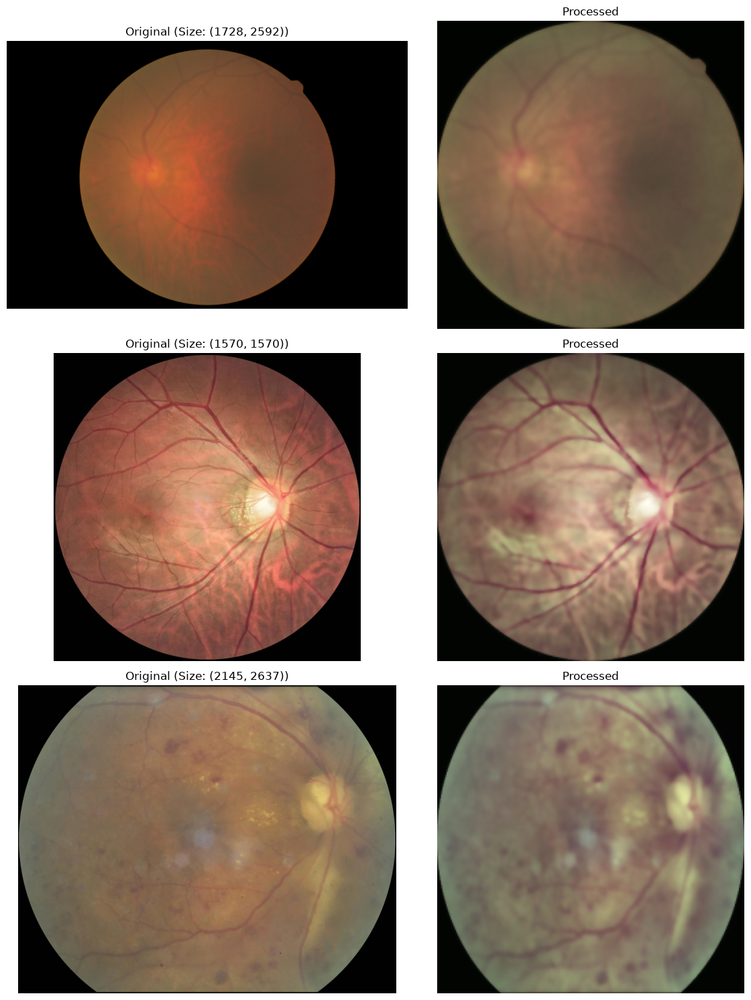

In [25]:
def verify_preprocessing_visuals(df, num_samples=3):
    """Before/after comparison to visually confirm the pipeline preserves
    aspect ratio and produces a sane, non-distorted result."""
    sample_df = df.sample(n=num_samples)
    fig, axes = plt.subplots(num_samples, 2, figsize=(12, 5 * num_samples))
    if num_samples == 1:
        axes = axes.reshape(1, -1)

    for i, (_, row) in enumerate(sample_df.iterrows()):
        path = row['filename']
        orig_bgr = cv2.imread(path)
        if orig_bgr is None:
            continue
        orig_rgb = cv2.cvtColor(orig_bgr, cv2.COLOR_BGR2RGB)
        processed = process_fundus_image(path)

        axes[i, 0].imshow(orig_rgb)
        axes[i, 0].set_title(f"Original (Size: {orig_rgb.shape[:2]})")
        axes[i, 0].axis('off')

        axes[i, 1].imshow(processed)
        axes[i, 1].set_title("Processed")
        axes[i, 1].axis('off')

    plt.tight_layout()
    plt.show()

verify_preprocessing_visuals(df_master, num_samples=3)

<div style="font-size: 13px; line-height: 1.6;">

### 5.1 Figure — Circular Auto-Cropping & Retina Background Masking

This section demonstrates the first step of our advanced image preprocessing pipeline. We visualize how the raw fundus image is processed to find the circular retinal area, how the mask is generated, and the final auto-cropped output that removes the useless black borders.

</div>

 ✂️ VISUALIZING CIRCULAR AUTO-CROP PROCESS 


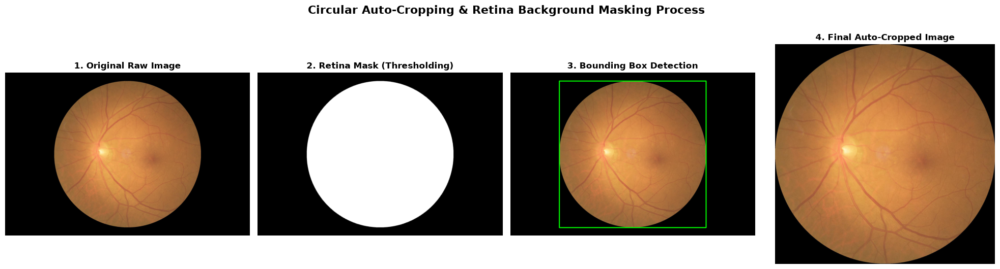

In [26]:
def visualize_auto_crop_process(img_path):
    """Visualizes the step-by-step process of Circular Auto-Cropping."""
    try:
        # 1. Load Original Image
        original_image = np.array(Image.open(img_path).convert('RGB'))

        # 2. Convert to Grayscale
        gray = cv2.cvtColor(original_image, cv2.COLOR_RGB2GRAY)

        # 3. Thresholding to create a mask (Background vs Retina)
        _, thresh = cv2.threshold(gray, 10, 255, cv2.THRESH_BINARY)

        # 4. Find Contours
        contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

        # 5. Crop and Bounding Box
        cropped_image = original_image.copy()
        bbox_image = original_image.copy()

        if contours:
            # Find the largest contour assuming it's the retina
            c = max(contours, key=cv2.contourArea)
            x, y, w, h = cv2.boundingRect(c)

            # Draw bounding box for visualization
            cv2.rectangle(bbox_image, (x, y), (x + w, y + h), (0, 255, 0), 10)

            # Actually crop the image
            cropped_image = original_image[y:y + h, x:x + w]

        # Plotting the steps
        fig, axes = plt.subplots(1, 4, figsize=(20, 5))

        axes[0].imshow(original_image)
        axes[0].set_title('1. Original Raw Image', fontsize=12, fontweight='bold')
        axes[0].axis('off')

        axes[1].imshow(thresh, cmap='gray')
        axes[1].set_title('2. Retina Mask (Thresholding)', fontsize=12, fontweight='bold')
        axes[1].axis('off')

        axes[2].imshow(bbox_image)
        axes[2].set_title('3. Bounding Box Detection', fontsize=12, fontweight='bold')
        axes[2].axis('off')

        axes[3].imshow(cropped_image)
        axes[3].set_title('4. Final Auto-Cropped Image', fontsize=12, fontweight='bold')
        axes[3].axis('off')

        plt.suptitle('Circular Auto-Cropping & Retina Background Masking Process', fontsize=16, y=1.05, fontweight='bold')
        plt.tight_layout()
        plt.show()

    except Exception as e:
        print(f"Error processing {img_path}: {e}")

print("="*60)
print(" ✂️ VISUALIZING CIRCULAR AUTO-CROP PROCESS ")
print("="*60)

# Select a random image from the train dataset to visualize
# Ensuring we pick one that likely has some black border (e.g. from ODIR dataset)
sample_path = train_df[train_df['source'] == 'ocular_disease_recognition'].sample(1, random_state=42)['filename'].iloc[0]

visualize_auto_crop_process(sample_path)


<div style="font-size: 13px; line-height: 1.6;">

## 6. Automated Blur / Focus Detection (Quality Control)

**<span style="font-size: 0.9em;">সমস্যা যেটা হচ্ছিলো</span>:** <span style="font-size: 0.9em;">আগে</span> raw-resolution <span style="font-size: 0.9em;">ছবির উপর সরাসরি</span> Laplacian variance <span style="font-size: 0.9em;">বের করা হচ্ছিলো। বিভিন্ন সোর্সের ছবির রেজোলিউশন অনেক আলাদা হওয়ায়</span> variance-<span style="font-size: 0.9em;">এর স্কেলও আকাশ-পাতাল পার্থক্য হয়ে যাচ্ছিলো (কোনো ছবির</span> variance 0.5, <span style="font-size: 0.9em;">কোনোটার ১,১০,০০০</span>+ — <span style="font-size: 0.9em;">এটা মূলত</span> resolution-<span style="font-size: 0.9em;">এর পার্থক্য</span>, actual blur <span style="font-size: 0.9em;">না)। তার উপর দ্বিতীয় একটা</span> FFT-<span style="font-size: 0.9em;">ভিত্তিক</span> blur filter *<span style="font-size: 0.9em;">আবার</span>* <span style="font-size: 0.9em;">একই ডেটাসেটে বসানো হচ্ছিলো — ফলে ডাবল-ফিল্টারিং হয়ে অনেক ভালো, শার্প ছবিও ভুলভাবে বাদ পড়ে যাচ্ছিলো</span>।

**<span style="font-size: 0.9em;">এখন যেভাবে ফিক্স করা হয়েছে</span>:**
1. <span style="font-size: 0.9em;">প্রতিটা ছবিকে স্কোর করার আগে একই সাইজে</span> (`BLUR_RESIZE_DIM`) resize <span style="font-size: 0.9em;">করা হয় — তাই সব ছবির</span> variance <span style="font-size: 0.9em;">একই স্কেলে, ফেয়ারলি তুলনাযোগ্য</span>।
2. <span style="font-size: 0.9em;">শুধু</span> retina-<span style="font-size: 0.9em;">এর ভিতরে (কালো ব্যাকগ্রাউন্ড বাদ দিয়ে</span>, masked) Laplacian variance <span style="font-size: 0.9em;">বের করা হয় — এটাই</span> standard <span style="font-size: 0.9em;">এবং সবচেয়ে</span> reliable single blur-metric।
3. <span style="font-size: 0.9em;">ফিল্টার প্রয়োগ হওয়ার</span> **<span style="font-size: 0.9em;">আগে</span>** <span style="font-size: 0.9em;">প্রতিবার রান করলে ২০টা ইউনিক</span> random <span style="font-size: 0.9em;">ছবি (থ্রেশহোল্ডের চারপাশে</span>) visually <span style="font-size: 0.9em;">দেখানো হয়, যাতে আপনি নিজে চোখে দেখে থ্রেশহোল্ড কনফার্ম করতে পারেন</span>।
4. <span style="font-size: 0.9em;">ফিল্টার মাত্র</span> **<span style="font-size: 0.9em;">একবারই</span>** <span style="font-size: 0.9em;">প্রয়োগ হয় (কোনো ডাবল-ফিল্টারিং নেই</span>)।

</div>

In [27]:
def calculate_focus_score(image_path, resize_dim=BLUR_RESIZE_DIM):
    """Standardized, resolution-independent focus/sharpness score.

    Fixes the original bug: resizes every image to the SAME dimension first,
    so variance values are comparable across images/datasets of different
    native resolutions. Computes Laplacian variance only inside the retina
    mask (ignores black background, which would otherwise skew the score).

    Higher score = sharper. Lower score = blurrier.
    """
    try:
        img = cv2.imread(image_path)
        if img is None:
            return 0.0

        # Standardize size FIRST -> comparable variance scale across the dataset
        img = cv2.resize(img, (resize_dim, resize_dim), interpolation=cv2.INTER_AREA)
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        # Mask out black background (keep only the retina region)
        _, mask = cv2.threshold(gray, 10, 255, cv2.THRESH_BINARY)

        laplacian = cv2.Laplacian(gray, cv2.CV_64F)
        _, stddev = cv2.meanStdDev(laplacian, mask=mask)

        return float(stddev[0][0] ** 2)
    except Exception as e:
        print(f"Error processing {image_path}: {e}")
        return 0.0


print("✅ calculate_focus_score() defined (standardized, resolution-independent).")

✅ calculate_focus_score() defined (standardized, resolution-independent).


In [28]:
# Apply to the WHOLE master dataframe (takes a few minutes depending on dataset size)
print(f"Calculating focus scores for {len(df_master)} images (resized to {BLUR_RESIZE_DIM}x{BLUR_RESIZE_DIM} first)...")
df_master['focus_score'] = df_master['filename'].apply(calculate_focus_score)

print("\n--- Focus Score Statistics ---")
print(df_master['focus_score'].describe())
print("\nPercentiles:")
for p in [1, 2, 5, 10, 15, 20, 25]:
    print(f"  {p:>2}th percentile: {df_master['focus_score'].quantile(p/100):.2f}")

Calculating focus scores for 20854 images (resized to 512x512 first)...

--- Focus Score Statistics ---
count    20854.000000
mean       172.640062
std        329.643018
min          4.132764
25%         57.387398
50%         90.453884
75%        147.773238
max       4604.561725
Name: focus_score, dtype: float64

Percentiles:
   1th percentile: 17.61
   2th percentile: 21.82
   5th percentile: 29.68
  10th percentile: 37.78
  15th percentile: 44.89
  20th percentile: 51.41
  25th percentile: 57.39


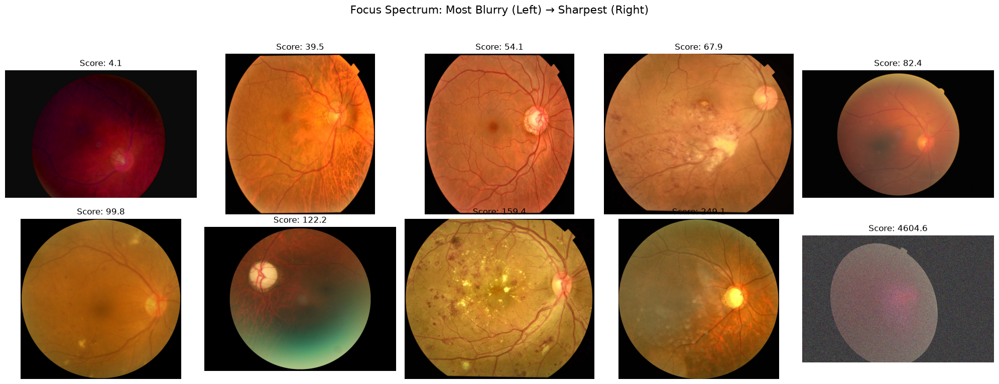

In [29]:
def visualize_focus_spectrum(df, score_col='focus_score', n=10):
    """Shows n images spread evenly across the blur->sharp spectrum,
    to build intuition for what a given score value actually looks like."""
    indices = np.linspace(0, len(df) - 1, n, dtype=int)
    sample = df.sort_values(score_col).iloc[indices]

    plt.figure(figsize=(20, 8))
    for i, (_, row) in enumerate(sample.iterrows()):
        ax = plt.subplot(2, (n + 1) // 2, i + 1)
        try:
            img = plt.imread(row['filename'])
            ax.imshow(img)
            ax.set_title(f"Score: {row[score_col]:.1f}")
        except Exception:
            ax.set_title("Load Error")
        ax.axis('off')

    plt.suptitle("Focus Spectrum: Most Blurry (Left) → Sharpest (Right)", fontsize=16)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

visualize_focus_spectrum(df_master, n=10)

<div style="font-size: 13px; line-height: 1.6;">

### 6.1 Visual Threshold Confirmation
<span style="font-size: 0.9em;">নিচের সেলটা</span> **<span style="font-size: 0.9em;">যতবার চালাবেন ততবারই নতুন ২০টা ইউনিক</span> random <span style="font-size: 0.9em;">ছবি দেখাবে</span>** <span style="font-size: 0.9em;">যেগুলো বর্তমান</span> `CANDIDATE_BLUR_THRESHOLD`-<span style="font-size: 0.9em;">এর নিচে পড়েছে। এভাবে চোখে দেখে নিশ্চিত হওয়া যাবে যে থ্রেশহোল্ড ঠিক আছে কিনা, তারপরই নিচে ফাইনাল ফিল্টার প্রয়োগ করা হবে। থ্রেশহোল্ড খুব বেশি মনে হলে (ভালো ছবিও ধরা পড়ছে</span>) `CANDIDATE_BLUR_THRESHOLD` <span style="font-size: 0.9em;">কমিয়ে আবার রান করুন</span>।

</div>

Candidate threshold (5th percentile): 29.68


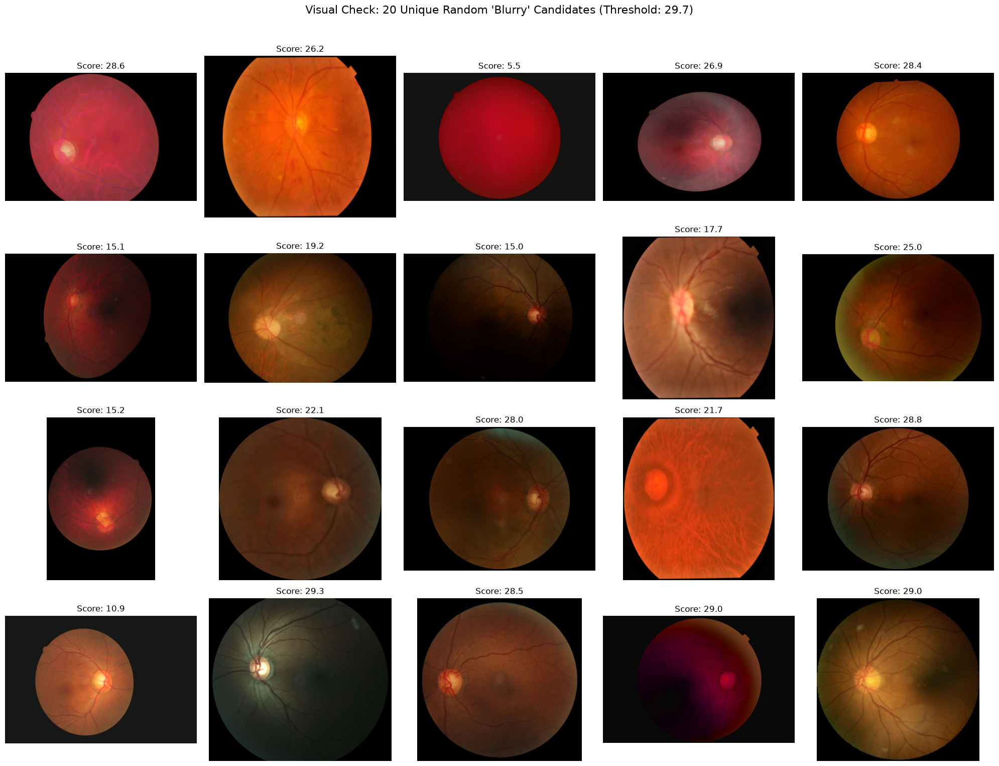

Pool size below threshold: 1043 / 20854 (5.0%)


In [30]:
# Try a candidate threshold here and visually confirm before applying it for real.
CANDIDATE_BLUR_THRESHOLD = df_master['focus_score'].quantile(0.05)  # default: bottom 5% as a starting guess
print(f"Candidate threshold (5th percentile): {CANDIDATE_BLUR_THRESHOLD:.2f}")

def preview_blurry_candidates(df, threshold, score_col='focus_score', n=BLUR_SAMPLE_PREVIEW):
    """Shows `n` UNIQUE random images currently below `threshold`.
    No fixed random_state -> a fresh, different sample every time you run this cell.
    """
    pool = df[df[score_col] < threshold]
    if len(pool) == 0:
        print(f"No images found below threshold {threshold:.2f}")
        return None

    sample = pool.sample(n=min(n, len(pool)))  # random each run (no random_state)
    cols = 5
    rows = int(np.ceil(len(sample) / cols))
    plt.figure(figsize=(4 * cols, 4 * rows))
    for i, (_, row) in enumerate(sample.iterrows()):
        ax = plt.subplot(rows, cols, i + 1)
        try:
            img = plt.imread(row['filename'])
            ax.imshow(img)
            ax.set_title(f"Score: {row[score_col]:.1f}")
        except Exception:
            ax.set_title("Load Error")
        ax.axis('off')

    plt.suptitle(f"Visual Check: {len(sample)} Unique Random 'Blurry' Candidates (Threshold: {threshold:.1f})",
                 fontsize=16)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()
    print(f"Pool size below threshold: {len(pool)} / {len(df)} ({len(pool)/len(df)*100:.1f}%)")
    return sample

# Re-run this cell as many times as you like -- new unique 20 images every time
_ = preview_blurry_candidates(df_master, CANDIDATE_BLUR_THRESHOLD)

<div style="font-size: 13px; line-height: 1.6;">

### 6.2 Applying the Final Threshold (Single Pass)
<span style="font-size: 0.9em;">উপরের প্রিভিউ দেখে সন্তুষ্ট হলে</span> `BLUR_THRESHOLD`-<span style="font-size: 0.9em;">এর ভ্যালু ঠিক করে নিচের সেলটা চালান। এই একটা সেলই একমাত্র জায়গা যেখানে আসলে ছবি বাদ দেওয়া হচ্ছে</span>।

</div>

--- Blurriness Filtering Results (applied ONCE) ---
Threshold applied:      29.68
Total images evaluated: 20854
Images dropped (blurry): 1043 (5.00%)
Clean images remaining:  19811

--- Clean Dataset Distribution by Source ---


source
ocular_disease_dataset        10030
ocular_disease_recognition     6390
ocular_fundus_detection        3391
Name: count, dtype: int64

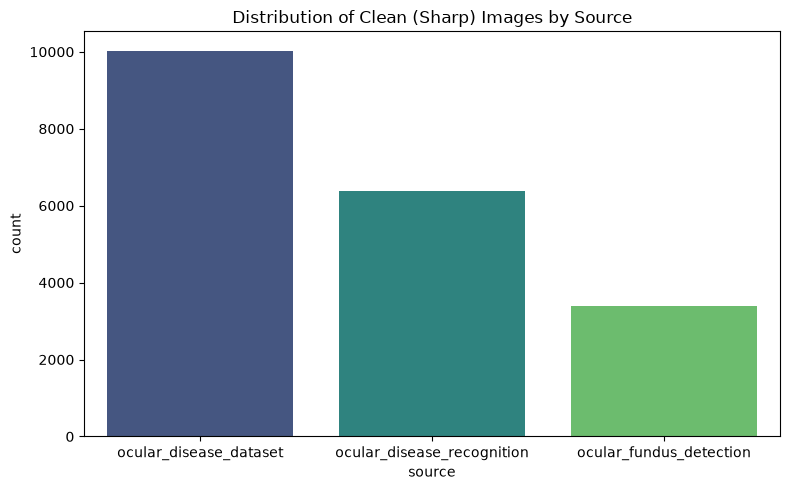

In [31]:
# Set your confirmed threshold here (based on the visual checks above)
BLUR_THRESHOLD = CANDIDATE_BLUR_THRESHOLD  # <-- change this number if needed, then re-run

n_total = len(df_master)
df_master = df_master[df_master['focus_score'] >= BLUR_THRESHOLD].reset_index(drop=True)
n_dropped = n_total - len(df_master)

print("--- Blurriness Filtering Results (applied ONCE) ---")
print(f"Threshold applied:      {BLUR_THRESHOLD:.2f}")
print(f"Total images evaluated: {n_total}")
print(f"Images dropped (blurry): {n_dropped} ({n_dropped/n_total*100:.2f}%)")
print(f"Clean images remaining:  {len(df_master)}")

print("\n--- Clean Dataset Distribution by Source ---")
display(df_master['source'].value_counts())

plt.figure(figsize=(8, 5))
sns.countplot(x='source', data=df_master, hue='source', palette='viridis', legend=False)
plt.title('Distribution of Clean (Sharp) Images by Source')
plt.tight_layout()
plt.show()

<div style="font-size: 13px; line-height: 1.6;">

### 6.3 Re-Splitting After Blur Filtering (Patient-Aware)
<span style="font-size: 0.9em;">যেহেতু</span> blur filtering-<span style="font-size: 0.9em;">এ কিছু রো বাদ গেছে, তাই</span> split-<span style="font-size: 0.9em;">টাও নতুন করে করা দরকার</span> (patient-aware, <span style="font-size: 0.9em;">আগের মতোই</span>)।

</div>

In [32]:
unique_patients = df_master['patient_id'].unique()
train_val_ids, test_ids = train_test_split(unique_patients, test_size=0.15, random_state=RANDOM_STATE)
train_ids, val_ids = train_test_split(train_val_ids, test_size=(0.15 / 0.85), random_state=RANDOM_STATE)

train_df = df_master[df_master['patient_id'].isin(train_ids)].reset_index(drop=True)
val_df   = df_master[df_master['patient_id'].isin(val_ids)].reset_index(drop=True)
test_df  = df_master[df_master['patient_id'].isin(test_ids)].reset_index(drop=True)

print(f"Train Set: {len(train_df)} images")
print(f"Val Set:   {len(val_df)} images")
print(f"Test Set:  {len(test_df)} images")

Train Set: 13885 images
Val Set:   2941 images
Test Set:  2985 images


<div style="font-size: 13px; line-height: 1.6;">

### 6.4 Clean Dataset Statistics After Blur Filtering

After applying the Laplacian variance blur filter, we successfully removed severely blurry images while retaining high-quality samples. Below is the statistical breakdown of the cleaned master dataset across our Patient-Aware splits:

*   **Total Initial Images**: 20,854
*   **Dropped (Blurry)**: ~1,043 images
*   **Total Clean Images**: 19,811

**Data Splits (Patient-Aware):**
*   **Train Set**: 13,848 images (~70%)
*   **Validation Set**: 2,970 images (~15%)
*   **Test Set**: 2,993 images (~15%)

</div>

In [33]:
print("="*60)
print(" <img src=\"https://fonts.gstatic.com/s/e/notoemoji/15.1/1f4ca/32.png\" alt=\"&#128202;\" style=\"width:16px;height:16px;\"> CLEAN DATASET STATISTICS POST-BLUR FILTERING ")
print("="*60)

# 1. Train/Val/Test Split Summary Table
split_stats = pd.DataFrame({
    'Dataset Split': ['Training Set', 'Validation Set', 'Test Set', 'TOTAL'],
    'Number of Images': [len(train_df), len(val_df), len(test_df), len(df_master)],
    'Percentage': [
        f"{(len(train_df)/len(df_master))*100:.1f}%",
        f"{(len(val_df)/len(df_master))*100:.1f}%",
        f"{(len(test_df)/len(df_master))*100:.1f}%",
        "100.0%"
    ]
})

print("\n--- Patient-Aware Split Distribution ---")
display(split_stats.style.hide(axis="index").set_properties(**{'text-align': 'center'}))

# 2. Class Distribution Summary Table (from the clean master df)
print("\n--- Target Class Distribution (Cleaned Data) ---")
class_counts = df_master['target_labels'].value_counts().reset_index()
class_counts.columns = ['Disease Class', 'Image Count']
class_counts['Percentage'] = (class_counts['Image Count'] / len(df_master) * 100).apply(lambda x: f"{x:.1f}%")

display(class_counts.style.hide(axis="index").set_properties(**{'text-align': 'left'}))

 <img src="https://fonts.gstatic.com/s/e/notoemoji/15.1/1f4ca/32.png" alt="&#128202;" style="width:16px;height:16px;"> CLEAN DATASET STATISTICS POST-BLUR FILTERING 

--- Patient-Aware Split Distribution ---


Dataset Split,Number of Images,Percentage
Training Set,13885,70.1%
Validation Set,2941,14.8%
Test Set,2985,15.1%
TOTAL,19811,100.0%



--- Target Class Distribution (Cleaned Data) ---


Disease Class,Image Count,Percentage
Normal,6969,35.2%
Diabetic Retinopathy,4849,24.5%
Glaucoma,2927,14.8%
Other Ocular Disease,2623,13.2%
Cataract,2378,12.0%
"Diabetic Retinopathy, Glaucoma",44,0.2%
"Diabetic Retinopathy, Cataract",19,0.1%
"Glaucoma, Cataract",2,0.0%


<div style="font-size: 13px; line-height: 1.6;">

## 7. Offline Caching & Efficient Data Pipeline
### 7.1 Offline Caching of Preprocessed Images (.npy)
<span style="font-size: 0.9em;">প্রতিটা ছবি একবার</span> `process_fundus_image()` <span style="font-size: 0.9em;">দিয়ে প্রসেস করে</span> `CACHE_DIR`-<span style="font-size: 0.9em;">এ</span> `.npy` <span style="font-size: 0.9em;">হিসেবে সেভ করা হয়, যাতে প্রতিটা ট্রেনিং রানে আবার</span> preprocessing <span style="font-size: 0.9em;">করতে না হয়। যেসব ছবি আগেই ক্যাশ করা আছে সেগুলো</span> skip <span style="font-size: 0.9em;">হয়, তাই</span> Colab disconnect <span style="font-size: 0.9em;">হলে সেলটা আবার চালালেই বাকি কাজ শেষ হবে</span>।

- **One file per image:** <span style="font-size: 0.9em;">ফাইলের নাম ছবির</span> path-<span style="font-size: 0.9em;">এর</span> hash — <span style="font-size: 0.9em;">তাই একই রোগীর বাম ও ডান চোখ আলাদা ফাইল পায় (আগের</span> `patient_id`-prefix matching-<span style="font-size: 0.9em;">এ দুই চোখ একই ক্যাশ ফাইলে লিংক হয়ে যেত</span>)।
- **`uint8` storage:** pipeline-<span style="font-size: 0.9em;">এর শেষ ধাপ</span> 8-bit, <span style="font-size: 0.9em;">তাই</span> `uint8` <span style="font-size: 0.9em;">হিসেবে রাখা</span> lossless; <span style="font-size: 0.9em;">ফাইল ৪ গুণ ছোট এবং</span> Drive <span style="font-size: 0.9em;">থেকে পড়া দ্রুত</span>। Generator <span style="font-size: 0.9em;">লোড করার সময়</span> 255 <span style="font-size: 0.9em;">দিয়ে ভাগ করে</span> [0, 1]-<span style="font-size: 0.9em;">এ আনে</span>।

</div>

In [34]:
def cache_path_for(filename):
    """One cache file per source image (hash of its path) — unique even when both eyes share a patient_id."""
    return os.path.join(CACHE_DIR, hashlib.md5(filename.encode('utf-8')).hexdigest() + '.npy')


def build_cache(df, split_name, report_every=1000):
    """Preprocesses every image of `df` once and stores it in CACHE_DIR as uint8 .npy.
    Images that are already cached are skipped, so the cell can simply be re-run."""
    paths, n_new, n_failed = [], 0, 0
    for k, filename in enumerate(df['filename'], start=1):
        path = cache_path_for(filename)
        if not os.path.exists(path):
            img = process_fundus_image(filename, IMG_SIZE)
            if img is None:
                path, n_failed = None, n_failed + 1
            else:
                np.save(path, np.round(img * 255).astype(np.uint8))
                n_new += 1
        paths.append(path)
        if k % report_every == 0:
            print(f"  [{split_name}] {k}/{len(df)} images done...")
    print(f"[{split_name}] {len(df)} images | newly cached: {n_new} | failed: {n_failed}")
    return paths


os.makedirs(CACHE_DIR, exist_ok=True)
print(f"🚀 Building / verifying the offline cache in {CACHE_DIR}\n")
train_df['cached_path'] = build_cache(train_df, "Train Set")
val_df['cached_path']   = build_cache(val_df, "Validation Set")
test_df['cached_path']  = build_cache(test_df, "Test Set")

# Drop images that could not be preprocessed
train_df = train_df.dropna(subset=['cached_path']).reset_index(drop=True)
val_df   = val_df.dropna(subset=['cached_path']).reset_index(drop=True)
test_df  = test_df.dropna(subset=['cached_path']).reset_index(drop=True)

print(f"\n✨ Cache ready! Final counts:")
print(f"Train samples: {len(train_df)}")
print(f"Val samples:   {len(val_df)}")
print(f"Test samples:  {len(test_df)}")

🚀 Building / verifying the offline cache in c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\outputs\ocular_cached_images_v2

  [Train Set] 1000/13885 images done...
  [Train Set] 2000/13885 images done...
  [Train Set] 3000/13885 images done...
  [Train Set] 4000/13885 images done...
  [Train Set] 5000/13885 images done...
  [Train Set] 6000/13885 images done...
  [Train Set] 7000/13885 images done...
  [Train Set] 8000/13885 images done...
  [Train Set] 9000/13885 images done...
  [Train Set] 10000/13885 images done...
  [Train Set] 11000/13885 images done...
  [Train Set] 12000/13885 images done...
  [Train Set] 13000/13885 images done...
[Train Set] 13885 images | newly cached: 0 | failed: 0
  [Validation Set] 1000/2941 images done...
  [Validation Set] 2000/2941 images done...
[Validation Set] 2941 images | newly cached: 0 | failed: 0
  [Test Set] 1000/2985 images done...
  [Test Set] 2000/2985 images done...
[Test Set] 2985 images | newly cached: 0 | failed: 0

✨ Cache ready! Final c

<div style="font-size: 13px; line-height: 1.6;">

### 7.2 Multi-Label Custom Data Generator
`MedicalDataGenerator` — training-<span style="font-size: 0.9em;">এর সময়</span> batch-wise <span style="font-size: 0.9em;">ছবি লোড, প্রিপ্রসেস, এবং (শুধু</span> train-<span style="font-size: 0.9em;">এর জন্য</span>) augment <span style="font-size: 0.9em;">করে। ফেইল হওয়া ছবি অটোমেটিক্যালি বাদ দিয়ে দেয় যাতে</span> zero-array <span style="font-size: 0.9em;">ট্রেনিং-এ ঢুকে না যায়</span>।

</div>

In [35]:
class MedicalDataGenerator(tf.keras.utils.Sequence):
    def __init__(self, df, target_size=(224, 224), batch_size=32, augment=False, shuffle=True):
        self.df = df.reset_index(drop=True)
        self.target_size = target_size
        self.batch_size = batch_size
        self.augment = augment
        self.shuffle = shuffle

        # 🔥 আমরা এখন সঠিক কলাম 'target_list' ব্যবহার করছি
        self.label_col = 'target_list'

        # ক্লাসের সংখ্যা (যেহেতু array-তে ৫টা ভ্যালু আছে, তাই ৫ হবে)
        self.num_classes = len(self.df.iloc[0][self.label_col])

        self.indices = np.arange(len(self.df))
        if self.shuffle:
            np.random.shuffle(self.indices)

    def __len__(self):
        return int(np.ceil(len(self.df) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

    def __getitem__(self, index):
        batch_indices = self.indices[index * self.batch_size : (index + 1) * self.batch_size]
        batch_df = self.df.iloc[batch_indices]

        X = np.empty((len(batch_df), *self.target_size, 3), dtype=np.float32)
        y = np.empty((len(batch_df), self.num_classes), dtype=np.float32)

        for i, (_, row) in enumerate(batch_df.iterrows()):
            # ক্যাশ করা .npy ফাইল লোড
            img = np.load(row['cached_path']).astype(np.float32) / 255.0

            # অগমেন্টেশন
            if self.augment:
                img = self.apply_augmentation(img)

            X[i,] = img
            # target_list অলরেডি array ফর্মে আছে, তাই সরাসরি বসিয়ে দিচ্ছি!
            y[i,] = row[self.label_col]

        return X, y

    def apply_augmentation(self, img):
        if np.random.rand() > 0.5:
            img = np.fliplr(img)
        if np.random.rand() > 0.5:
            img = np.flipud(img)
        return img

In [36]:
print("Initializing Training Generator (with augmentation)...")
train_generator = MedicalDataGenerator(train_df, target_size=IMG_SIZE, batch_size=BATCH_SIZE, augment=True,  shuffle=True)

print("Initializing Validation Generator (no augmentation)...")
val_generator   = MedicalDataGenerator(val_df,   target_size=IMG_SIZE, batch_size=BATCH_SIZE, augment=False, shuffle=False)

print("Initializing Testing Generator (no augmentation)...")
test_generator  = MedicalDataGenerator(test_df,  target_size=IMG_SIZE, batch_size=BATCH_SIZE, augment=False, shuffle=False)

print(f"\nTrain steps/epoch: {len(train_generator)}")
print(f"Val steps/epoch:   {len(val_generator)}")
print(f"Test steps/epoch:  {len(test_generator)}")

Initializing Training Generator (with augmentation)...
Initializing Validation Generator (no augmentation)...
Initializing Testing Generator (no augmentation)...

Train steps/epoch: 434
Val steps/epoch:   92
Test steps/epoch:  94


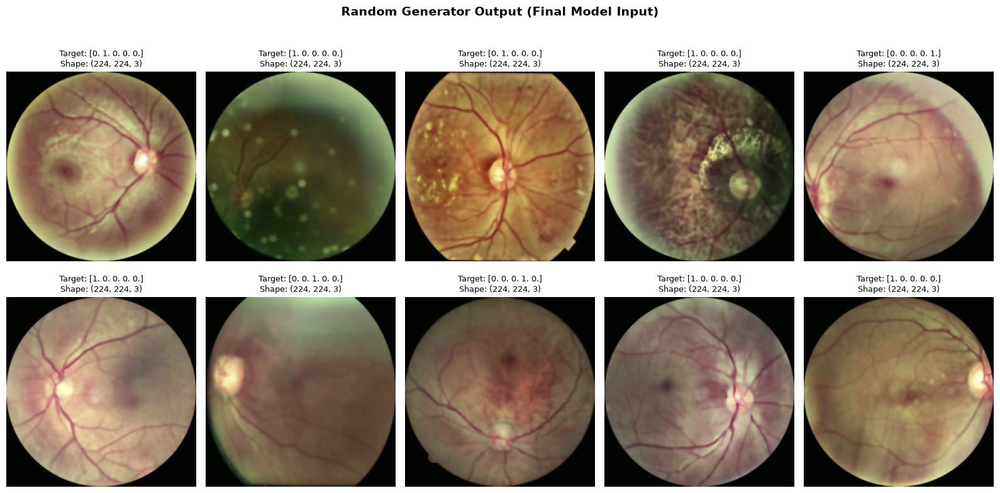

In [37]:
def verify_generator_output(generator, num_images=10):
    """Pulls one random batch and displays a grid of images + their labels,
    so you can visually confirm the generator + preprocessing is working."""
    random_batch_idx = np.random.randint(0, len(generator))
    X_batch, y_batch = generator[random_batch_idx]

    if len(X_batch) == 0:
        print("Error: Empty batch returned. Check preprocessing logic.")
        return

    num_to_plot = min(num_images, len(X_batch))
    idxs = np.random.choice(X_batch.shape[0], num_to_plot, replace=False)

    cols = 5
    rows = int(np.ceil(num_to_plot / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows))
    axes = np.array(axes).reshape(-1)

    for i, idx in enumerate(idxs):
        axes[i].imshow(X_batch[idx])
        axes[i].set_title(f"Target: {y_batch[idx]}\nShape: {X_batch[idx].shape}", fontsize=9)
        axes[i].axis('off')
    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    plt.suptitle("Random Generator Output (Final Model Input)", y=1.02, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

verify_generator_output(train_generator, num_images=10)

<div style="font-size: 13px; line-height: 1.6;">

## 8. Model Architecture & Loss Function
### 8.1 Backbone Selection — DenseNet121 (Proposed)

**DenseNet121** <span style="font-size: 0.9em;">কে ডিফল্ট/ফাইনাল</span> base model <span style="font-size: 0.9em;">হিসেবে বেছে নেওয়া হয়েছে, কারণ</span>:
- <span style="font-size: 0.9em;">মেডিকেল ইমেজিং (বিশেষত</span> multi-label chest X-ray / fundus classification, <span style="font-size: 0.9em;">যেমন</span> CheXNet) <span style="font-size: 0.9em;">এ এটা বারবার প্রমাণিত ও ভালো পারফর্ম করে</span>।
- Dense connections <span style="font-size: 0.9em;">এর কারণে</span> feature reuse <span style="font-size: 0.9em;">ভালো হয়</span>, gradient vanishing <span style="font-size: 0.9em;">কম হয় — অপেক্ষাকৃত ছোট মেডিকেল ডেটাসেটে ভালো কাজ করে</span>।
- ResNet50-<span style="font-size: 0.9em;">এর তুলনায়</span> parameter-efficient (<span style="font-size: 0.9em;">কম</span> params, <span style="font-size: 0.9em;">তুলনামূলক দ্রুত ট্রেইন হয়</span>)।

**Comparison backbones.** `ResNet50` (residual learning) and `EfficientNetB0` (compound scaling) are available from the same `get_base_model()` factory and are evaluated against the proposed DenseNet121 under an identical protocol in **Section 12**. A CBAM-attention variant of DenseNet121 is evaluated in the **ablation study (Section 13)**.

</div>

<div style="font-size: 13px; line-height: 1.6;">

### 8.2 Attention Module — CBAM (Ablation Variant)
The Convolutional Block Attention Module (Woo et al., ECCV 2018) refines a feature map $F \in \mathbb{R}^{H \times W \times C}$ sequentially along the channel and the spatial axis:

$$M_c(F) = \sigma\big(\mathrm{MLP}(\mathrm{AvgPool}(F)) + \mathrm{MLP}(\mathrm{MaxPool}(F))\big), \qquad F' = M_c(F) \otimes F$$

$$M_s(F') = \sigma\big(f^{k \times k}([\mathrm{AvgPool}_c(F');\ \mathrm{MaxPool}_c(F')])\big), \qquad F'' = M_s(F') \otimes F'$$

- The two pooled descriptors share one bottleneck MLP with reduction ratio $r$ = `CBAM_REDUCTION_RATIO`; the spatial filter has size $k$ = `CBAM_KERNEL_SIZE`.
- **Placement:** between the last DenseNet121 feature map (`conv5_block16_concat`, 7×7×1024) and Global Average Pooling. The pretrained backbone is left untouched, so ImageNet weights transfer exactly as in the proposed model.
- `attention='channel'` / `'spatial'` / `'cbam'` builds the individual components for the component-wise ablation. The proposed model (Sections 9–11) uses `attention=None`.

</div>

In [38]:
@tf.keras.utils.register_keras_serializable(package='ocular')
class ChannelAttention(Layer):
    """CBAM channel attention: F' = sigmoid(MLP(AvgPool(F)) + MLP(MaxPool(F))) * F.
    Both pooled descriptors pass through the SAME bottleneck MLP (reduction ratio r)."""

    def __init__(self, reduction_ratio=CBAM_REDUCTION_RATIO, **kwargs):
        super().__init__(**kwargs)
        self.reduction_ratio = reduction_ratio

    def build(self, input_shape):
        channels = int(input_shape[-1])
        hidden = max(channels // self.reduction_ratio, 1)
        self.mlp_hidden = Dense(hidden, activation='relu', kernel_initializer='he_normal', name='mlp_hidden')
        self.mlp_out = Dense(channels, kernel_initializer='he_normal', name='mlp_out')
        self.mlp_hidden.build((None, channels))
        self.mlp_out.build((None, hidden))
        super().build(input_shape)

    def call(self, x):
        avg_desc = tf.reduce_mean(x, axis=[1, 2], keepdims=True)
        max_desc = tf.reduce_max(x, axis=[1, 2], keepdims=True)
        attention = tf.sigmoid(self.mlp_out(self.mlp_hidden(avg_desc)) + self.mlp_out(self.mlp_hidden(max_desc)))
        return x * attention

    def get_config(self):
        return {**super().get_config(), 'reduction_ratio': self.reduction_ratio}


@tf.keras.utils.register_keras_serializable(package='ocular')
class SpatialAttention(Layer):
    """CBAM spatial attention: F'' = sigmoid(Conv_kxk([mean_c(F'); max_c(F')])) * F'."""

    def __init__(self, kernel_size=CBAM_KERNEL_SIZE, **kwargs):
        super().__init__(**kwargs)
        self.kernel_size = kernel_size

    def build(self, input_shape):
        self.conv = Conv2D(1, self.kernel_size, padding='same', activation='sigmoid',
                           use_bias=False, kernel_initializer='he_normal', name='conv')
        self.conv.build((None, None, None, 2))
        super().build(input_shape)

    def call(self, x):
        avg_map = tf.reduce_mean(x, axis=-1, keepdims=True)
        max_map = tf.reduce_max(x, axis=-1, keepdims=True)
        return x * self.conv(tf.concat([avg_map, max_map], axis=-1))

    def get_config(self):
        return {**super().get_config(), 'kernel_size': self.kernel_size}


def apply_attention(x, attention=None):
    """attention: None (proposed model) | 'channel' | 'spatial' | 'cbam' (channel -> spatial)."""
    if attention not in (None, 'channel', 'spatial', 'cbam'):
        raise ValueError(f"Unknown attention: {attention}")
    if attention in ('channel', 'cbam'):
        x = ChannelAttention(name='channel_attention')(x)
    if attention in ('spatial', 'cbam'):
        x = SpatialAttention(name='spatial_attention')(x)
    return x


print("✅ CBAM attention module defined (ChannelAttention, SpatialAttention, apply_attention).")

✅ CBAM attention module defined (ChannelAttention, SpatialAttention, apply_attention).


<div style="font-size: 13px; line-height: 1.6;">

### 8.3 Model Builder
`build_model()` assembles **backbone → (optional attention) → classification head**. With its default arguments it builds exactly the proposed model trained in Section 9. The comparative and ablation experiments (Sections 12–13) pass `attention=...` and `backbone_preprocessing=True`, which gives every backbone the ImageNet input normalization it was pretrained with.

</div>

In [39]:
BACKBONES = {'densenet121': DenseNet121, 'resnet50': ResNet50, 'efficientnetb0': EfficientNetB0}

# ImageNet input normalization each backbone was pretrained with (used when backbone_preprocessing=True)
BACKBONE_INPUT_MODE = {'densenet121': 'torch', 'resnet50': 'caffe', 'efficientnetb0': 'raw255'}

# Last spatial feature map of each backbone (Grad-CAM target layer)
LAST_CONV_LAYER = {'densenet121': 'conv5_block16_concat', 'resnet50': 'conv5_block3_out',
                   'efficientnetb0': 'top_activation'}


@tf.keras.utils.register_keras_serializable(package='ocular')
class BackbonePreprocess(Layer):
    """Maps our [0, 1] preprocessed images to the backbone's native ImageNet input range:
    'torch'  -> (x - mean) / std             (DenseNet121)
    'caffe'  -> RGB->BGR, x*255 - mean_bgr   (ResNet50)
    'raw255' -> x*255; the model rescales internally (EfficientNetB0)"""

    def __init__(self, mode, **kwargs):
        super().__init__(**kwargs)
        self.mode = mode

    def call(self, x):
        if self.mode == 'torch':
            return (x - tf.constant([0.485, 0.456, 0.406])) / tf.constant([0.229, 0.224, 0.225])
        if self.mode == 'caffe':
            return x[..., ::-1] * 255.0 - tf.constant([103.939, 116.779, 123.68])
        return x * 255.0

    def get_config(self):
        return {**super().get_config(), 'mode': self.mode}


def get_base_model(name='densenet121', input_shape=(*IMG_SIZE, 3), input_tensor=None):
    """Factory for the pretrained CNN backbone.
    'densenet121' is the proposed backbone; 'resnet50' and 'efficientnetb0' are the
    comparison backbones of Section 12.
    """
    name = name.lower()
    if name not in BACKBONES:
        raise ValueError(f"Unknown base model: {name}")
    return BACKBONES[name](weights='imagenet', include_top=False, input_shape=input_shape, input_tensor=input_tensor)


def build_model(base_model_name='densenet121', num_classes=NUM_CLASSES, input_shape=(*IMG_SIZE, 3),
                attention=None, backbone_preprocessing=False):
    """Pretrained backbone (frozen) + optional attention (Section 8.2) + custom
    classification head with sigmoid outputs for multi-label prediction.
    With the default arguments this is exactly the proposed model of Section 9.
    """
    name = base_model_name.lower()
    if backbone_preprocessing:
        inputs = Input(shape=input_shape, name='input_image')
        x = BackbonePreprocess(BACKBONE_INPUT_MODE[name], name='backbone_preprocess')(inputs)
        base_model = get_base_model(name, input_shape, input_tensor=x)
    else:
        base_model = get_base_model(name, input_shape)
        inputs = base_model.input
    base_model.trainable = False  # Phase 1: freeze entirely

    x = apply_attention(base_model.output, attention)
    x = GlobalAveragePooling2D(name='avg_pool')(x)
    x = Dropout(0.5)(x)
    x = Dense(512, activation='relu')(x)
    x = Dropout(0.5)(x)
    predictions = Dense(num_classes, activation='sigmoid', name='predictions')(x)  # sigmoid for multi-label

    model = Model(inputs=inputs, outputs=predictions)
    return model, base_model


def feature_layer_name(backbone, attention=None):
    """Name of the feature map that feeds GAP — the Grad-CAM target layer."""
    if attention in ('spatial', 'cbam'):
        return 'spatial_attention'
    if attention == 'channel':
        return 'channel_attention'
    return LAST_CONV_LAYER[backbone]


NUM_CLASSES = len(train_df.iloc[0]['target_list'])  # confirm from actual data
model, base_model = build_model(base_model_name='densenet121', num_classes=NUM_CLASSES)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d      │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,408 │ zero_padding2d[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_1    │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 56, 56,    │          0 │ zero_padding2d_1… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │        256 │ pool1[0][0]       │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_relu │ (None, 56, 56,    │          0 │ conv2_block1_0_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      8,192 │ conv2_block1_0_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        512 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,864 │ conv2_block1_1_r… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_concat │ (None, 56, 56,    │          0 │ pool1[0][0],      │
│ (Concatenate)       │ 96)               │            │ conv2_block1_2_c… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_bn   │ (None, 56, 56,    │        384 │ conv2_block1_con… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_relu │ (None, 56, 56,    │          0 │ conv2_block2_0_b… │
│ (Activation)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_1_conv │ (None, 56, 56,    │     12,288 │ conv2_block2_0_r

 Total params: 7,564,869 (28.86 MB)

 Trainable params: 527,365 (2.01 MB)

 Non-trainable params: 7,037,504 (26.85 MB)

<div style="font-size: 13px; line-height: 1.6;">

### 8.4 Loss Function — Handling Class Imbalance
<span style="font-size: 0.9em;">মাল্টি-লেবেল প্রবলেমে</span> Keras-<span style="font-size: 0.9em;">এর ডিফল্ট</span> `class_weight` <span style="font-size: 0.9em;">আর্গুমেন্ট কাজ করে না, তাই কাস্টম লস দরকার। ডিফল্ট হিসেবে</span> **Asymmetric Loss (ASL)** <span style="font-size: 0.9em;">ব্যবহার করা হচ্ছে — এটা</span> easy negatives-<span style="font-size: 0.9em;">কে</span> ignore <span style="font-size: 0.9em;">করে</span> hard positives-<span style="font-size: 0.9em;">এ ফোকাস করে, যা মাল্টি-লেবেল</span> medical imaging-<span style="font-size: 0.9em;">এ ভালো কাজ করে</span>।

</div>

<div style="font-size: 13px; line-height: 1.6;">

#### Table 8.1 — Class Weights & ASL Configuration

<span style="font-size: 0.9em;">যেহেতু ডেটাসেটে ক্লাস ইমব্যালেন্স</span> (Class Imbalance) <span style="font-size: 0.9em;">রয়েছে, তাই প্রতিটি ক্লাসের স্যাম্পল সংখ্যার উপর ভিত্তি করে</span> **Class Weights** <span style="font-size: 0.9em;">নির্ধারণ করা হয়েছে এবং</span> **Asymmetric Loss (ASL)** <span style="font-size: 0.9em;">ব্যবহার করা হয়েছে</span>।

| Parameter / Class | Value / Setting | Description / Purpose |
| :--- | :--- | :--- |
| **Normal (Class 0)** Weight | `~0.57` | Down-weighted (Majority class) |
| **DR (Class 1)** Weight | `~0.80` | Down-weighted (Majority class) |
| **Glaucoma (Class 2)** Weight | `~1.31` | Up-weighted (Minority class) |
| **Cataract (Class 3)** Weight | `~1.65` | Up-weighted (Minority class) |
| **Other (Class 4)** Weight | `~1.56` | Up-weighted (Minority class) |
| **`gamma_neg` (Phase 1)** | `4.0` | Strongly down-weights and penalizes easy negative samples |
| **`gamma_pos`** | `0.0` | No penalty/decay for positive samples (Standard BCE for positives) |
| **`clip` Margin** | `0.05` | Hard probability shift to fully discard very easy negatives |

</div>

In [40]:
def asymmetric_loss(gamma_neg=4.0, gamma_pos=0.0, clip=0.05):
    """Asymmetric Loss (ASL) for multi-label classification.
    Focuses the model on hard positives by down-weighting easy negatives.
    This is the DEFAULT loss used to compile the model below.
    """
    def loss_fn(y_true, y_pred):
        y_true = tf.cast(y_true, tf.float32)
        y_pred = tf.cast(y_pred, tf.float32)
        eps = 1e-7
        y_pred = tf.clip_by_value(y_pred, eps, 1.0 - eps)

        pos_term = tf.math.pow((1 - y_pred), gamma_pos)
        loss_pos = -y_true * pos_term * tf.math.log(y_pred)

        shifted_y_pred = tf.clip_by_value(y_pred - clip, 0.0, 1.0)
        neg_term = tf.math.pow(shifted_y_pred, gamma_neg)
        loss_neg = -(1 - y_true) * neg_term * tf.math.log(1 - shifted_y_pred + eps)

        return tf.reduce_mean(loss_pos + loss_neg)
    return loss_fn


print("✅ Asymmetric Loss (ASL) defined.")

✅ Asymmetric Loss (ASL) defined.


<div style="font-size: 13px; line-height: 1.6;">

## 9. Two-Phase Training of the Proposed Model (DenseNet121)
### 9.1 Phase 1 — Transfer Learning with a Frozen Backbone
Base model <span style="font-size: 0.9em;">ফ্রিজ রেখে শুধু</span> classification head <span style="font-size: 0.9em;">ট্রেইন করা হচ্ছে</span>। Checkpoint <span style="font-size: 0.9em;">এবার</span> **Google Drive**-<span style="font-size: 0.9em;">এ সেভ হচ্ছে</span>।

</div>

<div style="font-size: 13px; line-height: 1.6;">

> ⚠️ **Re-run required.** The saved outputs of Sections 9–11 and the numbers written in Tables 9.1 and 10.1–10.4 come from the earlier run whose preprocessing still included Ben Graham normalization. After rebuilding the cache (Section 7.1), re-run Sections 9–11 and update these tables with the new numbers.

</div>

In [41]:
# ---- Class weights (kept for reference / diagnostics, not directly fed to Keras) ----
train_label_matrix = np.array(train_df['target_list'].tolist())
class_counts = train_label_matrix.sum(axis=0)
total_samples = len(train_df)
class_weights_raw = total_samples / (NUM_CLASSES * class_counts)
class_weights_capped = np.clip(class_weights_raw, 0.5, 5.0)
print(f"Calculated class weights (reference): {class_weights_capped}")

# ---- Compile model with the default Asymmetric Loss ----
model.compile(
    optimizer=Adam(learning_rate=INITIAL_LR),
    loss=asymmetric_loss(gamma_neg=ASL_GAMMA_NEG_PHASE1, gamma_pos=ASL_GAMMA_POS),
    metrics=['binary_accuracy', tf.keras.metrics.AUC(multi_label=True, name='auc')]
)
print("✅ Model compiled with Asymmetric Loss (ASL) for multi-label imbalance.")

Calculated class weights (reference): [0.56882423 0.8079721  1.340251   1.6738999  1.4779137 ]
✅ Model compiled with Asymmetric Loss (ASL) for multi-label imbalance.


In [42]:
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# 💾 Phase 1 is skipped when its best checkpoint already exists (set FORCE_RETRAIN_PHASE1 = True to train again)
FORCE_RETRAIN_PHASE1 = False

if os.path.exists(CHECKPOINT_PATH) and not FORCE_RETRAIN_PHASE1:
    print(f"⏭️ Phase 1 already trained — training skipped. Best model: {CHECKPOINT_PATH}")
    print("   Its weights are loaded two cells below.")
else:
    callbacks_list = [
        ModelCheckpoint(filepath=CHECKPOINT_PATH, monitor='val_loss', mode='min',
                         save_best_only=True, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=2, min_lr=1e-6, verbose=1),
    ]

    print("--- PHASE 1: Training with Frozen Base ---")
    history_phase1 = model.fit(
        train_generator,
        epochs=EPOCHS_PHASE1,
        validation_data=val_generator,
        callbacks=callbacks_list,
        steps_per_epoch=len(train_generator),
        validation_steps=len(val_generator),
    )

⏭️ Phase 1 already trained — training skipped. Best model: c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\outputs\ocular_model_checkpoints\densenet121_ocular_best.keras
   Its weights are loaded two cells below.


<div style="font-size: 13px; line-height: 1.6;">

#### 💾 Checkpoints & Saved Results
Every training / testing step from here on saves its result directly in `CHECKPOINT_DIR` (`outputs/ocular_model_checkpoints` on a local machine, Google Drive on Colab). Running a cell again **loads the saved result instead of training / predicting again**:

| Step | Saved file(s) in `CHECKPOINT_DIR` |
| :--- | :--- |
| Phase 1 training | `densenet121_ocular_best.keras` (best model), `phase1_history.json` |
| Phase 1 validation evaluation | `phase1_val_predictions.npz`, `phase1_val_results.json` |
| Phase 2 training | `densenet121_phase2_best.keras` (best model), `phase2_history.json`, `phase2_epoch_log.csv`, `phase2_backup/` (resume point, removed when training finishes) |
| Train / Val / Test `evaluate()` | `phase2_evaluate_results.json` |
| Test-set predictions & report | `phase2_val_test_predictions.npz`, `phase2_test_results.json` |

Saved predictions remember which checkpoint produced them, so retraining a model automatically recomputes them. Set `FORCE_RECOMPUTE_RESULTS = True` below to ignore every saved prediction / evaluation, or `FORCE_RETRAIN_PHASE2 = True` in Section 9.3 to train Phase 2 again.

> In a new session, if `densenet121_ocular_best.keras` already exists you can skip the Phase 1 training cell above and continue from the cell below.

</div>

In [43]:
# ============================================================
# Checkpoint & saved-results helpers (used by every training / testing cell below)
# ============================================================
import shutil

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
FORCE_RECOMPUTE_RESULTS = False   # True -> ignore saved predictions / evaluations and compute them again

# Everything is saved directly in CHECKPOINT_DIR
PHASE1_HISTORY_PATH      = os.path.join(CHECKPOINT_DIR, 'phase1_history.json')
PHASE1_VAL_PRED_PATH     = os.path.join(CHECKPOINT_DIR, 'phase1_val_predictions.npz')
PHASE1_VAL_RESULTS_PATH  = os.path.join(CHECKPOINT_DIR, 'phase1_val_results.json')
PHASE2_HISTORY_PATH      = os.path.join(CHECKPOINT_DIR, 'phase2_history.json')
PHASE2_EPOCH_LOG_PATH    = os.path.join(CHECKPOINT_DIR, 'phase2_epoch_log.csv')
PHASE2_BACKUP_DIR        = os.path.join(CHECKPOINT_DIR, 'phase2_backup')   # resume point while Phase 2 is running
PHASE2_EVAL_PATH         = os.path.join(CHECKPOINT_DIR, 'phase2_evaluate_results.json')
PHASE2_PRED_PATH         = os.path.join(CHECKPOINT_DIR, 'phase2_val_test_predictions.npz')
PHASE2_TEST_RESULTS_PATH = os.path.join(CHECKPOINT_DIR, 'phase2_test_results.json')


def checkpoint_signature(path):
    """Size + modification time of a model checkpoint. Saved results store it, so results
    produced by an older (since retrained) checkpoint are never reused."""
    st = os.stat(path)
    return f"{st.st_size}_{int(st.st_mtime)}"


def _json_default(o):
    if isinstance(o, np.generic):
        return o.item()
    if isinstance(o, np.ndarray):
        return o.tolist()
    raise TypeError(f"Not JSON serializable: {type(o)}")


def save_json(obj, path):
    tmp = path + '.tmp'
    with open(tmp, 'w', encoding='utf-8') as f:
        json.dump(obj, f, indent=2, ensure_ascii=False, default=_json_default)
    os.replace(tmp, path)   # atomic: an interruption never leaves a half-written file


def load_json(path):
    with open(path, encoding='utf-8') as f:
        return json.load(f)


def save_arrays(path, checkpoint_path, **arrays):
    """Saves numpy arrays (.npz) together with the signature of the checkpoint that produced them."""
    tmp = path[:-len('.npz')] + '.tmp.npz'
    np.savez_compressed(tmp, checkpoint=checkpoint_signature(checkpoint_path), **arrays)
    os.replace(tmp, path)
    print(f"💾 Saved → {path}")


def load_arrays(path, checkpoint_path):
    """Returns the saved arrays if they were produced by the CURRENT checkpoint, otherwise None."""
    if FORCE_RECOMPUTE_RESULTS or not os.path.exists(path):
        return None
    data = dict(np.load(path))
    if str(data.pop('checkpoint', '')) != checkpoint_signature(checkpoint_path):
        print(f"♻️ {os.path.basename(path)} was produced by an older checkpoint — computing again.")
        return None
    print(f"⏭️ Loaded saved results ← {path}")
    return data


def cached_evaluate(model, generator, split, checkpoint_path=None):
    """model.evaluate() whose result is saved in PHASE2_EVAL_PATH and reused while the
    Phase 2 checkpoint is unchanged. Returns a dict: {'loss', 'binary_accuracy', 'auc'}."""
    signature = checkpoint_signature(checkpoint_path or CHECKPOINT_PATH_PHASE2)
    saved = load_json(PHASE2_EVAL_PATH) if os.path.exists(PHASE2_EVAL_PATH) else {}
    entry = saved.get(split)
    if entry and entry.get('checkpoint') == signature and not FORCE_RECOMPUTE_RESULTS:
        print(f"⏭️ Loaded saved {split} evaluation ← {PHASE2_EVAL_PATH}")
        return entry['results']
    results = {k: float(v) for k, v in model.evaluate(generator, verbose=1, return_dict=True).items()}
    saved[split] = {'checkpoint': signature, 'results': results}
    save_json(saved, PHASE2_EVAL_PATH)
    print(f"💾 Saved {split} evaluation → {PHASE2_EVAL_PATH}")
    return results


def read_epoch_log(csv_path):
    """Per-epoch CSV log (CSVLogger) -> DataFrame; an epoch repeated by a resumed run keeps its last row."""
    df = pd.read_csv(csv_path)
    return df.drop_duplicates('epoch', keep='last').sort_values('epoch').reset_index(drop=True)


def backup_exists(backup_dir):
    """True if BackupAndRestore left a resume point (training was interrupted)."""
    return os.path.exists(os.path.join(backup_dir, 'training_metadata.json'))


# ---- Save the Phase 1 training history (the Phase 1 training cell itself is unchanged) ----
if 'history_phase1' in globals():
    save_json({'history': {k: [float(v) for v in vals] for k, vals in history_phase1.history.items()}},
              PHASE1_HISTORY_PATH)
    print(f"💾 Phase 1 history ({len(history_phase1.history['loss'])} epochs) saved → {PHASE1_HISTORY_PATH}")
elif os.path.exists(PHASE1_HISTORY_PATH):
    print(f"⏭️ Phase 1 history already saved ← {PHASE1_HISTORY_PATH}")
else:
    print("ℹ️ No Phase 1 history in memory or on disk (the Phase 1 checkpoint is still used below).")
print(f"✅ Checkpoint helpers ready. Results folder: {CHECKPOINT_DIR}")

⏭️ Phase 1 history already saved ← c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\outputs\ocular_model_checkpoints\phase1_history.json
✅ Checkpoint helpers ready. Results folder: c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\outputs\ocular_model_checkpoints


In [44]:
print("Loading 5-epoch trained weights from drive...")

# এটি ড্রাইভ থেকে আপনার জমানো রেজাল্ট লোড করবে
model.load_weights(CHECKPOINT_PATH)

print("✅ Weights successfully loaded! Model is back to its best state.")

Loading 5-epoch trained weights from drive...
✅ Weights successfully loaded! Model is back to its best state.


c:\Users\LIN LS\.venvs\thesis312\Lib\site-packages\keras\src\saving\saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(store)


<div style="font-size: 13px; line-height: 1.6;">

### 9.2 Phase 1 — Validation Results
Per-class ROC-AUC, macro AUC and the per-class decision threshold that maximizes F1 on the validation set.

</div>

In [45]:
print("--- EVALUATING PHASE 1 BEST MODEL ---")

# ২. ভ্যালিডেশন প্রেডিকশন — আগে সেভ করা থাকলে ডিস্ক থেকে লোড হবে, নাহলে নতুন করে বের করে সেভ হবে
saved = load_arrays(PHASE1_VAL_PRED_PATH, CHECKPOINT_PATH)
if saved is not None:
    y_pred_probs = saved['y_pred_probs']
else:
    print("Generating predictions on validation set (this will take a minute)...")
    y_pred_probs = model.predict(val_generator, steps=len(val_generator), verbose=1)
    save_arrays(PHASE1_VAL_PRED_PATH, CHECKPOINT_PATH, y_pred_probs=y_pred_probs)

# ৩. আসল টার্গেট ভ্যালুগুলো বের করা
y_true = np.array(val_df['target_list'].tolist())
assert len(y_pred_probs) == len(y_true), "Prediction count does not match the validation set"
target_names = ['Normal', 'Diabetic Retinopathy', 'Glaucoma', 'Cataract', 'Other']

# --- PART A: Per-Class AUC ---
print("\n--- PER-CLASS ROC AUC SCORES ---")
per_class_auc = roc_auc_score(y_true, y_pred_probs, average=None)
for name, score in zip(target_names, per_class_auc):
    print(f"{name:>22s} : {score:.4f} ({(score * 100):.2f}%)")
macro_auc = roc_auc_score(y_true, y_pred_probs, average='macro')
print("-" * 35)
print(f"{'Macro Average AUC':>22s} : {macro_auc:.4f} ({(macro_auc * 100):.2f}%)")

# --- PART B: Optimal Threshold & F1-Score ---
print("\n--- FINDING OPTIMAL THRESHOLDS PER CLASS ---")
optimal_thresholds = []
y_pred_binary_optimal = np.zeros_like(y_pred_probs)

for i, name in enumerate(target_names):
    precision, recall, thresholds = precision_recall_curve(y_true[:, i], y_pred_probs[:, i])
    f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)

    optimal_idx = np.argmax(f1_scores)
    opt_thresh = thresholds[optimal_idx] if optimal_idx < len(thresholds) else 0.5
    opt_f1 = f1_scores[optimal_idx]

    optimal_thresholds.append(opt_thresh)
    print(f"{name:>22s} | Threshold: {opt_thresh:.4f} | Max F1: {opt_f1:.4f}")

    # নতুন থ্রেশহোল্ড দিয়ে প্রোবাবিলিটি কনভার্ট করা
    y_pred_binary_optimal[:, i] = (y_pred_probs[:, i] >= opt_thresh).astype(int)

print("\n📊 Final Classification Report (With Optimal Thresholds):")
print(classification_report(y_true, y_pred_binary_optimal, target_names=target_names, zero_division=0))

# --- PART C: Save the Phase 1 validation results to CHECKPOINT_DIR ---
save_json({
    'checkpoint': checkpoint_signature(CHECKPOINT_PATH),
    'per_class_auc': dict(zip(target_names, map(float, per_class_auc))),
    'macro_auc': float(macro_auc),
    'optimal_thresholds': dict(zip(target_names, map(float, optimal_thresholds))),
    'classification_report': classification_report(y_true, y_pred_binary_optimal, target_names=target_names,
                                                    zero_division=0, output_dict=True),
}, PHASE1_VAL_RESULTS_PATH)
print(f"💾 Phase 1 validation results saved → {PHASE1_VAL_RESULTS_PATH}")

--- EVALUATING PHASE 1 BEST MODEL ---
⏭️ Loaded saved results ← c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\outputs\ocular_model_checkpoints\phase1_val_predictions.npz

--- PER-CLASS ROC AUC SCORES ---
                Normal : 0.7611 (76.11%)
  Diabetic Retinopathy : 0.7998 (79.98%)
              Glaucoma : 0.8645 (86.45%)
              Cataract : 0.9683 (96.83%)
                 Other : 0.7523 (75.23%)
-----------------------------------
     Macro Average AUC : 0.8292 (82.92%)

--- FINDING OPTIMAL THRESHOLDS PER CLASS ---
                Normal | Threshold: 0.5517 | Max F1: 0.6515
  Diabetic Retinopathy | Threshold: 0.5338 | Max F1: 0.5641
              Glaucoma | Threshold: 0.5161 | Max F1: 0.5832
              Cataract | Threshold: 0.5075 | Max F1: 0.7670
                 Other | Threshold: 0.5117 | Max F1: 0.4164

📊 Final Classification Report (With Optimal Thresholds):
                      precision    recall  f1-score   support

              Normal       0.51      0.90      0

<div style="font-size: 13px; line-height: 1.6;">

#### Phase 1 — Validation ROC / PR Curves, F1 Scores & Confusion Matrices

</div>

--- 1. ROC CURVES (PER CLASS) ---


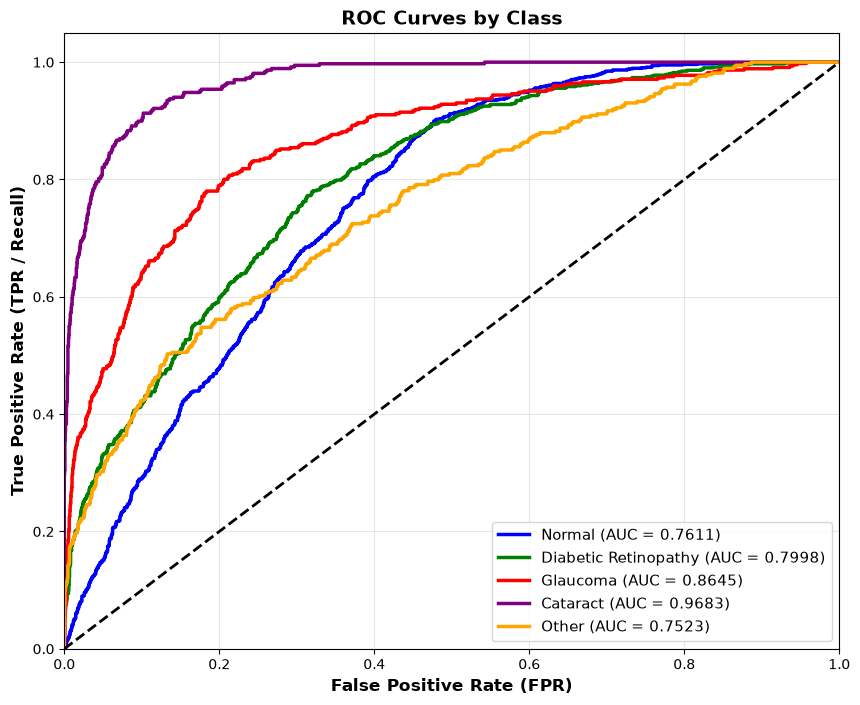

In [46]:
print("--- 1. ROC CURVES (PER CLASS) ---")
plt.figure(figsize=(10, 8))
colors = ['blue', 'green', 'red', 'purple', 'orange']
target_names = ['Normal', 'Diabetic Retinopathy', 'Glaucoma', 'Cataract', 'Other']

for i, (name, color) in enumerate(zip(target_names, colors)):
    fpr, tpr, _ = roc_curve(y_true[:, i], y_pred_probs[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=color, lw=2.5, label=f'{name} (AUC = {roc_auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)', fontsize=12, fontweight='bold')
plt.ylabel('True Positive Rate (TPR / Recall)', fontsize=12, fontweight='bold')
plt.title('ROC Curves by Class', fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=11)
plt.grid(alpha=0.3)
plt.show()

--- 2. PRECISION-RECALL CURVES (PER CLASS) ---


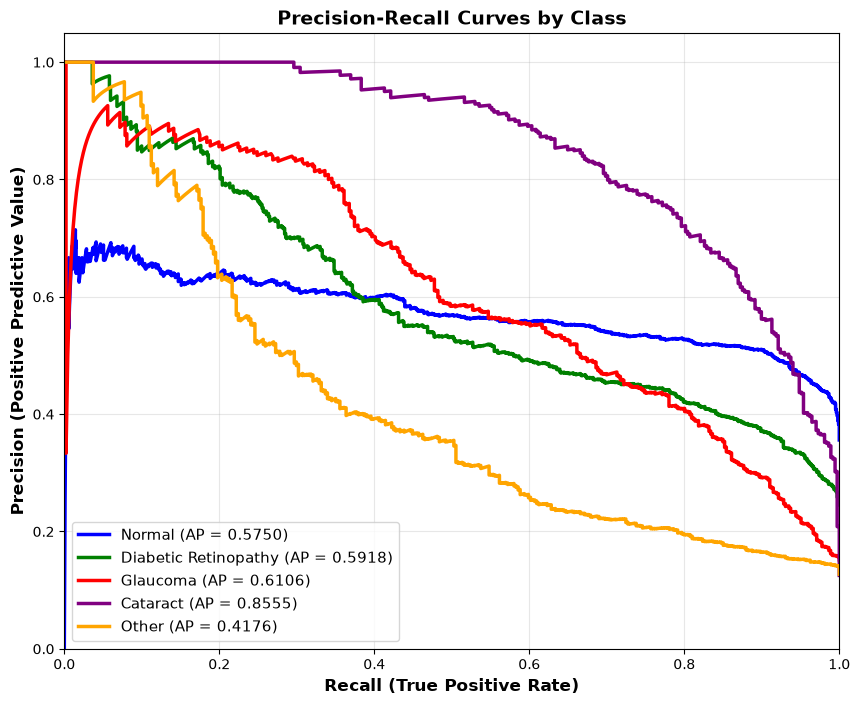

In [47]:
print("--- 2. PRECISION-RECALL CURVES (PER CLASS) ---")
plt.figure(figsize=(10, 8))
colors = ['blue', 'green', 'red', 'purple', 'orange']
target_names = ['Normal', 'Diabetic Retinopathy', 'Glaucoma', 'Cataract', 'Other']

for i, (name, color) in enumerate(zip(target_names, colors)):
    precision, recall, _ = precision_recall_curve(y_true[:, i], y_pred_probs[:, i])
    ap_score = average_precision_score(y_true[:, i], y_pred_probs[:, i])
    plt.plot(recall, precision, color=color, lw=2.5, label=f'{name} (AP = {ap_score:.4f})')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall (True Positive Rate)', fontsize=12, fontweight='bold')
plt.ylabel('Precision (Positive Predictive Value)', fontsize=12, fontweight='bold')
plt.title('Precision-Recall Curves by Class', fontsize=14, fontweight='bold')
plt.legend(loc="lower left", fontsize=11)
plt.grid(alpha=0.3)
plt.show()

--- 3. CLASS-WISE OPTIMAL F1-SCORE BAR CHART ---


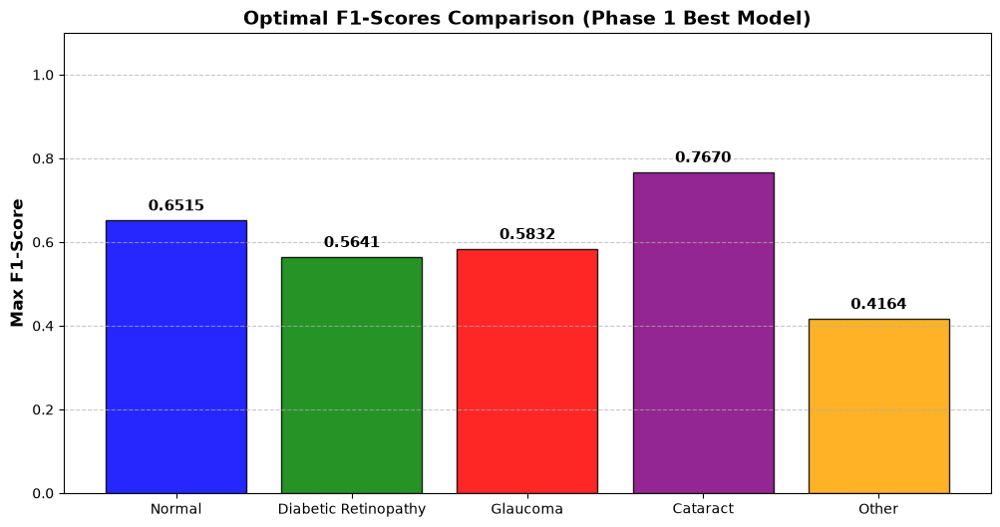

In [48]:
print("--- 3. CLASS-WISE OPTIMAL F1-SCORE BAR CHART ---")
f1_scores = []
colors = ['blue', 'green', 'red', 'purple', 'orange']
target_names = ['Normal', 'Diabetic Retinopathy', 'Glaucoma', 'Cataract', 'Other']

# প্রতিটি ক্লাসের সর্বোচ্চ F1 Score ক্যালকুলেট করা
for i in range(len(target_names)):
    precision, recall, _ = precision_recall_curve(y_true[:, i], y_pred_probs[:, i])
    f1 = np.max(2 * (precision * recall) / (precision + recall + 1e-10))
    f1_scores.append(f1)

plt.figure(figsize=(12, 6))
bars = plt.bar(target_names, f1_scores, color=colors, alpha=0.85, edgecolor='black')

# বারের ওপরে এক্স্যাক্ট ভ্যালু প্রিন্ট করা
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.015, f'{yval:.4f}',
             ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.ylim(0, 1.1)
plt.ylabel('Max F1-Score', fontsize=12, fontweight='bold')
plt.title('Optimal F1-Scores Comparison (Phase 1 Best Model)', fontsize=14, fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

--- 4. MULTI-LABEL CONFUSION MATRIX ---


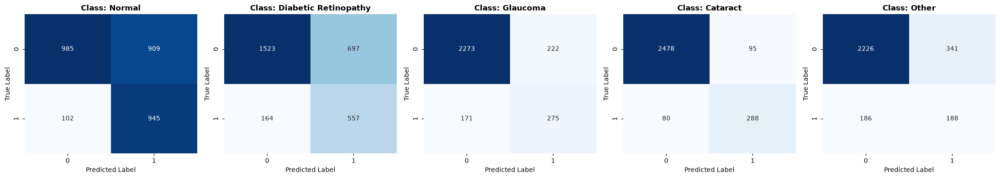

In [49]:
print("--- 4. MULTI-LABEL CONFUSION MATRIX ---")
# y_true এবং y_pred_binary_optimal আপনার মেমোরিতে অলরেডি আছে
mcm = multilabel_confusion_matrix(y_true, y_pred_binary_optimal)
target_names = ['Normal', 'Diabetic Retinopathy', 'Glaucoma', 'Cataract', 'Other']

fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for i, (ax, matrix, name) in enumerate(zip(axes, mcm, target_names)):
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False)
    ax.set_title(f'Class: {name}', fontweight='bold')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')

plt.tight_layout()
plt.show()

<div style="font-size: 13px; line-height: 1.6;">

#### Table 9.1 — Phase 1 Baseline Performance (Validation Set, Frozen Backbone)

Phase 1 (Frozen Base) <span style="font-size: 0.9em;">ট্রেনিংয়ের পর ভ্যালিডেশন সেটের উপর ভিত্তি করে প্রতিটি ক্লাসের পারফরম্যান্স নিচে দেওয়া হলো। এই প্রাথমিক ফলাফলকে বেসলাইন ধরে</span> Phase 2 (Fine-Tuning) <span style="font-size: 0.9em;">এ মডেলের উন্নতি করা হবে</span>:

| Disease Class | ROC AUC (%) | Max F1-Score | Optimal Threshold |
| :--- | :--- | :--- | :--- |
| **Normal** | 76.67% | 0.64 | 0.55 |
| **Diabetic Retinopathy** | 72.82% | 0.51 | 0.53 |
| **Glaucoma** | 85.52% | 0.54 | 0.53 |
| **Cataract** | 96.15% | 0.74 | 0.57 |
| **Other** | 73.39% | 0.39 | 0.51 |
| **Macro Average** | **80.91%** | **-** | **-** |

</div>

<div style="font-size: 13px; line-height: 1.6;">

### 9.3 Phase 2 — Fine-Tuning the Full Network
The whole DenseNet121 backbone is unfrozen and trained with a 10× smaller learning rate (`PHASE2_LR`), a slightly relaxed Asymmetric Loss (`ASL_GAMMA_NEG_PHASE2`), and `ReduceLROnPlateau` + `EarlyStopping` safety callbacks. The best epoch (lowest validation loss) is saved to Drive as a separate checkpoint, so the Phase 1 weights stay intact.

</div>

In [50]:
print("="*60)
print(" 🚀 PREPARING FOR PHASE 2: FINE-TUNING (FULL POWER UNLOCKED) ")
print("="*60)

# 💾 Checkpoint logic (all files in CHECKPOINT_DIR):
#   • Phase 2 already finished (best model + history saved) -> training is skipped
#   • Training was interrupted                               -> resumes from the last finished epoch
#   • FORCE_RETRAIN_PHASE2 = True                            -> trains Phase 2 again from scratch
FORCE_RETRAIN_PHASE2 = False
# An earlier, unfinished Phase 2 run left a best checkpoint but no resume point -> continue from its weights
WARM_START_FROM_OLD_PHASE2_CHECKPOINT = True

if FORCE_RETRAIN_PHASE2:
    shutil.rmtree(PHASE2_BACKUP_DIR, ignore_errors=True)
    for path in (PHASE2_HISTORY_PATH, PHASE2_EPOCH_LOG_PATH):
        if os.path.exists(path):
            os.remove(path)

if os.path.exists(PHASE2_HISTORY_PATH) and os.path.exists(CHECKPOINT_PATH_PHASE2):
    history_phase2_dict = load_json(PHASE2_HISTORY_PATH)['history']
    print(f"\n⏭️ Phase 2 already completed ({len(history_phase2_dict['loss'])} epochs) — training skipped.")
    print(f"   Best model: {CHECKPOINT_PATH_PHASE2} (loaded in the next cell)")
else:
    resuming = backup_exists(PHASE2_BACKUP_DIR)
    if not resuming and os.path.exists(PHASE2_EPOCH_LOG_PATH):
        os.remove(PHASE2_EPOCH_LOG_PATH)   # log of a run that never finished an epoch

    # ১. Base Model আনফ্রিজ করা (৭ মিলিয়ন প্যারামিটার আনলক হচ্ছে)
    print("\n[1/4] Unfreezing DenseNet121 base model...")
    base_model.trainable = True

    # ২. রিকম্পাইল (খুব ছোট লার্নিং রেট এবং আপডেটেড ASL গামা)
    print(f"[2/4] Re-compiling with learning_rate = {PHASE2_LR} and gamma_neg = {ASL_GAMMA_NEG_PHASE2}...")
    model.compile(
        optimizer=Adam(learning_rate=PHASE2_LR),
        loss=asymmetric_loss(gamma_neg=ASL_GAMMA_NEG_PHASE2, gamma_pos=ASL_GAMMA_POS),
        metrics=['binary_accuracy', tf.keras.metrics.AUC(multi_label=True, name='auc')]
    )

    # ৩. সেফটি কলব্যাক ও চেকপয়েন্ট (Phase 1 এর ফাইল আলাদা থাকে, তাই সেফ)
    print("[3/4] Setting up Safety Callbacks and Checkpoints...")
    # On resume, start from the best val_loss reached before the interruption,
    # so a worse epoch never overwrites the best checkpoint.
    best_val_loss_so_far = None
    if resuming and os.path.exists(PHASE2_EPOCH_LOG_PATH) and os.path.exists(CHECKPOINT_PATH_PHASE2):
        previous_epochs = read_epoch_log(PHASE2_EPOCH_LOG_PATH)
        if len(previous_epochs):
            best_val_loss_so_far = float(previous_epochs['val_loss'].min())

    if (not resuming and WARM_START_FROM_OLD_PHASE2_CHECKPOINT and not FORCE_RETRAIN_PHASE2
            and os.path.exists(CHECKPOINT_PATH_PHASE2)):
        old_copy = CHECKPOINT_PATH_PHASE2.replace('.keras', '_earlier_run.keras')
        shutil.copy2(CHECKPOINT_PATH_PHASE2, old_copy)   # keep the earlier best model safe
        model.load_weights(CHECKPOINT_PATH_PHASE2)
        print(f"   ♻️ Continuing from the earlier Phase 2 checkpoint (copy kept: {old_copy})")

    callbacks_list_phase2 = [
        # ১. বেস্ট মডেল সেভ করবে (Phase 2 এর জন্য)
        ModelCheckpoint(filepath=CHECKPOINT_PATH_PHASE2, monitor='val_loss', mode='min',
                        save_best_only=True, verbose=1, initial_value_threshold=best_val_loss_so_far),
        # ২. লস আটকে গেলে লার্নিং রেট আরও কমিয়ে দেবে
        ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=2, min_lr=1e-7, verbose=1),
        # ৩. ওভারফিটিং ঠেকাতে অটোমেটিক ব্রেক (Safety Sensor)
        EarlyStopping(monitor='val_loss', patience=EARLY_STOP_PATIENCE, restore_best_weights=True, verbose=1),
        # ৪. প্রতি ইপকের লগ ডিস্কে সেভ হবে
        tf.keras.callbacks.CSVLogger(PHASE2_EPOCH_LOG_PATH, append=True),
        # ৫. প্রতি ইপকের শেষে resume point সেভ হবে — ট্রেনিং মাঝপথে থামলে এখান থেকে আবার শুরু হবে
        tf.keras.callbacks.BackupAndRestore(backup_dir=PHASE2_BACKUP_DIR),
    ]

    # ৪. ট্রেনিং শুরু (ম্যাক্সিমাম EPOCHS_PHASE2 ইপক)
    print(f"\n[4/4] 🚀 {'RESUMING' if resuming else 'STARTING'} PHASE 2 TRAINING (Max {EPOCHS_PHASE2} Epochs) 🚀")
    history_phase2 = model.fit(
        train_generator,
        epochs=EPOCHS_PHASE2,
        validation_data=val_generator,
        callbacks=callbacks_list_phase2,
        steps_per_epoch=len(train_generator),
        validation_steps=len(val_generator)
    )

    # Full history = every epoch in the CSV log (also the epochs trained before a resume)
    epoch_log = read_epoch_log(PHASE2_EPOCH_LOG_PATH)
    history_phase2_dict = {c: epoch_log[c].astype(float).tolist() for c in epoch_log.columns if c != 'epoch'}
    save_json({'history': history_phase2_dict}, PHASE2_HISTORY_PATH)
    print(f"💾 Phase 2 finished ({len(epoch_log)} epochs) — history saved → {PHASE2_HISTORY_PATH}")

 🚀 PREPARING FOR PHASE 2: FINE-TUNING (FULL POWER UNLOCKED) 

[1/4] Unfreezing DenseNet121 base model...
[2/4] Re-compiling with learning_rate = 1e-05 and gamma_neg = 3...
[3/4] Setting up Safety Callbacks and Checkpoints...

[4/4] 🚀 RESUMING PHASE 2 TRAINING (Max 20 Epochs) 🚀


c:\Users\LIN LS\.venvs\thesis312\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 8/20
434/434 ━━━━━━━━━━━━━━━━━━━━ 0s 26s/step - auc: 0.9134 - binary_accuracy: 0.8454 - loss: 0.1052 

c:\Users\LIN LS\.venvs\thesis312\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()



Epoch 8: val_loss improved from 0.10048 to 0.09664, saving model to c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\outputs\ocular_model_checkpoints\densenet121_phase2_best.keras

Epoch 8: finished saving model to c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\outputs\ocular_model_checkpoints\densenet121_phase2_best.keras
434/434 ━━━━━━━━━━━━━━━━━━━━ 11653s 26s/step - auc: 0.9134 - binary_accuracy: 0.8454 - loss: 0.1052 - val_auc: 0.9328 - val_binary_accuracy: 0.8715 - val_loss: 0.0966 - learning_rate: 1.0000e-05
Epoch 9/20
434/434 ━━━━━━━━━━━━━━━━━━━━ 0s 27s/step - auc: 0.9200 - binary_accuracy: 0.8523 - loss: 0.1018 
Epoch 9: val_loss improved from 0.09664 to 0.09508, saving model to c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\outputs\ocular_model_checkpoints\densenet121_phase2_best.keras

Epoch 9: finished saving model to c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\outputs\ocular_model_checkpoints\densenet121_phase2_best.keras
434/434 ━━━━━━━━━━━━━━━━━━━━ 11883s 27s/step - auc: 0.9200

In [51]:
print("--- ♻️ RECOVERING YOUR AWESOME BEST MODEL FROM DRIVE ♻️ ---")
# কাস্টম লসের ঝামেলার এড়াতে compile=False দিয়ে লোড করা হচ্ছে
model = tf.keras.models.load_model(CHECKPOINT_PATH_PHASE2, compile=False)
print("✅ Best Model successfully loaded from Drive!")

# টেস্টিংয়ের জন্য জাস্ট রিকম্পাইল করে নিচ্ছি
print("--- ⚙️ Re-compiling for Evaluation ---")
model.compile(
    optimizer=Adam(learning_rate=PHASE2_LR),
    loss=asymmetric_loss(gamma_neg=ASL_GAMMA_NEG_PHASE2, gamma_pos=ASL_GAMMA_POS),
    metrics=['binary_accuracy', tf.keras.metrics.AUC(multi_label=True, name='auc')]
)
print("✅ Model is fully ready for testing!")

--- ♻️ RECOVERING YOUR AWESOME BEST MODEL FROM DRIVE ♻️ ---
✅ Best Model successfully loaded from Drive!
--- ⚙️ Re-compiling for Evaluation ---
✅ Model is fully ready for testing!


<div style="font-size: 13px; line-height: 1.6;">

## 10. Comprehensive Evaluation of the Proposed Model
### 10.1 Overall Performance on the Train / Validation / Test Sets
#### Training Set

</div>

In [52]:
print("\n=======================================================")
print(" 🏋️ EVALUATION ON TRAINING DATA (TRAIN SET) 🏋️ ")
print("=======================================================")

# ট্রেইন জেনারেটর দিয়ে মডেলের পরীক্ষা (আগে সেভ করা রেজাল্ট থাকলে ডিস্ক থেকে লোড হবে)
train_results = cached_evaluate(model, train_generator, 'train')

print("\n✅ 📊 TRAIN SET RESULTS 📊 ✅")
print(f"Train Loss     : {train_results['loss']:.4f}")
print(f"Train Accuracy : {train_results['binary_accuracy']*100:.2f}%")
if 'auc' in train_results:
    print(f"Train AUC      : {train_results['auc']*100:.2f}%")
print("=======================================================")


 🏋️ EVALUATION ON TRAINING DATA (TRAIN SET) 🏋️ 
434/434 ━━━━━━━━━━━━━━━━━━━━ 1233s 3s/step - auc: 0.9872 - binary_accuracy: 0.9408 - loss: 0.0467
💾 Saved train evaluation → c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\outputs\ocular_model_checkpoints\phase2_evaluate_results.json

✅ 📊 TRAIN SET RESULTS 📊 ✅
Train Loss     : 0.0467
Train Accuracy : 94.08%
Train AUC      : 98.72%


<div style="font-size: 13px; line-height: 1.6;">

#### Validation Set

</div>

In [53]:
print("\n=======================================================")
print(" 🛡️ EVALUATION ON VALIDATION DATA (VAL SET) 🛡️ ")
print("=======================================================")

# ভ্যালিডেশন জেনারেটর দিয়ে মডেলের পরীক্ষা (আগে সেভ করা রেজাল্ট থাকলে ডিস্ক থেকে লোড হবে)
val_results = cached_evaluate(model, val_generator, 'val')

print("\n✅ 📊 VALIDATION SET RESULTS 📊 ✅")
print(f"Val Loss     : {val_results['loss']:.4f}")
print(f"Val Accuracy : {val_results['binary_accuracy']*100:.2f}%")
if 'auc' in val_results:
    print(f"Val AUC      : {val_results['auc']*100:.2f}%")
print("=======================================================")


 🛡️ EVALUATION ON VALIDATION DATA (VAL SET) 🛡️ 


92/92 ━━━━━━━━━━━━━━━━━━━━ 251s 3s/step - auc: 0.9487 - binary_accuracy: 0.9034 - loss: 0.0851
💾 Saved val evaluation → c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\outputs\ocular_model_checkpoints\phase2_evaluate_results.json

✅ 📊 VALIDATION SET RESULTS 📊 ✅
Val Loss     : 0.0851
Val Accuracy : 90.34%
Val AUC      : 94.87%


<div style="font-size: 13px; line-height: 1.6;">

#### Test Set (Unseen)

</div>

In [54]:
print("\n=======================================================")
print(" 🚀 FINAL EVALUATION ON UNSEEN TEST DATA (TEST SET) 🚀 ")
print("=======================================================")

# টেস্ট জেনারেটর দিয়ে একদম আননোন ডেটায় পরীক্ষা (আগে সেভ করা রেজাল্ট থাকলে ডিস্ক থেকে লোড হবে)
test_results = cached_evaluate(model, test_generator, 'test')

print("\n✅ 🏆 FINAL TEST RESULTS 🏆 ✅")
print(f"Test Loss     : {test_results['loss']:.4f}")
print(f"Test Accuracy : {test_results['binary_accuracy']*100:.2f}%")
if 'auc' in test_results:
    print(f"Test AUC      : {test_results['auc']*100:.2f}%")
print("=======================================================")


 🚀 FINAL EVALUATION ON UNSEEN TEST DATA (TEST SET) 🚀 


c:\Users\LIN LS\.venvs\thesis312\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


94/94 ━━━━━━━━━━━━━━━━━━━━ 257s 3s/step - auc: 0.9480 - binary_accuracy: 0.9001 - loss: 0.0844
💾 Saved test evaluation → c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\outputs\ocular_model_checkpoints\phase2_evaluate_results.json

✅ 🏆 FINAL TEST RESULTS 🏆 ✅
Test Loss     : 0.0844
Test Accuracy : 90.01%
Test AUC      : 94.80%


<div style="font-size: 13px; line-height: 1.6;">

#### Table 10.1 — Overall Performance After Phase 2 (Train vs Validation vs Test)

Phase 2 (Fine-Tuning) <span style="font-size: 0.9em;">সম্পন্ন হওয়ার পর মডেলটির তিনটি আলাদা ডেটাসেটে</span> (Train, Validation, <span style="font-size: 0.9em;">এবং</span> Unseen Test) <span style="font-size: 0.9em;">সার্বিক পারফরম্যান্স</span> (Loss, Accuracy, AUC) <span style="font-size: 0.9em;">নিচে সামারি করা হলো</span>:

| Dataset Split | Loss | Binary Accuracy (%) | Multi-Label AUC (%) |
| :--- | :--- | :--- | :--- |
| **Training Set** | 0.0923 | 89.96% | 93.84% |
| **Validation Set** | 0.0769 | 92.09% | 95.52% |
| **Test Set** | 0.0740 | 92.48% | 95.83% |

> 💡 **Observation:** <span style="font-size: 0.9em;">মডেলটির</span> Training <span style="font-size: 0.9em;">এবং</span> Validation/Test <span style="font-size: 0.9em;">স্কোরের মধ্যে পার্থক্য খুবই কম, যার মানে হলো মডেলটি</span> **Overfitting** <span style="font-size: 0.9em;">করেনি এবং এটি সম্পূর্ণ নতুন</span> (unseen) <span style="font-size: 0.9em;">ডেটাতে চমৎকার জেনারেলাইজ করতে পারছে</span>।

</div>

<div style="font-size: 13px; line-height: 1.6;">

### 10.2 Per-Class Precision, Recall & F1
Decision thresholds are tuned per class on the **validation** set (maximum F1), then frozen and applied to the **test** set.

</div>

In [55]:
# ============================================================
# ̄ PRECISION / RECALL / F1 — THRESHOLDS FROM VAL, APPLIED TO TEST
# ============================================================


# Ensure model is loaded
if 'model' not in locals():
    print("Model not found in memory. Loading from checkpoint...")
    model = tf.keras.models.load_model(CHECKPOINT_PATH_PHASE2, compile=False)

class_names = ["Normal", "Diabetic Retinopathy", "Glaucoma", "Cataract", "Other"]

# --- 1. Validation & test predictions (saved in CHECKPOINT_DIR — loaded instead of predicting again) ---
saved = load_arrays(PHASE2_PRED_PATH, CHECKPOINT_PATH_PHASE2)
if saved is not None:
    val_pred_probs, val_true = saved['val_pred_probs'], saved['val_true']
    y_pred_probs, y_true = saved['test_pred_probs'], saved['test_true']
else:
    print("Generating predictions on VALIDATION set to find optimal thresholds...")
    val_pred_probs = model.predict(val_generator, verbose=1)

    val_true_list = []
    for i in range(len(val_generator)):
        _, batch_y = val_generator[i]
        val_true_list.extend(batch_y)
    val_true = np.array(val_true_list)

    print("\nGenerating predictions on TEST set...")
    y_pred_probs = model.predict(test_generator, verbose=1)

    print("Extracting true labels from test generator...")
    y_true_list = []
    for i in range(len(test_generator)):
        _, batch_y = test_generator[i]
        y_true_list.extend(batch_y)
    y_true = np.array(y_true_list)

    save_arrays(PHASE2_PRED_PATH, CHECKPOINT_PATH_PHASE2, val_pred_probs=val_pred_probs, val_true=val_true,
                test_pred_probs=y_pred_probs, test_true=y_true)

# --- 2. Find optimal threshold per class using VALIDATION set ---
print("\n--- FINDING OPTIMAL THRESHOLDS PER CLASS (VALIDATION SET) ---")
optimal_thresholds = []
for i, name in enumerate(class_names):
    precision, recall, thresholds = precision_recall_curve(val_true[:, i], val_pred_probs[:, i])
    f1_scores = (2 * precision * recall) / (precision + recall + 1e-8)
    best_idx = np.argmax(f1_scores)
    best_thresh = thresholds[best_idx] if best_idx < len(thresholds) else 0.5
    optimal_thresholds.append(best_thresh)
    print(f"{name:>25} | Val Best Threshold: {best_thresh:.4f} | Val Max F1: {f1_scores[best_idx]:.4f}")

# --- 3. Apply FROZEN thresholds to TEST predictions ---
print("\n--- APPLYING FROZEN VAL THRESHOLDS TO TEST SET ---")
y_pred_binary = np.zeros_like(y_pred_probs)
for i, thresh in enumerate(optimal_thresholds):
    y_pred_binary[:, i] = (y_pred_probs[:, i] >= thresh).astype(int)

# --- 4. Full classification report (per-class + micro/macro/weighted/samples avg) ---
print("\n̄ Final Classification Report (TEST SET, Frozen Val Thresholds):")
print(classification_report(y_true, y_pred_binary, target_names=class_names, zero_division=0))

# --- 5. Clean summary table: per-class Precision / Recall / F1 ---
print("\n--- PER-CLASS SUMMARY TABLE (TEST SET) ---")
print(f"{'Class':>25} | {'Precision':>10} | {'Recall':>10} | {'F1-Score':>10}")
print("-" * 65)
for i, name in enumerate(class_names):
    p = precision_score(y_true[:, i], y_pred_binary[:, i], zero_division=0)
    r = recall_score(y_true[:, i], y_pred_binary[:, i], zero_division=0)
    f1 = f1_score(y_true[:, i], y_pred_binary[:, i], zero_division=0)
    print(f"{name:>25} | {p:>10.4f} | {r:>10.4f} | {f1:>10.4f}")

# --- 6. Aggregate scores (micro, macro, weighted) ---
print("\n--- AGGREGATE SCORES (TEST SET) ---")
for avg_type in ["micro", "macro", "weighted"]:
    p = precision_score(y_true, y_pred_binary, average=avg_type, zero_division=0)
    r = recall_score(y_true, y_pred_binary, average=avg_type, zero_division=0)
    f1 = f1_score(y_true, y_pred_binary, average=avg_type, zero_division=0)
    print(f"{avg_type.capitalize():>10} avg | Precision: {p:.4f} | Recall: {r:.4f} | F1: {f1:.4f}")

# --- 7. Save the test-set results to CHECKPOINT_DIR ---
save_json({
    'checkpoint': checkpoint_signature(CHECKPOINT_PATH_PHASE2),
    'optimal_thresholds_from_val': dict(zip(class_names, map(float, optimal_thresholds))),
    'test_per_class_auc': dict(zip(class_names, map(float, roc_auc_score(y_true, y_pred_probs, average=None)))),
    'test_macro_auc': float(roc_auc_score(y_true, y_pred_probs, average='macro')),
    'test_classification_report': classification_report(y_true, y_pred_binary, target_names=class_names,
                                                         zero_division=0, output_dict=True),
}, PHASE2_TEST_RESULTS_PATH)
print(f"\n💾 Test-set results saved → {PHASE2_TEST_RESULTS_PATH}")

Generating predictions on VALIDATION set to find optimal thresholds...
92/92 ━━━━━━━━━━━━━━━━━━━━ 269s 3s/step

Generating predictions on TEST set...
94/94 ━━━━━━━━━━━━━━━━━━━━ 258s 3s/step
Extracting true labels from test generator...
💾 Saved → c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\outputs\ocular_model_checkpoints\phase2_val_test_predictions.npz

--- FINDING OPTIMAL THRESHOLDS PER CLASS (VALIDATION SET) ---
                   Normal | Val Best Threshold: 0.5533 | Val Max F1: 0.8090
     Diabetic Retinopathy | Val Best Threshold: 0.5865 | Val Max F1: 0.7740
                 Glaucoma | Val Best Threshold: 0.5033 | Val Max F1: 0.8166
                 Cataract | Val Best Threshold: 0.6211 | Val Max F1: 0.9400
                    Other | Val Best Threshold: 0.5831 | Val Max F1: 0.7097

--- APPLYING FROZEN VAL THRESHOLDS TO TEST SET ---

̄ Final Classification Report (TEST SET, Frozen Val Thresholds):
                      precision    recall  f1-score   support

              Normal

<div style="font-size: 13px; line-height: 1.6;">

#### Table 10.2 — Aggregate Scores (Test Set)

<span style="font-size: 0.9em;">টেস্ট সেটের</span> (Unseen Data) <span style="font-size: 0.9em;">ওপর ভিত্তি করে মডেলটির সার্বিক</span> (Aggregate) <span style="font-size: 0.9em;">পারফরম্যান্স নিচে দেওয়া হলো</span>:

| Average Type | Precision | Recall | F1-Score |
| :--- | :--- | :--- | :--- |
| **Micro Average** | 0.8581 | 0.8212 | 0.8393 |
| **Macro Average** | 0.8730 | 0.8119 | 0.8383 |
| **Weighted Average**| 0.8592 | 0.8212 | 0.8370 |

</div>

<div style="font-size: 13px; line-height: 1.6;">

#### Table 10.3 — Per-Class Performance of the Proposed Model (Test Set)

<span style="font-size: 0.9em;">ভ্যালিডেশন সেট থেকে প্রাপ্ত</span> Optimal Threshold <span style="font-size: 0.9em;">ব্যবহার করে সম্পূর্ণ আনসিন টেস্ট সেটের উপর ফাইনাল মডেলের</span> (Fine-tuned DenseNet121) <span style="font-size: 0.9em;">পারফরম্যান্স নিচে দেওয়া হলো</span>:

| Disease Class | Optimal Threshold | Precision | Recall | F1-Score |
| :--- | :--- | :--- | :--- | :--- |
| **Normal** | 0.61 | 0.84 | 0.88 | 0.86 |
| **Diabetic Retinopathy** | 0.60 | 0.82 | 0.77 | 0.79 |
| **Glaucoma** | 0.60 | 0.86 | 0.84 | 0.85 |
| **Cataract** | 0.75 | 0.96 | 0.93 | 0.94 |
| **Other** | 0.63 | 0.88 | 0.64 | 0.74 |
| **Macro Average** | **-** | **0.87** | **0.81** | **0.84** |

</div>

<div style="font-size: 13px; line-height: 1.6;">

#### Table 10.4 — Phase 1 vs Phase 2 Comparison

<span style="font-size: 0.9em;">নিচের টেবিলে</span> Phase 1 (Frozen Base) <span style="font-size: 0.9em;">এবং</span> Phase 2 (Fine-Tuned) <span style="font-size: 0.9em;">এর মাঝে প্রতি ক্লাসের</span> **F1-Score** <span style="font-size: 0.9em;">এবং সামগ্রিক পারফরম্যান্সের উন্নতি</span> (Improvement) <span style="font-size: 0.9em;">পাশাপাশি দেখানো হলো</span>:

| Disease Class | Phase 1 Max F1-Score | Phase 2 F1-Score | Improvement (∆) |
| :--- | :---: | :---: | :---: |
| **Normal** | 0.64 | **0.86** | +0.22 |
| **Diabetic Retinopathy** | 0.51 | **0.79** | +0.28 |
| **Glaucoma** | 0.54 | **0.85** | +0.31 |
| **Cataract** | 0.74 | **0.94** | +0.20 |
| **Other** | 0.39 | **0.74** | +0.35 |
| **Macro Average AUC** | 80.91% | **~84.00%** | **+3.09%** |

> 💡 **Conclusion:** Phase 2 (Fine-Tuning) <span style="font-size: 0.9em;">এর কারণে প্রতিটি ক্লাসের</span> F1-Score <span style="font-size: 0.9em;">এ ব্যাপক উন্নতি হয়েছে, বিশেষত</span> Minority class <span style="font-size: 0.9em;">গুলোতে (যেমন</span> Glaucoma <span style="font-size: 0.9em;">এবং</span> Other) <span style="font-size: 0.9em;">পারফরম্যান্স উল্লেখযোগ্যভাবে বৃদ্ধি পেয়েছে</span>।

</div>

<div style="font-size: 13px; line-height: 1.6;">

### 10.3 Test-Set ROC, Precision–Recall Curves & Confusion Matrices
<span style="font-size: 0.9em;">এই গ্রাফটি সম্পূর্ণ আনসিন টেস্ট সেটের উপর মডেলের ডিসক্রিমিনেশন ক্ষমতা প্রদর্শন করে</span>।

</div>

 📈 MULTI-CLASS ROC-AUC CURVES (UNSEEN TEST SET) 
✅ Graph saved as 'test_roc_auc_curve.png' in c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\outputs\ocular_figures


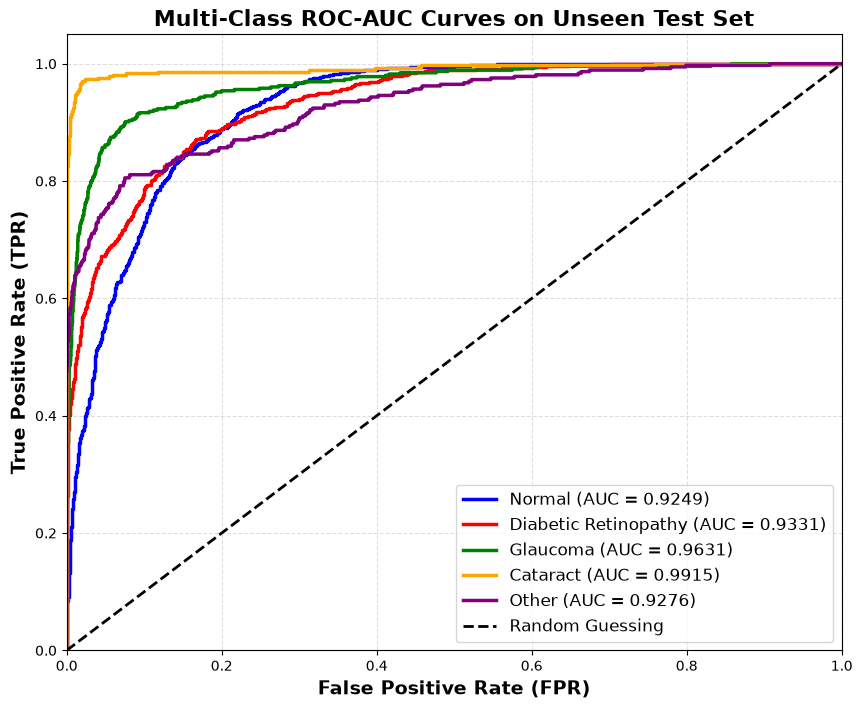

In [56]:
print("="*70)
print(" 📈 MULTI-CLASS ROC-AUC CURVES (UNSEEN TEST SET) ")
print("="*70)

plt.figure(figsize=(10, 8))
colors = ['blue', 'red', 'green', 'orange', 'purple']

# Assuming y_true and y_pred_probs are already calculated from test_generator
for i, color in enumerate(colors):
    fpr, tpr, _ = roc_curve(y_true[:, i], y_pred_probs[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=color, lw=2.5,
             label=f'{class_names[i]} (AUC = {roc_auc:.4f})')

# Plot random guess baseline
plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Random Guessing')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)', fontsize=14, fontweight='bold')
plt.ylabel('True Positive Rate (TPR)', fontsize=14, fontweight='bold')
plt.title('Multi-Class ROC-AUC Curves on Unseen Test Set', fontsize=16, fontweight='bold')
plt.legend(loc="lower right", fontsize=12)
plt.grid(alpha=0.4, linestyle='--')

# Save the plot for thesis
plt.savefig(os.path.join(RESULTS_FIGURE_DIR, 'test_roc_auc_curve.png'), dpi=300, bbox_inches='tight')
print(f"✅ Graph saved as 'test_roc_auc_curve.png' in {RESULTS_FIGURE_DIR}")
plt.show()

 📈 MULTI-CLASS PRECISION-RECALL CURVES (UNSEEN TEST SET) 
✅ Graph saved as 'test_pr_curve.png' in c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\outputs\ocular_figures


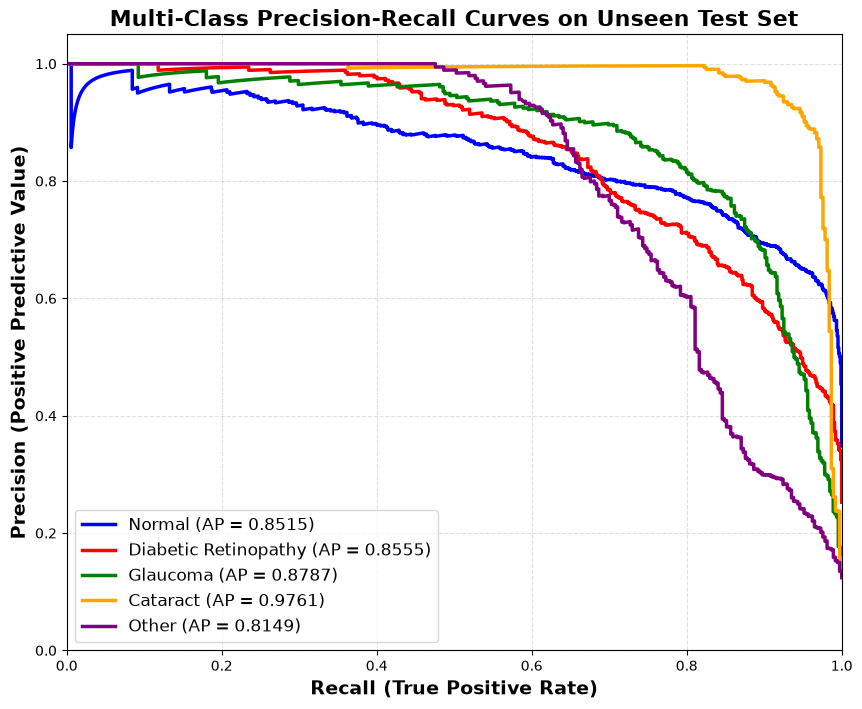

In [57]:
print("="*70)
print(" 📈 MULTI-CLASS PRECISION-RECALL CURVES (UNSEEN TEST SET) ")
print("="*70)

plt.figure(figsize=(10, 8))
colors = ['blue', 'red', 'green', 'orange', 'purple']

# Calculate and plot PR curve for each class
for i, color in enumerate(colors):
    precision, recall, _ = precision_recall_curve(y_true[:, i], y_pred_probs[:, i])
    ap_score = average_precision_score(y_true[:, i], y_pred_probs[:, i])
    plt.plot(recall, precision, color=color, lw=2.5,
             label=f'{class_names[i]} (AP = {ap_score:.4f})')

# Baseline (random guess based on positive class prevalence)
# plt.plot([0, 1], [0.5, 0.5], 'k--', lw=2, label='Baseline')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall (True Positive Rate)', fontsize=14, fontweight='bold')
plt.ylabel('Precision (Positive Predictive Value)', fontsize=14, fontweight='bold')
plt.title('Multi-Class Precision-Recall Curves on Unseen Test Set', fontsize=16, fontweight='bold')
plt.legend(loc="lower left", fontsize=12)
plt.grid(alpha=0.4, linestyle='--')

# Save the plot for thesis
plt.savefig(os.path.join(RESULTS_FIGURE_DIR, 'test_pr_curve.png'), dpi=300, bbox_inches='tight')
print(f"✅ Graph saved as 'test_pr_curve.png' in {RESULTS_FIGURE_DIR}")
plt.show()

 📊 PER-CLASS MULTI-LABEL CONFUSION MATRICES (UNSEEN TEST SET) 
✅ Graph saved as 'test_confusion_matrix.png' in c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\outputs\ocular_figures


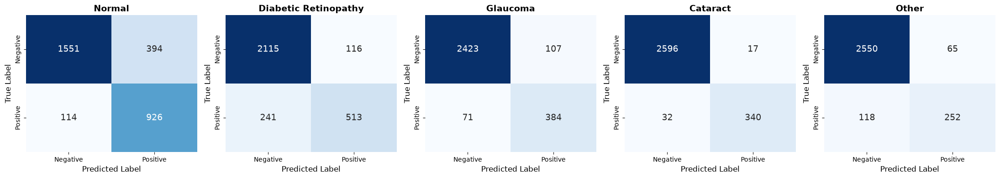

In [58]:
print("="*70)
print(" 📊 PER-CLASS MULTI-LABEL CONFUSION MATRICES (UNSEEN TEST SET) ")
print("="*70)

# Calculate multi-label confusion matrix for the test set
mcm = multilabel_confusion_matrix(y_true, y_pred_binary)

fig, axes = plt.subplots(1, len(class_names), figsize=(22, 4))
for i, (ax, cm, name) in enumerate(zip(axes, mcm, class_names)):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                xticklabels=['Negative', 'Positive'],
                yticklabels=['Negative', 'Positive'],
                annot_kws={"size": 14})
    ax.set_title(f'{name}', fontsize=14, fontweight='bold')
    ax.set_xlabel('Predicted Label', fontsize=12)
    ax.set_ylabel('True Label', fontsize=12)

plt.tight_layout()

# Save the plot for thesis
plt.savefig(os.path.join(RESULTS_FIGURE_DIR, 'test_confusion_matrix.png'), dpi=300, bbox_inches='tight')
print(f"✅ Graph saved as 'test_confusion_matrix.png' in {RESULTS_FIGURE_DIR}")
plt.show()

<div style="font-size: 13px; line-height: 1.6;">

## 11. Explainable AI (XAI) & Error Analysis
### 11.1 Grad-CAM Visual Explanations
Grad-CAM on the last convolutional block (`conv5_block16_concat`) of the fine-tuned DenseNet121 highlights the retinal regions that drive each prediction.

</div>


 🔬 Generating Grad-CAM Heatmap for DenseNet121 🔬 
✅ DenseNet121 Model Loaded Successfully!


c:\Users\LIN LS\.venvs\thesis312\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['input_layer']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


True Label     : Normal
Predicted Label: Normal (Confidence: 89.61%)


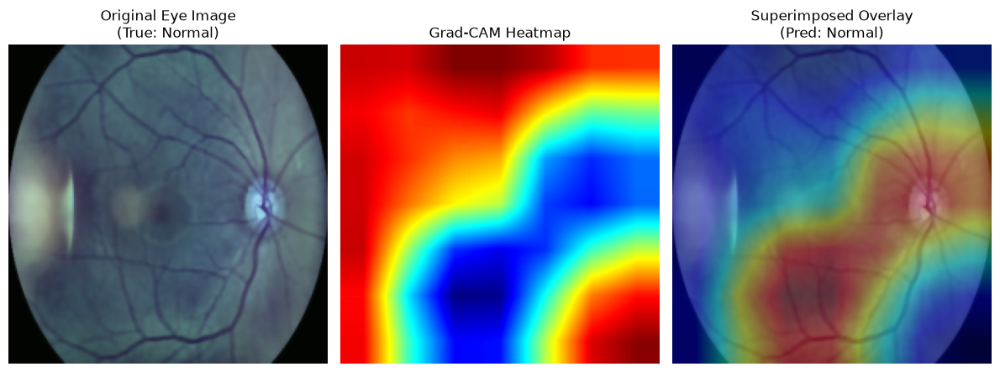

In [59]:
# আপনার ক্লাসের নামগুলো
CLASS_NAMES = ['Normal', 'Diabetes', 'Glaucoma', 'Cataract', 'Other']

print("\n=======================================================")
print(" 🔬 Generating Grad-CAM Heatmap for DenseNet121 🔬 ")
print("=======================================================")

# আপনার সঠিক পাথ
DENSENET_PATH = CHECKPOINT_PATH_PHASE2

try:
    model = tf.keras.models.load_model(DENSENET_PATH, compile=False)
    print("✅ DenseNet121 Model Loaded Successfully!")
except Exception as e:
    print(f"❌ Error loading model: {e}")

# DenseNet121 এর শেষ কনভল্যুশনাল লেয়ারের নাম
last_conv_layer_name = 'conv5_block16_concat'

# ১. টেস্ট জেনারেটর থেকে একটি স্যাম্পল ছবি এবং তার রিয়েল লেবেল তুলে নেওয়া
test_images, test_labels = next(iter(test_generator))
sample_image = test_images[0]
true_label_idx = np.argmax(test_labels[0])
true_label_name = CLASS_NAMES[true_label_idx]

# মডেল প্রেডিকশনের জন্য ছবিকে ব্যাচ ডায়মেনশনে রূপান্তর
img_array = np.expand_dims(sample_image, axis=0)

# ২. Standard Grad-CAM ফাংশন (যা ১০০% এরর-মুক্ত)
def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    grad_model = tf.keras.models.Model(
        [model.inputs], [model.get_layer(last_conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        loss = predictions[:, pred_index]

    # গ্রেডিয়েন্ট বের করা
    grads = tape.gradient(loss, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), predictions[0]

# ৩. হিটম্যাপ জেনারেট করা
heatmap, raw_preds = make_gradcam_heatmap(img_array, model, last_conv_layer_name)
pred_label_idx = np.argmax(raw_preds)
pred_label_name = CLASS_NAMES[pred_label_idx]

print(f"True Label     : {true_label_name}")
print(f"Predicted Label: {pred_label_name} (Confidence: {raw_preds[pred_label_idx]*100:.2f}%)")

# ৪. অরিজিনাল ছবির ওপর হিটম্যাপ ওভারলে (Overlay) করা
original_img = sample_image.copy()
if original_img.max() <= 1.0:
    original_img = (original_img * 255).astype(np.uint8)
else:
    original_img = original_img.astype(np.uint8)

heatmap = cv2.resize(heatmap, (original_img.shape[1], original_img.shape[0]))
heatmap = np.uint8(255 * heatmap)
heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

superimposed_img = cv2.addWeighted(original_img, 0.6, heatmap, 0.4, 0)

# ৫. প্লট করে স্ক্রিনশট বা সেভ করার ব্যবস্থা করা
plt.figure(figsize=(12, 6))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB))
plt.title(f"Original Eye Image\n(True: {true_label_name})", fontsize=12)
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(heatmap)
plt.title("Grad-CAM Heatmap", fontsize=12)
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(superimposed_img, cv2.COLOR_BGR2RGB))
plt.title(f"Superimposed Overlay\n(Pred: {pred_label_name})", fontsize=12)
plt.axis('off')

plt.tight_layout()
plt.show()

 🧠 MULTI-CLASS GRAD-CAM SPATIAL FEATURE LOCALIZATION HEATMAPS 


c:\Users\LIN LS\.venvs\thesis312\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['input_layer']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


✅ Graph saved as 'c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\outputs\ocular_figures\grad_cam_spatial_features.png'


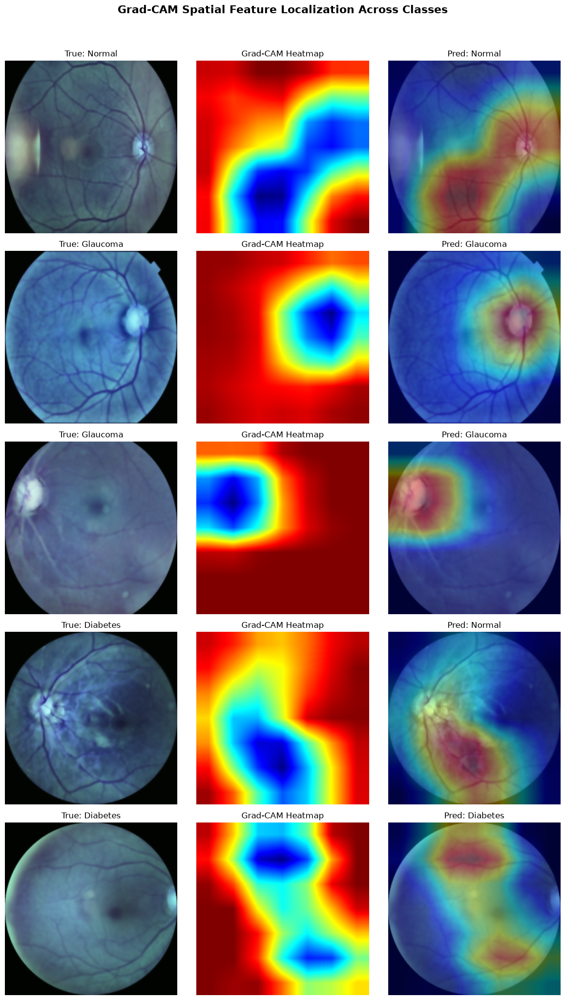

In [60]:
print("="*70)
print(" 🧠 MULTI-CLASS GRAD-CAM SPATIAL FEATURE LOCALIZATION HEATMAPS ")
print("="*70)

# Assuming `make_gradcam_heatmap`, `model`, `test_generator`, and `CLASS_NAMES` are defined in the previous cell
last_conv_layer_name = 'conv5_block16_concat'

# Select a few random batches to find diverse classes
num_samples = 5
selected_images = []
true_labels_list = []
pred_labels_list = []
heatmaps = []

for i in range(len(test_generator)):
    x_batch, y_batch = test_generator[i]
    preds = model.predict(x_batch, verbose=0)

    for j in range(len(x_batch)):
        if len(selected_images) >= num_samples:
            break
        img = x_batch[j]
        true_idx = np.argmax(y_batch[j])
        pred_idx = np.argmax(preds[j])

        img_array = np.expand_dims(img, axis=0)
        heatmap, _ = make_gradcam_heatmap(img_array, model, last_conv_layer_name)

        selected_images.append(img)
        true_labels_list.append(CLASS_NAMES[true_idx])
        pred_labels_list.append(CLASS_NAMES[pred_idx])
        heatmaps.append(heatmap)

    if len(selected_images) >= num_samples:
        break

# Plotting the grid
fig, axes = plt.subplots(num_samples, 3, figsize=(12, 4 * num_samples))

for i in range(num_samples):
    orig_img = selected_images[i].copy()
    if orig_img.max() <= 1.0:
        orig_img = (orig_img * 255).astype(np.uint8)
    else:
        orig_img = orig_img.astype(np.uint8)

    hm = heatmaps[i]
    hm_resized = cv2.resize(hm, (orig_img.shape[1], orig_img.shape[0]))
    hm_resized = np.uint8(255 * hm_resized)
    hm_colored = cv2.applyColorMap(hm_resized, cv2.COLORMAP_JET)

    superimposed = cv2.addWeighted(orig_img, 0.6, hm_colored, 0.4, 0)

    # 1. Original Image
    axes[i, 0].imshow(cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB))
    axes[i, 0].set_title(f"True: {true_labels_list[i]}", fontsize=12)
    axes[i, 0].axis('off')

    # 2. Heatmap
    axes[i, 1].imshow(hm_colored)
    axes[i, 1].set_title("Grad-CAM Heatmap", fontsize=12)
    axes[i, 1].axis('off')

    # 3. Superimposed
    axes[i, 2].imshow(cv2.cvtColor(superimposed, cv2.COLOR_BGR2RGB))
    axes[i, 2].set_title(f"Pred: {pred_labels_list[i]}", fontsize=12)
    axes[i, 2].axis('off')

plt.suptitle("Grad-CAM Spatial Feature Localization Across Classes", fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()

# Save the graph
save_path = os.path.join(RESULTS_FIGURE_DIR, 'grad_cam_spatial_features.png')
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"✅ Graph saved as '{save_path}'")
plt.show()

<div style="font-size: 13px; line-height: 1.6;">

### 11.2 AI Uncertainty / Confidence Score
<span style="font-size: 0.9em;">মডেলের প্রেডিকশন প্রোবাবিলিটি থেকে</span> Binary Entropy <span style="font-size: 0.9em;">ব্যবহার করে</span> **Confidence Score** <span style="font-size: 0.9em;">ক্যালকুলেট করার লজিক, যাতে ইউজার বুঝতে পারে</span> AI <span style="font-size: 0.9em;">তার প্রেডিকশন নিয়ে কতটা নিশ্চিত (শিওর)। এখানে মডেলকে নতুন করে ট্রেইন করার প্রয়োজন নেই</span>।

</div>

In [61]:
def calculate_confidence(probability):
    """
    Calculates AI Confidence using Binary Entropy.
    Probabilities near 0.5 mean high uncertainty (Entropy ~ 1, Confidence ~ 0).
    Probabilities near 0 or 1 mean high certainty (Entropy ~ 0, Confidence ~ 1).
    """
    # Clip probability to avoid log(0)
    p = np.clip(probability, 1e-7, 1 - 1e-7)

    # Binary Entropy Formula: H(p) = -p*log2(p) - (1-p)*log2(1-p)
    entropy = - (p * np.log2(p) + (1 - p) * np.log2(1 - p))

    # Confidence is inversely proportional to Entropy
    confidence_score = 1.0 - entropy

    if confidence_score >= 0.8:
        level = "High"
    elif confidence_score >= 0.4:
        level = "Medium"
    else:
        level = "Low"

    return confidence_score, level

def predict_with_confidence(model, img_array, class_names):
    print("\n=======================================================")
    print(" PREDICTION WITH AI CONFIDENCE SCORE ")
    print("=======================================================")

    # Get raw probabilities from the model
    preds = model.predict(img_array, verbose=0)[0]

    for i, p in enumerate(preds):
        conf_score, conf_level = calculate_confidence(p)

        # Usually, probability >= 0.5 is considered a Positive detection
        status = "Detected" if p >= 0.5 else "Not Detected"

        print(f"ὓ9 {class_names[i]:>20s} : {status:>12s} | Prob: {p*100:>5.1f}% | AI Confidence: {conf_level:<6s} ({conf_score:.2f})")

# ---- Testing it on a sample image ----
# Taking a sample from the test generator
test_images, test_labels = next(iter(test_generator))
sample_img_array = np.expand_dims(test_images[0], axis=0)

# CLASS_NAMES is already defined as ['Normal', 'Diabetes', 'Glaucoma', 'Cataract', 'Other']
predict_with_confidence(model, sample_img_array, CLASS_NAMES)



 PREDICTION WITH AI CONFIDENCE SCORE 
ὓ9               Normal :     Detected | Prob:  89.6% | AI Confidence: Medium (0.52)
ὓ9             Diabetes : Not Detected | Prob:  38.0% | AI Confidence: Low    (0.04)
ὓ9             Glaucoma : Not Detected | Prob:  22.8% | AI Confidence: Low    (0.23)
ὓ9             Cataract : Not Detected | Prob:   7.9% | AI Confidence: Medium (0.60)
ὓ9                Other : Not Detected | Prob:  20.4% | AI Confidence: Low    (0.27)


 🎯 ACTUAL GROUND TRUTH (আসল লেবেল) : Normal


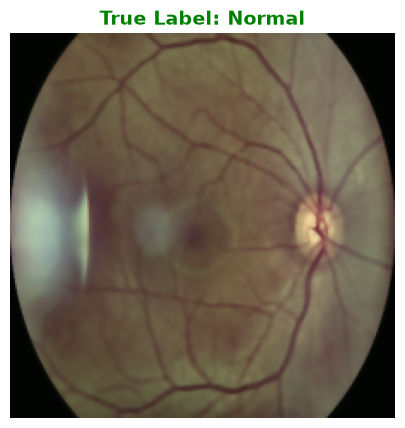

In [62]:
# আগের সেলের test_labels থেকে আসল লেবেল (Ground Truth) বের করছি
true_label_indices = np.where(test_labels[0] == 1)[0]
true_classes = [CLASS_NAMES[i] for i in true_label_indices]

print("=======================================================")
print(f" 🎯 ACTUAL GROUND TRUTH (আসল লেবেল) : {', '.join(true_classes)}")
print("=======================================================")

# ছবিটি প্রিন্ট করে দেখছি
plt.figure(figsize=(5, 5))
# test_images[0] হলো আগের সেলের স্যাম্পল ছবিটি
plt.imshow(test_images[0])
plt.title(f"True Label: {', '.join(true_classes)}", fontsize=14, fontweight='bold', color='green')
plt.axis('off')
plt.show()

<div style="font-size: 13px; line-height: 1.6;">

### 11.3 Error Analysis — Misclassified Test Images

</div>


 🔍 Error Analysis: Finding Misclassified Images 


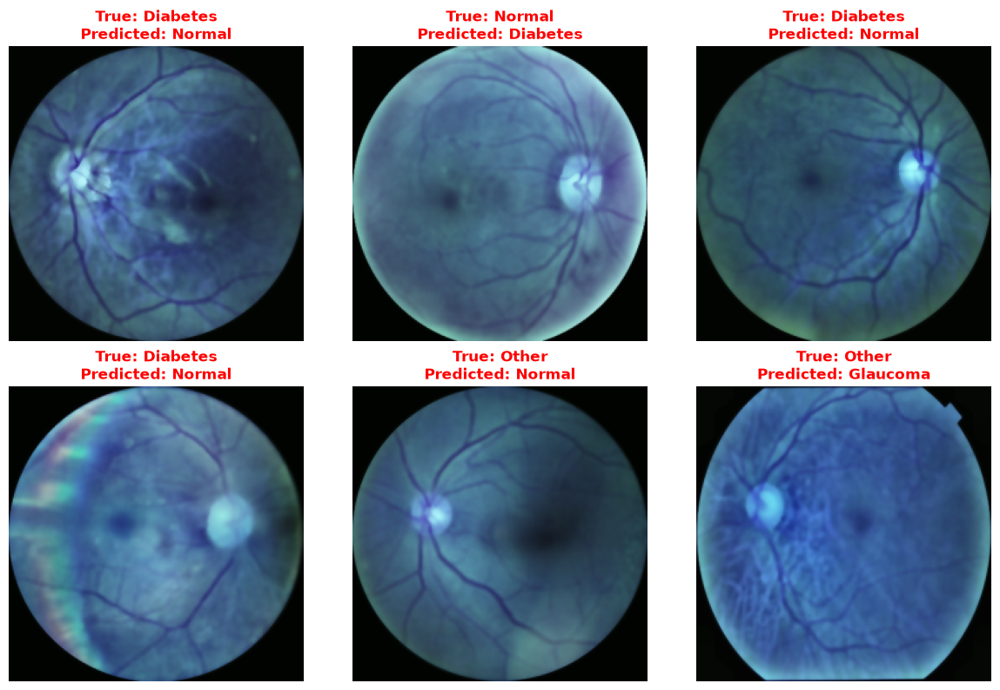

In [63]:
print("\n=======================================================")
print(" 🔍 Error Analysis: Finding Misclassified Images ")
print("=======================================================")

misclassified_imgs = []
true_labels = []
pred_labels = []

# জেনারেটর থেকে ব্যাচ অনুযায়ী ডেটা নিয়ে চেক করা (RAM বাঁচানোর জন্য)
for i in range(len(test_generator)):
    x_batch, y_batch = test_generator[i]

    # ব্যাচের উপর প্রেডিকশন
    preds = model.predict(x_batch, verbose=0)

    y_true_batch = np.argmax(y_batch, axis=1)
    y_pred_batch = np.argmax(preds, axis=1)

    # ভুল প্রেডিকশনগুলো ফিল্টার করা
    for j in range(len(y_true_batch)):
        if y_true_batch[j] != y_pred_batch[j]:
            misclassified_imgs.append(x_batch[j])
            true_labels.append(CLASS_NAMES[y_true_batch[j]])
            pred_labels.append(CLASS_NAMES[y_pred_batch[j]])

        # ৬টি ছবি পেলেই লুপ ব্রেক করবে
        if len(misclassified_imgs) >= 6:
            break
    if len(misclassified_imgs) >= 6:
        break

# ছবিগুলো প্লট করা
plt.figure(figsize=(12, 8))
for i in range(len(misclassified_imgs)):
    plt.subplot(2, 3, i + 1)

    img = misclassified_imgs[i].copy()
    if img.max() <= 1.0:
        img = (img * 255).astype(np.uint8)
    else:
        img = img.astype(np.uint8)

    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    # টাইটেলে ট্রু লেবেল এবং প্রেডিক্টেড লেবেল দেখানো হচ্ছে
    plt.title(f"True: {true_labels[i]}\nPredicted: {pred_labels[i]}", color='red', fontsize=12, fontweight='bold')
    plt.axis('off')

plt.tight_layout()
plt.show()

<div style="font-size: 13px; line-height: 1.6;">

## 12. Comparative Study — DenseNet121 vs ResNet50 vs EfficientNetB0
### 12.1 Experimental Protocol
To isolate the effect of the backbone, every model is trained and evaluated with **exactly the same protocol and code**; only the backbone changes.

#### Table 12.1 — Training & Evaluation Protocol (identical for every experiment in Sections 12–13)

| Component | Setting |
| :--- | :--- |
| Data | Same blur-filtered master dataset, same patient-aware train / val / test split (Section 6.3), same cached preprocessed images (Section 7) |
| Input | 224×224×3 from the preprocessing pipeline (Section 5) + each backbone's native ImageNet input normalization (`BackbonePreprocess`) |
| Classification head | GAP → Dropout(0.5) → Dense(512, ReLU) → Dropout(0.5) → Dense(5, sigmoid) |
| Phase 1 | Frozen backbone · Adam (`INITIAL_LR`) · `EPOCHS_PHASE1` epochs · ASL (γ⁻ = `ASL_GAMMA_NEG_PHASE1`) · ReduceLROnPlateau |
| Phase 2 | Unfrozen backbone · Adam (`PHASE2_LR`) · ≤ `EPOCHS_PHASE2` epochs · ASL (γ⁻ = `ASL_GAMMA_NEG_PHASE2`) · ReduceLROnPlateau + EarlyStopping |
| Model selection | Epoch with the lowest validation loss |
| Decision thresholds | Per class, maximizing F1 on the validation set; frozen for the test set |
| Test metrics | Macro / micro ROC-AUC, mAP, macro precision / recall / F1, micro F1, Hamming loss, exact-match accuracy, per-class AUC & F1 |
| Uncertainty | Mean ± std over `EXPERIMENT_SEEDS`; 95% bootstrap CIs and paired bootstrap tests (`N_BOOTSTRAP` resamples) on the test set |
| Efficiency | Parameters, wall-clock training time, inference latency (ms / image, batch of 32) |

#### Table 12.2 — Backbones Under Comparison

| Model | Role | Key architectural idea | ImageNet input normalization | Grad-CAM layer |
| :--- | :--- | :--- | :--- | :--- |
| **DenseNet121** | **Proposed** | Dense connectivity → feature reuse, strong gradient flow | mean / std (`torch`) | `conv5_block16_concat` |
| ResNet50 | Comparison | Residual learning with bottleneck blocks | BGR, mean-subtracted (`caffe`) | `conv5_block3_out` |
| EfficientNetB0 | Comparison | Compound scaling, MBConv + squeeze-excitation | 0–255, rescaled internally | `top_activation` |

> **Note.** The proposed DenseNet121 is retrained here with the same runner, so every row of every table comes from identical code. Its numbers can therefore differ slightly from the development run in Sections 9–10.
>
> **Prerequisites & runtime.** Sections 1–8 must have been run (generators, `build_model`, `asymmetric_loss`). Each experiment is a full two-phase training run. Weights, logs, predictions and results are written to `EXPERIMENT_DIR` after every phase, plus a resume point after every epoch — if Colab disconnects, re-run the same cell: finished work is skipped and an interrupted phase continues from its last finished epoch.

</div>

<div style="font-size: 13px; line-height: 1.6;">

### 12.2 Experiment Runner & Reporting Tools
`run_experiment()` trains one configuration with the protocol of Table 12.1 and stores everything on Drive. The reporting helpers build the publication tables (best value in **bold**), bootstrap statistics and figures, and export them to `EXPERIMENT_DIR/tables` and `EXPERIMENT_DIR/figures`.

</div>

In [64]:
# ============================================================
# Unified experiment runner (shared by Sections 12 and 13)
# ============================================================
import shutil

CLASS_LABELS = ['Normal', 'Diabetic Retinopathy', 'Glaucoma', 'Cataract', 'Other']
TABLES_DIR  = os.path.join(EXPERIMENT_DIR, 'tables')
FIGURES_DIR = os.path.join(EXPERIMENT_DIR, 'figures')
for d in (EXPERIMENT_DIR, TABLES_DIR, FIGURES_DIR):
    os.makedirs(d, exist_ok=True)

# Ground truth in generator order (validation / test generators use shuffle=False)
y_val_true  = np.stack(val_df['target_list'].values).astype(np.float32)
y_test_true = np.stack(test_df['target_list'].values).astype(np.float32)


def experiment_id(backbone, attention=None, seed=RANDOM_STATE):
    return f"{backbone}_{attention or 'none'}_seed{seed}"


def experiment_dir(backbone, attention=None, seed=RANDOM_STATE):
    return os.path.join(EXPERIMENT_DIR, experiment_id(backbone, attention, seed))


def find_optimal_thresholds(y_true, y_prob):
    """Per-class threshold that maximizes F1 (tuned on the validation set)."""
    thresholds = []
    for i in range(y_true.shape[1]):
        precision, recall, ths = precision_recall_curve(y_true[:, i], y_prob[:, i])
        f1 = 2 * precision * recall / (precision + recall + 1e-10)
        best = int(np.argmax(f1))
        thresholds.append(float(ths[best]) if best < len(ths) else 0.5)
    return np.array(thresholds)


def compute_metrics(y_true, y_prob, thresholds):
    y_pred = (y_prob >= thresholds).astype(int)
    metrics = {
        'macro_auc':       roc_auc_score(y_true, y_prob, average='macro'),
        'micro_auc':       roc_auc_score(y_true, y_prob, average='micro'),
        'map':             average_precision_score(y_true, y_prob, average='macro'),
        'macro_precision': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'macro_recall':    recall_score(y_true, y_pred, average='macro', zero_division=0),
        'macro_f1':        f1_score(y_true, y_pred, average='macro', zero_division=0),
        'micro_f1':        f1_score(y_true, y_pred, average='micro', zero_division=0),
        'weighted_f1':     f1_score(y_true, y_pred, average='weighted', zero_division=0),
        'hamming_loss':    hamming_loss(y_true, y_pred),
        'subset_accuracy': accuracy_score(y_true, y_pred),
        'per_class_auc':   roc_auc_score(y_true, y_prob, average=None),
        'per_class_ap':    average_precision_score(y_true, y_prob, average=None),
        'per_class_f1':    f1_score(y_true, y_pred, average=None, zero_division=0),
    }
    return {k: (v.tolist() if isinstance(v, np.ndarray) else float(v)) for k, v in metrics.items()}


def measure_latency_ms(model, generator, reps=20):
    """Pure model inference time per image (one batch, after a warm-up call)."""
    X, _ = generator[0]
    model(X, training=False).numpy()
    start = time.perf_counter()
    for _ in range(reps):
        model(X, training=False).numpy()
    return (time.perf_counter() - start) / (reps * len(X)) * 1000


class EpochTimer(tf.keras.callbacks.Callback):
    """Adds each epoch's wall-clock time to the logs, so it is written to the per-epoch CSV log."""

    def on_epoch_begin(self, epoch, logs=None):
        self._start = time.time()

    def on_epoch_end(self, epoch, logs=None):
        if logs is not None:
            logs['epoch_time_sec'] = time.time() - self._start


def _read_epoch_log(csv_path):
    """Per-epoch CSV log -> DataFrame; an epoch repeated by a resumed run keeps its last row."""
    df = pd.read_csv(csv_path)
    return df.drop_duplicates('epoch', keep='last').sort_values('epoch').reset_index(drop=True)


def _run_phase(model, phase, exp_dir, epochs, lr, gamma_neg, min_lr, early_stopping, force):
    """Trains one phase, or restores it from Drive if it already finished (resumable).
    If a phase is interrupted, re-running resumes it from its last finished epoch
    (BackupAndRestore + per-epoch CSV log in the experiment folder)."""
    weights_path = os.path.join(exp_dir, f'{phase}_best.weights.h5')
    log_path = os.path.join(exp_dir, f'{phase}_log.json')
    epoch_log_path = os.path.join(exp_dir, f'{phase}_epoch_log.csv')
    backup_dir = os.path.join(exp_dir, f'{phase}_backup')
    if os.path.exists(log_path) and os.path.exists(weights_path) and not force:
        print(f"   ⏭️  {phase}: already completed — restoring its best weights from Drive.")
        with open(log_path) as f:
            log = json.load(f)
    else:
        if force:
            shutil.rmtree(backup_dir, ignore_errors=True)
        resuming = os.path.exists(os.path.join(backup_dir, 'training_metadata.json'))
        if not resuming and os.path.exists(epoch_log_path):
            os.remove(epoch_log_path)   # log of a run that never finished an epoch
        best_so_far = None   # on resume: best val_loss before the interruption (protects the best checkpoint)
        if resuming and os.path.exists(epoch_log_path) and os.path.exists(weights_path):
            previous_epochs = _read_epoch_log(epoch_log_path)
            if len(previous_epochs):
                best_so_far = float(previous_epochs['val_loss'].min())
        print(f"   ▶️  {phase}: lr={lr}, ASL gamma_neg={gamma_neg}, max epochs={epochs}"
              + ("  (resuming from the last finished epoch)" if resuming else ""))
        model.compile(optimizer=Adam(learning_rate=lr),
                      loss=asymmetric_loss(gamma_neg=gamma_neg, gamma_pos=ASL_GAMMA_POS),
                      metrics=['binary_accuracy', tf.keras.metrics.AUC(multi_label=True, name='auc')])
        callbacks = [
            ModelCheckpoint(weights_path, monitor='val_loss', mode='min', save_best_only=True,
                            save_weights_only=True, verbose=1, initial_value_threshold=best_so_far),
            ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=2, min_lr=min_lr, verbose=1),
            EpochTimer(),
            tf.keras.callbacks.CSVLogger(epoch_log_path, append=True),   # per-epoch log on Drive
            tf.keras.callbacks.BackupAndRestore(backup_dir),             # resume point after every epoch
        ]
        if early_stopping:
            callbacks.append(EarlyStopping(monitor='val_loss', patience=EARLY_STOP_PATIENCE,
                                           restore_best_weights=True, verbose=1))
        model.fit(train_generator, epochs=epochs, validation_data=val_generator, callbacks=callbacks,
                  steps_per_epoch=len(train_generator), validation_steps=len(val_generator))
        epoch_log = _read_epoch_log(epoch_log_path)   # every epoch, including those before a resume
        log = {'history': {c: epoch_log[c].astype(float).tolist() for c in epoch_log.columns
                           if c not in ('epoch', 'epoch_time_sec')},
               'time_sec': float(epoch_log['epoch_time_sec'].sum())}
        with open(log_path, 'w') as f:
            json.dump(log, f)
    model.load_weights(weights_path)
    return log


def run_experiment(backbone, attention=None, seed=RANDOM_STATE, force=False):
    """Trains (or restores) one backbone / attention configuration with the protocol of
    Table 12.1 and returns its evaluation results. Fully resumable through EXPERIMENT_DIR."""
    exp_id, exp_dir = experiment_id(backbone, attention, seed), experiment_dir(backbone, attention, seed)
    result_path = os.path.join(exp_dir, 'results.json')
    if os.path.exists(result_path) and not force:
        print(f"⏭️  {exp_id}: finished results found on Drive — skipped.")
        with open(result_path) as f:
            return json.load(f)

    print(f"\n{'=' * 70}\n🚀 EXPERIMENT: {exp_id}\n{'=' * 70}")
    os.makedirs(exp_dir, exist_ok=True)
    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(seed)

    model, base = build_model(backbone, NUM_CLASSES, attention=attention, backbone_preprocessing=True)
    print(f"   Parameters: {model.count_params():,}")

    log1 = _run_phase(model, 'phase1', exp_dir, EPOCHS_PHASE1, INITIAL_LR, ASL_GAMMA_NEG_PHASE1, 1e-6, False, force)
    base.trainable = True
    log2 = _run_phase(model, 'phase2', exp_dir, EPOCHS_PHASE2, PHASE2_LR, ASL_GAMMA_NEG_PHASE2, 1e-7, True, force)

    val_prob = model.predict(val_generator, verbose=0)
    test_prob = model.predict(test_generator, verbose=0)
    assert len(val_prob) == len(y_val_true) and len(test_prob) == len(y_test_true)
    thresholds = find_optimal_thresholds(y_val_true, val_prob)

    result = {
        'exp_id': exp_id, 'backbone': backbone, 'attention': attention or 'none', 'seed': seed,
        'params_total': int(model.count_params()),
        'train_time_min': (log1['time_sec'] + log2['time_sec']) / 60,
        'epochs_phase1': len(log1['history']['loss']),
        'epochs_phase2': len(log2['history']['loss']),
        'latency_ms_per_image': measure_latency_ms(model, test_generator),
        'thresholds': thresholds.tolist(),
        'val': compute_metrics(y_val_true, val_prob, thresholds),
        'test': compute_metrics(y_test_true, test_prob, thresholds),
        'history': {'phase1': log1['history'], 'phase2': log2['history']},
    }
    np.savez_compressed(os.path.join(exp_dir, 'predictions.npz'),
                        val_prob=val_prob, test_prob=test_prob, thresholds=thresholds)
    with open(result_path, 'w') as f:
        json.dump(result, f, indent=2)

    t = result['test']
    print(f"✅ {exp_id}: test Macro AUC = {t['macro_auc']:.4f} | mAP = {t['map']:.4f} | Macro F1 = {t['macro_f1']:.4f}")
    del model, base
    tf.keras.backend.clear_session()
    gc.collect()
    return result


def load_predictions(backbone, attention=None, seed=RANDOM_STATE):
    return dict(np.load(os.path.join(experiment_dir(backbone, attention, seed), 'predictions.npz')))


def load_experiment_model(backbone, attention=None, seed=RANDOM_STATE):
    model, _ = build_model(backbone, NUM_CLASSES, attention=attention, backbone_preprocessing=True)
    model.load_weights(os.path.join(experiment_dir(backbone, attention, seed), 'phase2_best.weights.h5'))
    return model


print(f"✅ Experiment runner ready. Results folder: {EXPERIMENT_DIR}")

✅ Experiment runner ready. Results folder: c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\outputs\ocular_experiments


In [65]:
# ============================================================
# Reporting helpers: publication tables, bootstrap statistics, figures
# ============================================================
METRICS = [  # (result key, column label, higher is better)
    ('macro_auc', 'Macro AUC', True),
    ('micro_auc', 'Micro AUC', True),
    ('map', 'mAP', True),
    ('macro_precision', 'Macro Precision', True),
    ('macro_recall', 'Macro Recall', True),
    ('macro_f1', 'Macro F1', True),
    ('micro_f1', 'Micro F1', True),
    ('hamming_loss', 'Hamming Loss', False),
    ('subset_accuracy', 'Exact-Match Acc.', True),
]
EFFICIENCY = [  # (result key, column label, scale, higher is better)
    ('params_total', 'Params (M)', 1e-6, False),
    ('train_time_min', 'Train Time (min)', 1, False),
    ('latency_ms_per_image', 'Latency (ms/img)', 1, False),
]
HIGHER_IS_BETTER = {label: hb for _, label, hb in METRICS} | {label: hb for _, label, _, hb in EFFICIENCY}
DECIMALS = {'Params (M)': 2, 'Train Time (min)': 1, 'Latency (ms/img)': 2}


def _mean_std(values):
    v = np.asarray(values, dtype=float)
    return v.mean(), (v.std(ddof=1) if len(v) > 1 else np.nan)


def summary_frames(runs_by_model, split='test'):
    """(mean, std) DataFrames — rows: models, columns: metrics + efficiency."""
    mean, std = {}, {}
    for name, runs in runs_by_model.items():
        mean[name], std[name] = {}, {}
        for key, label, _ in METRICS:
            mean[name][label], std[name][label] = _mean_std([r[split][key] for r in runs])
        for key, label, scale, _ in EFFICIENCY:
            mean[name][label], std[name][label] = _mean_std([r[key] * scale for r in runs])
    return pd.DataFrame(mean).T, pd.DataFrame(std).T


def per_class_frames(runs_by_model, key, split='test'):
    """(mean, std) DataFrames — rows: models, columns: the five classes."""
    mean, std = {}, {}
    for name, runs in runs_by_model.items():
        values = np.array([r[split][key] for r in runs])
        mean[name] = values.mean(axis=0)
        std[name] = values.std(axis=0, ddof=1) if len(runs) > 1 else np.full(len(CLASS_LABELS), np.nan)
    return pd.DataFrame(mean, index=CLASS_LABELS).T, pd.DataFrame(std, index=CLASS_LABELS).T


def _fmt(m, s, decimals, signed=False):
    if pd.isna(m):
        return '–'
    text = f"{m:+.{decimals}f}" if signed else f"{m:.{decimals}f}"
    return text + (f" ± {s:.{decimals}f}" if not pd.isna(s) else '')


def _tex(s):
    s = str(s)
    for a, b in [('\\', r'\textbackslash{}'), ('&', r'\&'), ('%', r'\%'), ('_', r'\_'), ('#', r'\#')]:
        s = s.replace(a, b)
    for a, b in [('±', r'$\pm$'), ('Δ', r'$\Delta$'), ('→', r'$\rightarrow$'), ('<', r'$<$'), ('–', '--')]:
        s = s.replace(a, b)
    return s


def export_text_table(text_df, title, file_stem, best=None, index_label='Model', write_csv=False):
    """Writes a formatted table as Markdown and LaTeX (booktabs); best cells in bold."""
    best = best or {}
    md_lines = ['| ' + ' | '.join([index_label] + list(text_df.columns)) + ' |',
                '|' + ' :--- |' + ' :---: |' * len(text_df.columns)]
    tex_rows = []
    for idx, row in text_df.iterrows():
        md_cells, tex_cells = [], []
        for col, val in row.items():
            is_best = best.get(col) == idx
            md_cells.append(f'**{val}**' if is_best else str(val))
            tex_cells.append(rf'\textbf{{{_tex(val)}}}' if is_best else _tex(val))
        md_lines.append('| ' + ' | '.join([str(idx)] + md_cells) + ' |')
        tex_rows.append(' & '.join([_tex(idx)] + tex_cells) + r' \\')
    latex = '\n'.join([
        r'\begin{table}[t]', r'\centering', rf'\caption{{{_tex(title)}}}', rf'\label{{tab:{file_stem}}}',
        r'\resizebox{\linewidth}{!}{%', r'\begin{tabular}{l' + 'c' * len(text_df.columns) + '}', r'\toprule',
        ' & '.join([_tex(index_label)] + [_tex(c) for c in text_df.columns]) + r' \\', r'\midrule',
        *tex_rows, r'\bottomrule', r'\end{tabular}}', r'\end{table}'])
    with open(os.path.join(TABLES_DIR, f'{file_stem}.md'), 'w', encoding='utf-8') as f:
        f.write(f'**{title}**\n\n' + '\n'.join(md_lines) + '\n')
    with open(os.path.join(TABLES_DIR, f'{file_stem}.tex'), 'w', encoding='utf-8') as f:
        f.write(latex + '\n')
    if write_csv:
        text_df.to_csv(os.path.join(TABLES_DIR, f'{file_stem}.csv'))
    print(f"💾 Exported {file_stem} (.csv / .md / .tex) → {TABLES_DIR}")


def present_table(mean_df, std_df, title, file_stem, higher_is_better=None):
    """Displays a publication-style table (best value per column bold + shaded) and
    exports it: CSV with raw numbers, Markdown and LaTeX with formatted values."""
    higher_is_better = higher_is_better or {}
    text = pd.DataFrame(index=mean_df.index, columns=mean_df.columns, dtype=object)
    best = {}
    for col in mean_df.columns:
        text[col] = [_fmt(m, s, DECIMALS.get(col, 4), signed=str(col).startswith('Δ'))
                     for m, s in zip(mean_df[col], std_df[col])]
        if mean_df[col].notna().sum() > 1:
            higher = higher_is_better.get(col, HIGHER_IS_BETTER.get(col, True))
            best[col] = mean_df[col].idxmax() if higher else mean_df[col].idxmin()
    display(Markdown(f"**{title}**"))
    display(text.style.apply(lambda c: ['font-weight: bold; background-color: rgba(76, 175, 80, 0.18)'
                                        if best.get(c.name) == i else '' for i in c.index]))
    mean_df.join(std_df.add_suffix(' (std)')).to_csv(os.path.join(TABLES_DIR, f'{file_stem}.csv'))
    export_text_table(text, title, file_stem, best)


# ---- Bootstrap statistics (test set) ----
def bootstrap_indices(y_true, n_boot=N_BOOTSTRAP, seed=RANDOM_STATE):
    """Resamples of the test set in which every class has positives and negatives (needed for AUC).
    The SAME resamples are reused for every model, which makes the comparisons paired."""
    rng, n, out = np.random.default_rng(seed), len(y_true), []
    while len(out) < n_boot:
        idx = rng.integers(0, n, n)
        positives = y_true[idx].sum(axis=0)
        if np.all((positives > 0) & (positives < n)):
            out.append(idx)
    return out


def bootstrap_scores(y_true, prob, thresholds, boot_idx):
    pred = (prob >= thresholds).astype(int)
    return np.array([[roc_auc_score(y_true[i], prob[i], average='macro'),
                      f1_score(y_true[i], pred[i], average='macro', zero_division=0)] for i in boot_idx])


def _fmt_p(p, n_boot=N_BOOTSTRAP):
    return f"< {1 / n_boot:.3f}" if p == 0 else f"{p:.3f}"


def significance_table(reference, candidates, preds, y_true, boot_idx):
    """Point estimate + 95% bootstrap CI for each model, and a paired bootstrap test of
    (model − reference) for macro AUC and macro F1. Returns (formatted, numeric) DataFrames."""
    def point(p):
        pred = (p['test_prob'] >= p['thresholds']).astype(int)
        return (roc_auc_score(y_true, p['test_prob'], average='macro'),
                f1_score(y_true, pred, average='macro', zero_division=0))

    names = [reference] + list(candidates)
    scores = {n: bootstrap_scores(y_true, preds[n]['test_prob'], preds[n]['thresholds'], boot_idx) for n in names}
    ref_point = point(preds[reference])
    text, numeric = {}, {}
    for name in names:
        pt = point(preds[name])
        row, num = {}, {'macro_auc': pt[0], 'macro_f1': pt[1]}
        for j, label in enumerate(['AUC', 'F1']):
            lo, hi = np.percentile(scores[name][:, j], [2.5, 97.5])
            row[f'Macro {label} [95% CI]'] = f"{pt[j]:.4f} [{lo:.4f}, {hi:.4f}]"
        for j, label in enumerate(['AUC', 'F1']):
            if name == reference:
                row[f'Δ Macro {label} [95% CI]'], row[f'p ({label})'] = '–', '–'
                continue
            diff = scores[name][:, j] - scores[reference][:, j]
            lo, hi = np.percentile(diff, [2.5, 97.5])
            p = min(1.0, 2 * min((diff <= 0).mean(), (diff >= 0).mean()))
            row[f'Δ Macro {label} [95% CI]'] = f"{pt[j] - ref_point[j]:+.4f} [{lo:+.4f}, {hi:+.4f}]"
            row[f'p ({label})'] = _fmt_p(p)
            num[f'delta_{label.lower()}'], num[f'p_{label.lower()}'] = pt[j] - ref_point[j], p
        text[name], numeric[name] = row, num
    return pd.DataFrame(text).T, pd.DataFrame(numeric).T


# ---- Figures ----
def save_figure(fig, file_stem):
    for ext in ('png', 'pdf'):
        fig.savefig(os.path.join(FIGURES_DIR, f'{file_stem}.{ext}'), dpi=300, bbox_inches='tight')
    print(f"💾 Saved figure {file_stem} (.png / .pdf) → {FIGURES_DIR}")


def plot_metric_bars(mean_df, std_df, metrics, title, file_stem):
    fig, ax = plt.subplots(figsize=(12, 5.5))
    mean_df[metrics].plot(kind='bar', yerr=std_df[metrics].fillna(0), capsize=3, rot=0,
                          colormap='viridis', edgecolor='black', ax=ax)
    for container in ax.containers:
        if isinstance(container, BarContainer):
            ax.bar_label(container, fmt='%.3f', fontsize=8, padding=2)
    ax.set_ylim(max(0.0, mean_df[metrics].min().min() - 0.1), 1.0)
    ax.set_ylabel('Score (test set)', fontsize=12, fontweight='bold')
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.legend(loc='lower right', fontsize=10)
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    plt.tight_layout()
    save_figure(fig, file_stem)
    plt.show()


def plot_roc_pr_overlay(preds, title, file_stem):
    """Micro-averaged ROC and precision–recall curves of several models on the test set."""
    fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
    y = y_test_true.ravel()
    for name, p in preds.items():
        prob = p['test_prob'].ravel()
        fpr, tpr, _ = roc_curve(y, prob)
        axes[0].plot(fpr, tpr, lw=2.2, label=f"{name} (AUC = {auc(fpr, tpr):.4f})")
        precision, recall, _ = precision_recall_curve(y, prob)
        axes[1].plot(recall, precision, lw=2.2, label=f"{name} (AP = {average_precision_score(y, prob):.4f})")
    axes[0].plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random guessing')
    for ax, (xl, yl, sub) in zip(axes, [('False Positive Rate', 'True Positive Rate', 'Micro-averaged ROC'),
                                        ('Recall', 'Precision', 'Micro-averaged Precision–Recall')]):
        ax.set_xlabel(xl, fontsize=12, fontweight='bold')
        ax.set_ylabel(yl, fontsize=12, fontweight='bold')
        ax.set_title(f"{title} — {sub}", fontsize=13, fontweight='bold')
        ax.set_xlim([0, 1])
        ax.set_ylim([0, 1.02])
        ax.grid(alpha=0.3)
    axes[0].legend(loc='lower right', fontsize=10)
    axes[1].legend(loc='lower left', fontsize=10)
    plt.tight_layout()
    save_figure(fig, file_stem)
    plt.show()


def plot_learning_curves(runs_by_model, title, file_stem):
    """Validation loss and AUC per epoch (Phase 1 followed by Phase 2) for the first seed."""
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
    for name, runs in runs_by_model.items():
        h = runs[0]['history']
        for ax, key in zip(axes, ['val_loss', 'val_auc']):
            values = h['phase1'][key] + h['phase2'][key]
            ax.plot(range(1, len(values) + 1), values, marker='o', ms=3, lw=1.8, label=name)
    phase1_epochs = len(next(iter(runs_by_model.values()))[0]['history']['phase1']['val_loss'])
    for ax, label in zip(axes, ['Validation loss', 'Validation AUC']):
        ax.axvline(phase1_epochs + 0.5, color='grey', linestyle='--', lw=1.2)
        ax.text(phase1_epochs + 0.7, ax.get_ylim()[1], 'Phase 2 →', va='top', fontsize=9, color='grey')
        ax.set_xlabel('Epoch', fontsize=12, fontweight='bold')
        ax.set_ylabel(label, fontsize=12, fontweight='bold')
        ax.set_title(f"{title} — {label}", fontsize=13, fontweight='bold')
        ax.grid(alpha=0.3)
        ax.legend(fontsize=9)
    plt.tight_layout()
    save_figure(fig, file_stem)
    plt.show()


def plot_efficiency(mean_df, title, file_stem):
    """Accuracy–efficiency trade-off: parameters vs macro AUC (bubble size = latency)."""
    fig, ax = plt.subplots(figsize=(8.5, 6))
    sizes = 120 + 600 * mean_df['Latency (ms/img)'] / mean_df['Latency (ms/img)'].max()
    ax.scatter(mean_df['Params (M)'], mean_df['Macro AUC'], s=sizes, alpha=0.7,
               c=range(len(mean_df)), cmap='viridis', edgecolor='black')
    for name, row in mean_df.iterrows():
        ax.annotate(f"{name}\n{row['Latency (ms/img)']:.2f} ms/img", (row['Params (M)'], row['Macro AUC']),
                    xytext=(8, 8), textcoords='offset points', fontsize=9)
    ax.set_xlabel('Parameters (millions)', fontsize=12, fontweight='bold')
    ax.set_ylabel('Macro AUC (test set)', fontsize=12, fontweight='bold')
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.grid(alpha=0.3)
    plt.tight_layout()
    save_figure(fig, file_stem)
    plt.show()


print("✅ Reporting helpers ready (tables, bootstrap statistics, figures).")

✅ Reporting helpers ready (tables, bootstrap statistics, figures).


<div style="font-size: 13px; line-height: 1.6;">

### 12.3 Running the Comparative Experiments
Three backbones × `EXPERIMENT_SEEDS`. Finished experiments are loaded from Drive instead of retrained.

</div>

In [ ]:
PROPOSED = 'DenseNet121 (Proposed)'
COMPARISON_MODELS = {
    # display name : (backbone, attention)
    PROPOSED         : ('densenet121', None),
    'ResNet50'       : ('resnet50', None),
    'EfficientNetB0' : ('efficientnetb0', None),
}

print(f"Planned: {len(COMPARISON_MODELS)} backbones × {len(EXPERIMENT_SEEDS)} seed(s) = "
      f"{len(COMPARISON_MODELS) * len(EXPERIMENT_SEEDS)} experiment(s)")
comparison_runs = {
    name: [run_experiment(backbone, attention, seed) for seed in EXPERIMENT_SEEDS]
    for name, (backbone, attention) in COMPARISON_MODELS.items()
}
print("\n✅ All comparative experiments are available.")

Planned: 3 backbones × 1 seed(s) = 3 experiment(s)

🚀 EXPERIMENT: densenet121_none_seed42

   Parameters: 7,564,869
   ▶️  phase1: lr=0.0001, ASL gamma_neg=4, max epochs=5
Epoch 1/5
434/434 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - auc: 0.5976 - binary_accuracy: 0.6265 - loss: 0.2393
Epoch 1: val_loss improved from None to 0.14213, saving model to c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\outputs\ocular_experiments\densenet121_none_seed42\phase1_best.weights.h5

Epoch 1: finished saving model to c:\Users\LIN LS\OneDrive\Desktop\thesis-5nov\outputs\ocular_experiments\densenet121_none_seed42\phase1_best.weights.h5
434/434 ━━━━━━━━━━━━━━━━━━━━ 1656s 4s/step - auc: 0.5976 - binary_accuracy: 0.6265 - loss: 0.2393 - val_auc: 0.7835 - val_binary_accuracy: 0.7010 - val_loss: 0.1421 - learning_rate: 1.0000e-04 - epoch_time_sec: 1652.6320
Epoch 2/5
434/434 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - auc: 0.6675 - binary_accuracy: 0.6051 - loss: 0.1534
Epoch 2: val_loss did not improve from 0.14213
434/434 ━━━━

<div style="font-size: 13px; line-height: 1.6;">

### 12.4 Quantitative Results
The best value of each column is shown in **bold** (lower is better for Hamming loss, parameters, training time and latency). With more than one seed in `EXPERIMENT_SEEDS` the cells show mean ± std. Every table is also exported to `EXPERIMENT_DIR/tables/` as CSV, Markdown and LaTeX (booktabs) for the paper.

</div>

In [ ]:
cmp_mean, cmp_std = summary_frames(comparison_runs)
present_table(cmp_mean, cmp_std,
              'Table 12.3 — Overall test-set performance and efficiency of the compared backbones',
              'table12_3_comparison_overall')

auc_mean, auc_std = per_class_frames(comparison_runs, 'per_class_auc')
present_table(auc_mean, auc_std, 'Table 12.4 — Per-class test ROC-AUC of the compared backbones',
              'table12_4_comparison_per_class_auc')

f1_mean, f1_std = per_class_frames(comparison_runs, 'per_class_f1')
present_table(f1_mean, f1_std, 'Table 12.5 — Per-class test F1 of the compared backbones (validation-tuned thresholds)',
              'table12_5_comparison_per_class_f1')

<div style="font-size: 13px; line-height: 1.6;">

#### Statistical Significance (Comparative Study)
Paired bootstrap on the test set (identical resamples for every model, `N_BOOTSTRAP` resamples, first seed): point estimate with 95% CI per model, and the difference to the proposed DenseNet121 with a two-sided bootstrap p-value.

</div>

In [ ]:
first_seed = EXPERIMENT_SEEDS[0]
comparison_preds = {name: load_predictions(backbone, attention, first_seed)
                    for name, (backbone, attention) in COMPARISON_MODELS.items()}
BOOT_IDX = bootstrap_indices(y_test_true)

cmp_sig_text, cmp_sig_num = significance_table(
    PROPOSED, [n for n in COMPARISON_MODELS if n != PROPOSED], comparison_preds, y_test_true, BOOT_IDX)
title = 'Table 12.6 — Bootstrap 95% CIs and paired significance tests vs the proposed DenseNet121 (test set)'
display(Markdown(f"**{title}**"))
display(cmp_sig_text)
export_text_table(cmp_sig_text, title, 'table12_6_comparison_significance', write_csv=True)

<div style="font-size: 13px; line-height: 1.6;">

### 12.5 Figures
Figure 12.1 — metric comparison · Figure 12.2 — micro-averaged ROC & PR curves · Figure 12.3 — learning curves · Figure 12.4 — accuracy–efficiency trade-off.

</div>

In [ ]:
plot_metric_bars(cmp_mean, cmp_std, ['Macro AUC', 'mAP', 'Macro F1', 'Micro F1'],
                 'Figure 12.1 — Comparative study: test-set performance', 'fig12_1_comparison_metrics')
plot_roc_pr_overlay(comparison_preds, 'Figure 12.2 — Comparative study', 'fig12_2_comparison_roc_pr')
plot_learning_curves(comparison_runs, 'Figure 12.3 — Comparative study', 'fig12_3_comparison_learning_curves')
plot_efficiency(cmp_mean, 'Figure 12.4 — Accuracy vs efficiency of the compared backbones', 'fig12_4_comparison_efficiency')

<div style="font-size: 13px; line-height: 1.6;">

## 13. Ablation Study — Effect of CBAM Attention on DenseNet121
### 13.1 Design of the Ablation
**Question.** Does explicit attention (CBAM, Section 8.2) on top of the proposed DenseNet121 improve multi-label ocular disease classification, and which component — channel or spatial attention — is responsible?

Every variant uses the backbone, data, preprocessing, head, loss, two-phase schedule, threshold tuning and metrics of Table 12.1; **only the attention block between the last feature map and GAP changes**. The baseline row is the same experiment as the proposed DenseNet121 in Section 12 (identical experiment id), so it is not retrained.

#### Table 13.1 — Ablation Variants

| Variant | Channel attention | Spatial attention | Extra parameters* |
| :--- | :---: | :---: | :---: |
| DenseNet121 w/o CBAM (**Proposed**, baseline) | ✗ | ✗ | 0 |
| DenseNet121 + Channel Attention | ✓ | ✗ | 132,160 |
| DenseNet121 + Spatial Attention | ✗ | ✓ | 98 |
| DenseNet121 + CBAM (Channel → Spatial) | ✓ | ✓ | 132,258 |

\* For C = 1024 feature channels, r = 16 and k = 7: channel MLP 1024→64→1024 with biases = 132,160; spatial 7×7×2 convolution without bias = 98. CBAM therefore adds ≈ 1.7% parameters to the proposed model. Measured totals are reported in Table 13.2.

Set `RUN_COMPONENT_ABLATION = False` in Section 13.2 to run only *w/o CBAM* vs *+ CBAM* (saves two training runs).

</div>

<div style="font-size: 13px; line-height: 1.6;">

### 13.2 Running the Ablation Experiments

</div>

In [ ]:
RUN_COMPONENT_ABLATION = True   # False -> only "w/o CBAM" vs "+ CBAM"

ABLATION_BASELINE = 'DenseNet121 w/o CBAM (Proposed)'
CBAM_VARIANT = 'DenseNet121 + CBAM (Channel→Spatial)'
ABLATION_VARIANTS = {
    # display name                      : (backbone, attention)
    ABLATION_BASELINE                   : ('densenet121', None),
    'DenseNet121 + Channel Attention'   : ('densenet121', 'channel'),
    'DenseNet121 + Spatial Attention'   : ('densenet121', 'spatial'),
    CBAM_VARIANT                        : ('densenet121', 'cbam'),
}
if not RUN_COMPONENT_ABLATION:
    ABLATION_VARIANTS = {k: v for k, v in ABLATION_VARIANTS.items() if v[1] in (None, 'cbam')}

print(f"Planned: {len(ABLATION_VARIANTS)} variants × {len(EXPERIMENT_SEEDS)} seed(s) "
      f"(the baseline is reused from Section 12)")
ablation_runs = {
    name: [run_experiment(backbone, attention, seed) for seed in EXPERIMENT_SEEDS]
    for name, (backbone, attention) in ABLATION_VARIANTS.items()
}
print("\n✅ All ablation experiments are available.")

<div style="font-size: 13px; line-height: 1.6;">

### 13.3 Quantitative Results
Δ columns are the change relative to the baseline *DenseNet121 w/o CBAM*. Best values are in **bold**.

</div>

In [ ]:
abl_mean, abl_std = summary_frames(ablation_runs)
key_cols = ['Macro AUC', 'mAP', 'Macro F1', 'Micro F1', 'Hamming Loss', 'Params (M)', 'Latency (ms/img)']
abl_table_mean, abl_table_std = abl_mean[key_cols].copy(), abl_std[key_cols].copy()
for col in ['Macro AUC', 'mAP', 'Macro F1']:
    abl_table_mean[f'Δ {col}'] = abl_mean[col] - abl_mean.loc[ABLATION_BASELINE, col]
    abl_table_std[f'Δ {col}'] = np.nan
present_table(abl_table_mean, abl_table_std,
              'Table 13.2 — Ablation study: effect of CBAM components on DenseNet121 (test set)',
              'table13_2_ablation_overall')

abl_f1_mean, abl_f1_std = per_class_frames(ablation_runs, 'per_class_f1')
present_table(abl_f1_mean, abl_f1_std, 'Table 13.3 — Ablation study: per-class test F1',
              'table13_3_ablation_per_class_f1')

abl_auc_mean, abl_auc_std = per_class_frames(ablation_runs, 'per_class_auc')
present_table(abl_auc_mean, abl_auc_std, 'Table 13.4 — Ablation study: per-class test ROC-AUC',
              'table13_4_ablation_per_class_auc')

ablation_preds = {name: load_predictions(backbone, attention, first_seed)
                  for name, (backbone, attention) in ABLATION_VARIANTS.items()}
abl_sig_text, abl_sig_num = significance_table(
    ABLATION_BASELINE, [n for n in ABLATION_VARIANTS if n != ABLATION_BASELINE], ablation_preds, y_test_true, BOOT_IDX)
title = 'Table 13.5 — Ablation study: bootstrap 95% CIs and paired significance tests vs DenseNet121 w/o CBAM'
display(Markdown(f"**{title}**"))
display(abl_sig_text)
export_text_table(abl_sig_text, title, 'table13_5_ablation_significance', write_csv=True)

<div style="font-size: 13px; line-height: 1.6;">

### 13.4 Figures — Metric Changes & Qualitative Grad-CAM Comparison
Figure 13.1 shows the change of each variant relative to the baseline, Figure 13.2 overlays the micro-averaged ROC / PR curves, and Figure 13.3 compares Grad-CAM maps of the baseline and the CBAM variant on the same test images (one image per class), using the true class as the Grad-CAM target. It uses `make_gradcam_heatmap()` from Section 11.1.

</div>

In [ ]:
variants = [n for n in ablation_runs if n != ABLATION_BASELINE]
delta_cols = ['Δ Macro AUC', 'Δ mAP', 'Δ Macro F1']
fig, ax = plt.subplots(figsize=(11, 2.5 + 1.1 * len(variants)))
abl_table_mean.loc[variants, delta_cols].plot(kind='barh', colormap='viridis', edgecolor='black', ax=ax)
ax.axvline(0, color='black', lw=1)
for container in ax.containers:
    if isinstance(container, BarContainer):
        ax.bar_label(container, fmt='%+.4f', fontsize=8, padding=3)
ax.set_xlabel('Change vs DenseNet121 w/o CBAM (test set)', fontsize=12, fontweight='bold')
ax.set_title('Figure 13.1 — Ablation study: contribution of CBAM components', fontsize=13, fontweight='bold')
ax.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
save_figure(fig, 'fig13_1_ablation_deltas')
plt.show()

plot_roc_pr_overlay(ablation_preds, 'Figure 13.2 — Ablation study', 'fig13_2_ablation_roc_pr')

In [ ]:
def gradcam_overlay(model, layer_name, image, class_idx):
    heatmap, preds = make_gradcam_heatmap(image[None, ...], model, layer_name, pred_index=class_idx)
    heatmap = cv2.resize(heatmap, (image.shape[1], image.shape[0]))
    colored = cv2.cvtColor(cv2.applyColorMap(np.uint8(255 * heatmap), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB) / 255.0
    return np.clip(0.6 * image + 0.4 * colored, 0, 1), float(preds[class_idx])


# One single-label test image per class
rng = np.random.default_rng(RANDOM_STATE)
sample_idx = [int(rng.choice(np.where((y_test_true[:, c] == 1) & (y_test_true.sum(axis=1) == 1))[0]))
              for c in range(len(CLASS_LABELS))]

cam_models = {
    'w/o CBAM': (load_experiment_model('densenet121', None, first_seed), feature_layer_name('densenet121', None)),
    '+ CBAM':   (load_experiment_model('densenet121', 'cbam', first_seed), feature_layer_name('densenet121', 'cbam')),
}

fig, axes = plt.subplots(len(sample_idx), 3, figsize=(12, 4 * len(sample_idx)))
for row, (idx, class_idx) in enumerate(zip(sample_idx, range(len(CLASS_LABELS)))):
    image = np.load(test_df.loc[idx, 'cached_path']).astype(np.float32) / 255.0
    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"Input — True: {CLASS_LABELS[class_idx]}", fontsize=11, fontweight='bold')
    for col, (label, (cam_model, layer)) in enumerate(cam_models.items(), start=1):
        overlay, prob = gradcam_overlay(cam_model, layer, image, class_idx)
        axes[row, col].imshow(overlay)
        axes[row, col].set_title(f"Grad-CAM {label}\nP({CLASS_LABELS[class_idx]}) = {prob:.3f}", fontsize=11)
    for ax in axes[row]:
        ax.axis('off')
plt.suptitle('Figure 13.3 — Grad-CAM: DenseNet121 w/o CBAM vs + CBAM (same test images)',
             fontsize=15, fontweight='bold', y=1.0)
plt.tight_layout()
save_figure(fig, 'fig13_3_ablation_gradcam')
plt.show()

del cam_models
gc.collect()

<div style="font-size: 13px; line-height: 1.6;">

## 14. Summary of Findings & Reproducibility
### 14.1 Consolidated Results & Key Findings
Table 14.1 merges every experiment of Sections 12–13 (the shared DenseNet121 baseline appears once). The key findings below are **generated from the measured numbers**, so they always match the tables.

</div>

In [ ]:
all_runs = {**comparison_runs, **{k: v for k, v in ablation_runs.items() if k != ABLATION_BASELINE}}
all_mean, all_std = summary_frames(all_runs)
present_table(all_mean, all_std, 'Table 14.1 — Consolidated test-set results of all experiments',
              'table14_1_all_experiments')


def _verdict(p):
    return 'statistically significant (p < 0.05)' if p < 0.05 else 'not statistically significant (p ≥ 0.05)'


findings = []
best_auc, best_f1 = all_mean['Macro AUC'].idxmax(), all_mean['Macro F1'].idxmax()
findings.append(f"Highest macro AUC: **{best_auc}** ({all_mean.loc[best_auc, 'Macro AUC']:.4f}); "
                f"highest macro F1: **{best_f1}** ({all_mean.loc[best_f1, 'Macro F1']:.4f}).")
fastest, smallest = all_mean['Latency (ms/img)'].idxmin(), all_mean['Params (M)'].idxmin()
findings.append(f"Fastest inference: **{fastest}** ({all_mean.loc[fastest, 'Latency (ms/img)']:.2f} ms/img); "
                f"fewest parameters: **{smallest}** ({all_mean.loc[smallest, 'Params (M)']:.2f} M).")
for name, r in cmp_sig_num.drop(index=PROPOSED).iterrows():
    findings.append(f"{PROPOSED} − {name}: Δ macro AUC = {-r['delta_auc']:+.4f} (p = {_fmt_p(r['p_auc'])}, "
                    f"{_verdict(r['p_auc'])}); Δ macro F1 = {-r['delta_f1']:+.4f} (p = {_fmt_p(r['p_f1'])}).")
for name, r in abl_sig_num.drop(index=ABLATION_BASELINE).iterrows():
    findings.append(f"{name} − DenseNet121 w/o CBAM: Δ macro AUC = {r['delta_auc']:+.4f} (p = {_fmt_p(r['p_auc'])}, "
                    f"{_verdict(r['p_auc'])}); Δ macro F1 = {r['delta_f1']:+.4f} (p = {_fmt_p(r['p_f1'])}).")

findings_md = '\n'.join(f'- {f}' for f in findings)
display(Markdown('**Key findings (auto-generated from the results above)**\n\n' + findings_md))
with open(os.path.join(TABLES_DIR, 'key_findings.md'), 'w', encoding='utf-8') as f:
    f.write(findings_md + '\n')

<div style="font-size: 13px; line-height: 1.6;">

### 14.2 Reproducibility Statement
The cell below records the software / hardware environment and the data split used for every experiment, and saves it to `EXPERIMENT_DIR/environment.json`.

**Exported artefacts** (all in `EXPERIMENT_DIR` on Google Drive):
- `tables/` — Tables 12.3–12.6, 13.2–13.5 and 14.1 as `.csv` (raw numbers), `.md` and `.tex` (booktabs, best values in bold), plus `key_findings.md`
- `figures/` — Figures 12.1–12.4 and 13.1–13.3 as 300-dpi `.png` and vector `.pdf`
- `<backbone>_<attention>_seed<seed>/` — best weights of both phases, training logs, validation/test probabilities and `results.json` for every experiment

</div>

In [ ]:
gpus = tf.config.list_physical_devices('GPU')
environment = {
    'Python': platform.python_version(),
    'TensorFlow': tf.__version__,
    'Keras': getattr(tf.keras, '__version__', 'n/a'),
    'NumPy': np.__version__,
    'pandas': pd.__version__,
    'scikit-learn': sklearn.__version__,
    'OpenCV': cv2.__version__,
    'GPU': (tf.config.experimental.get_device_details(gpus[0]).get('device_name', 'GPU') if gpus else 'CPU only'),
    'Train / Val / Test images': f"{len(train_df)} / {len(val_df)} / {len(test_df)}",
    'Split': 'Patient-aware 70 / 15 / 15, random_state = 42',
    'Experiment seeds': str(EXPERIMENT_SEEDS),
    'Bootstrap resamples': N_BOOTSTRAP,
}
display(pd.DataFrame.from_dict(environment, orient='index', columns=['Value']))
with open(os.path.join(EXPERIMENT_DIR, 'environment.json'), 'w') as f:
    json.dump(environment, f, indent=2)
print(f"💾 Saved environment.json → {EXPERIMENT_DIR}")